# MT-Swin-UNet: Multi-Task Retinal Vessel Segmentation, CIMT Classification and CIMT Thickness Regression from Fundus Images
### Q1-journal reproducibility notebook (proposed model = **MT-Swin-UNet**)

One shared Swin-Transformer U-Net encoder–decoder predicts, from a single fundus image (+ age and gender):
1. **Segmentation** – retinal vessel mask,
2. **Classification** – CIMT class (`label`; 1 = thickness ≥ 0.9 mm, derived from the CSV),
3. **Regression** – carotid intima–media thickness in mm.

**Split (CSV `group`, patient-level, hard leakage check):** group 1 = train · group 2 = validation · group 3 = test.
Checkpoints, thresholds and hyper-parameters are chosen on validation only; the test set is used once for reporting.

> **Reference masks.** `predicted_masks_5806` are *pseudo-labels* (predicted masks), not manual annotations. State this in the manuscript:
> segmentation scores measure agreement with the pseudo-reference.

**Figure style:** every figure is saved at **600 dpi** (PNG) + vector PDF, **12 pt bold** text. **Tables:** CSV + LaTeX + one Excel workbook.

---
## What this notebook produces

| # | Tables | # | Figures |
|---|---|---|---|
| T1 | Dataset characteristics and splits | F1 | Architecture of the proposed model |
| T2 | Implementation details | F2 | Dataset distributions |
| T3 | Architecture and parameter breakdown | F3 | Sample images and reference masks |
| T4 | Main test results with 95 % patient-level bootstrap CIs | F4 | Training curves |
| T5 | Classification operating points | F5 | Qualitative segmentation (best / median / worst / random) |
| T6 | Clinical-feature contribution | F6 | Segmentation statistics (violin, pixel ROC / PR) |
| T7 | Subgroup analysis | F7 | Classification (confusion, ROC+CI, PR, calibration, DCA) |
| T8 | Robustness to image degradation | F8 | Regression (scatter, Bland–Altman, residuals) |
| T9 | Vessel biomarkers vs CIMT | F9 | Grad-CAM (classification + regression) |
| T10 | Efficiency (params, GFLOPs, latency, memory) | F10 | t-SNE of the shared embedding |
| T11 / T11b | **Ablation study (14 variants) + significance vs the full model** | F11 | Subgroup forest plot |
| T12 | Comparison with baselines | F12 | Robustness curves |
| T13 | Statistical significance vs baselines | F13 | Vessel-biomarker analysis |
| T14 | **External validation (FUNDUS_MASK) vs internal test** | F14 | Efficiency vs accuracy |
| T15 | **Decision-curve analysis (net benefit)** | F15 | Ablation chart |
| T16 | **Precision–recall at different thresholds** | F16 | Baseline comparison chart |
| T17 | **Uncertainty quantification** | F17 | Qualitative comparison across models |
|  |  | F18 | **External validation: training sample · external sample · prediction · ground-truth comparison** |
|  |  | F19 | **External vs internal statistics and domain shift** |
|  |  | F20 | **Qualitative results + attention maps (internal test)** |
|  |  | F21 | **Qualitative results + attention maps (external set)** |
|  |  | F22 | **Decision-curve analysis (CI bands, gain, avoided interventions)** |
|  |  | F23 | **Precision–recall analysis (CI band, iso-F1, thresholds, trade-off)** |
|  |  | F24 | **DCA + PR against the baselines (needs cached baselines)** |
|  |  | F25 | **Segmentation uncertainty maps (flip-TTA entropy)** |
|  |  | F26 | **Classification / regression uncertainty (MC dropout, risk–coverage)** |

## How to run on Kaggle — ONE session, no baselines, finishes inside the 12-hour limit
Run all cells once (*Save & Run All*). Expected timeline on a T4 (estimates, not measured):

| Step | Time |
|---|---|
| Main model: train MT-Swin-UNet (512 px, 30 epochs) — **skipped automatically if a checkpoint is attached** (`MAIN_CKPT = "auto"`) | ≈ 2.1 h |
| Evaluation, Tables 1–10, Figures 1–14 (bootstrap CIs, Grad-CAM, t-SNE, robustness, biomarkers, efficiency) | ≈ 0.3–0.5 h |
| **Ablation study: 14 variants** (256 px, 15 epochs, RAM-cached data; ≈ 12–15 min each, C = 96 ≈ 30 min) | ≈ 3–3.5 h |
| Sections 22–26 (external validation, attention maps, DCA, precision–recall, uncertainty) + export / zip | ≈ 0.4–0.6 h |
| **Total** | **≈ 6–7 h** (≈ 4–5 h with an attached checkpoint) |

**Safety nets:** (1) a *time budget* (`TIME_BUDGET_H = 11`, `RESERVE_H = 0.8`): no ablation variant is started if it could not finish and leave time for sections 22–27, the least important variants are last in the list and are dropped first;
(2) a failing variant (e.g. out-of-memory) is logged and skipped instead of stopping the notebook; (3) every finished variant is cached (`q1/exp_results.json`, `q1/preds/*.npz`), so a re-run with `RESUME_Q1_DIR` only trains what is missing.
Baselines are switched off (`BASELINES = []`, `RUN_BASELINES = False`); Tables 12–13 and Figures 16, 17, 24 are skipped automatically.
* **External validation / attention / DCA / PR / uncertainty (sections 22–26, new)** – run in Session 1 after the main model: set `RUN_EXTERNAL`, `EXT_ROOT`, `MC_SAMPLES`, `MC_MODE` in the Config cell. The external dataset needs only the folders `image/` and `mask/` (files paired by name); sections 22–23 and the external part of 26 are skipped automatically if it is not attached. Figure 24 needs baselines and is skipped in this version.
* Last cell zips everything into `q1_outputs.zip`.


## 1. Setup and global figure style (600 dpi · bold · 12 pt)

In [1]:
import os, re, glob, json, time, random, math, warnings, shutil, zipfile, gc, copy
import numpy as np, pandas as pd
from PIL import Image
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Patch
from matplotlib.lines import Line2D
from scipy import stats

import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from torch.nn.init import trunc_normal_

from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, accuracy_score,
                             f1_score, precision_score, recall_score, confusion_matrix, matthews_corrcoef, brier_score_loss,
                             classification_report, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.calibration import calibration_curve
from sklearn.manifold import TSNE
from skimage.morphology import skeletonize

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------ figure style
FIG_DPI = 600                       # saved resolution of every figure
plt.rcParams.update({
    "figure.dpi": 100,              # on-screen preview only (files are written at FIG_DPI)
    "savefig.dpi": FIG_DPI, "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
    "font.family": "DejaVu Sans", "font.size": 12, "font.weight": "bold",
    "axes.labelsize": 12, "axes.labelweight": "bold", "axes.titlesize": 12, "axes.titleweight": "bold",
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12, "legend.title_fontsize": 12,
    "figure.titlesize": 12, "figure.titleweight": "bold",
    "axes.linewidth": 1.5, "xtick.major.width": 1.5, "ytick.major.width": 1.5, "lines.linewidth": 2.0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "pdf.fonttype": 42, "ps.fonttype": 42,
})
CB = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#7F7F7F", "#000000"]   # colour-blind safe

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

SESSION_T0 = time.time()          # start of the session (used by the 12-hour time budget)
set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)
if device.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))


Device: cuda | torch 2.11.0+cu128
GPU: Tesla T4


## 2. Configuration

In [2]:
CFG = dict(
    images_dir = "/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset",
    masks_dir  = "/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806",
    csv_path   = "/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv",
    out_dir    = "/kaggle/working",
    # ---- main protocol (proposed model) ----
    img_size = 512, batch_size = 8, epochs = 30, lr = 1e-4, weight_decay = 0.01, warmup_epochs = 2, num_workers = 4,
    embed_dim = 48, window_size = 8, drop_path = 0.1, patch_size = 4,
    lam = 0.5, w_seg = 1.0, w_cls = 1.0, w_reg = 1.0, amp = True, seed = 42,
    # ---- experiment protocol (ablation + baselines; reduced cost so that ~15 models fit in Kaggle sessions) ----
    exp_img_size = 256, exp_epochs = 15, exp_batch_size = 8,
    n_boot = 1000,                  # patient-level bootstrap resamples for 95 % CIs
    debug = False,
)

# ------------------------------- run switches -------------------------------
MAIN_CKPT         = "auto" # "auto": reuse q1/ckpt/mt_swinunet_main_best.pth if it exists here or in any attached /kaggle/input dataset (skips the 2-hour training);
                           # None: always train;  or an explicit path to a checkpoint
MAIN_HISTORY_CSV  = "auto" # "auto": find main_training_history.csv next to the checkpoint / in /kaggle/input (needed for the training-curve figure); or a path
RUN_ABLATION      = True   # True -> train the ablation variants (14 models, reduced protocol, about 3 h on a T4). False -> use cached results only
RUN_BASELINES     = False  # True -> train the 6 baselines (reduced protocol, about 1.5-2 h) - normally set True in a LATER session
RUN_EXPERIMENTS   = RUN_ABLATION or RUN_BASELINES   # kept for older cells
EXP_CACHE_RAM     = True   # keep the resized training images in RAM during the reduced-protocol runs (3-5x faster epochs, ~1.5 GB)
RESUME_Q1_DIR     = None   # path of a previous session's `q1` folder (cached experiment results / predictions)
RUN_ROBUSTNESS    = True
RUN_COMPLEXITY    = True   # params / GFLOPs / latency of all models (no training needed)
RUN_EXTERNAL      = True   # external validation on FUNDUS_MASK (section 22) + external qualitative / attention figure (section 23)
EXT_ROOT          = "/kaggle/input/datasets/amimulhasan/fundus-mask/Fundus image segmentation"   # must contain the folders image/ and mask/
MC_SAMPLES        = 30     # Monte-Carlo dropout passes for classification / regression uncertainty (section 26)
MC_MODE           = "head" # "head": sample the FC-head dropout only (fast, exact for this model) | "full": dropout + stochastic depth in the whole network (slow)
BASELINES = []     # no baselines in this version; e.g. ["U-Net", "ResUNet++"] + RUN_BASELINES = True would re-enable Tables 12-13 / Figs 16-17, 24
TIME_BUDGET_H    = 11.0   # hard budget for the whole session (Kaggle limit = 12 h): no new ablation variant is started if it could not finish in time
RESERVE_H        = 0.8    # time kept free for sections 22-27 (external validation, uncertainty, export) after the ablation

if CFG["debug"]:
    CFG.update(epochs=2, img_size=128, batch_size=4, exp_img_size=128, exp_epochs=1, exp_batch_size=4, n_boot=50)

PROPOSED = "MT-Swin-UNet (Proposed)"
USE_AMP = bool(CFG["amp"] and device.type == "cuda")
QDIR = os.path.join(CFG["out_dir"], "q1")
FIG_DIR, TAB_DIR, PRED_DIR, CKPT_DIR = (os.path.join(QDIR, d) for d in ("figures", "tables", "preds", "ckpt"))
if RESUME_Q1_DIR and os.path.isdir(RESUME_Q1_DIR):
    shutil.copytree(RESUME_Q1_DIR, QDIR, dirs_exist_ok=True); print("resumed from", RESUME_Q1_DIR)
for d in (FIG_DIR, TAB_DIR, PRED_DIR, CKPT_DIR): os.makedirs(d, exist_ok=True)
RES_JSON = os.path.join(QDIR, "exp_results.json")
RESULTS = json.load(open(RES_JSON)) if os.path.exists(RES_JSON) else {}
set_seed(CFG["seed"])

# ------------------------------- output helpers -------------------------------
TABLES, FIG_LOG = {}, []

def save_fig(fig, name, show=True):
    """Save PNG (600 dpi) + PDF (vector) and log the file."""
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"), dpi=FIG_DPI, bbox_inches="tight")
    FIG_LOG.append(name)
    if show: plt.show()
    plt.close(fig)

def save_table(df, name, caption="", index=False, show=True):
    """Store the table (CSV + LaTeX) and keep it for the final Excel workbook."""
    TABLES[name] = (caption, df.copy() if not index else df.reset_index())
    out = df.reset_index() if index else df
    out.to_csv(os.path.join(TAB_DIR, f"{name}.csv"), index=False)
    try:
        with open(os.path.join(TAB_DIR, f"{name}.tex"), "w") as f:
            f.write(out.to_latex(index=False, escape=True, caption=caption, label="tab:" + name, na_rep="--"))
    except Exception as e:
        print("(LaTeX export skipped:", e, ")")
    if show:
        print(f"\n{name}: {caption}"); display(out)

def fmt_ci(m, lo, hi, d=3):
    return f"{m:.{d}f} ({lo:.{d}f}–{hi:.{d}f})"

CFG


{'images_dir': '/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset',
 'masks_dir': '/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806',
 'csv_path': '/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv',
 'out_dir': '/kaggle/working',
 'img_size': 512,
 'batch_size': 8,
 'epochs': 30,
 'lr': 0.0001,
 'weight_decay': 0.01,
 'warmup_epochs': 2,
 'num_workers': 4,
 'embed_dim': 48,
 'window_size': 8,
 'drop_path': 0.1,
 'patch_size': 4,
 'lam': 0.5,
 'w_seg': 1.0,
 'w_cls': 1.0,
 'w_reg': 1.0,
 'amp': True,
 'seed': 42,
 'exp_img_size': 256,
 'exp_epochs': 15,
 'exp_batch_size': 8,
 'n_boot': 1000,
 'debug': False}

## 3. Data
Split from the CSV `group` column (**1 = train, 2 = validation, 3 = test**), patient-level, with a hard leakage assertion. Age / thickness are standardised with training statistics only.

(5806, 9)


,image_name,thickness,label,True_age,age,gender,group,patient,eye
0,2491006_R.png,0.8,0,63,0.684932,0,1,2491006,R
1,2491006_L.png,0.8,0,63,0.684932,0,1,2491006,L
2,3730004_R.png,1.2,1,61,0.657534,1,1,3730004,R
3,3730004_L.png,1.2,1,61,0.657534,1,1,3730004,L
4,3730006_R.png,1.2,1,64,0.698630,1,1,3730006,R


patients train/val/test = 2603/200/100 | overlap tv=0 tt=0 vt=0
{'age_mu': 0.48080455110564735, 'age_sd': 0.17561490965730042, 't_mu': 0.9951325393776411, 't_sd': 0.18354104606772081}

T1_dataset: Dataset characteristics and patient-level split (CSV group column).


,Split,CSV group,Images,Patients,"Label 1 (CIMT ≥ 0.9 mm), n (%)","CIMT (mm), mean ± SD","Age (y), mean ± SD","Gender = 1, n (%)",Right / left eyes
0,Training,1,5206,2603,3808 (73.1),0.995 ± 0.184,48.1 ± 12.8,3374 (64.8),2603 / 2603
1,Validation,2,400,200,200 (50.0),0.924 ± 0.214,46.7 ± 13.3,224 (56.0),200 / 200
2,Test,3,200,100,100 (50.0),0.914 ± 0.192,46.4 ± 14.5,126 (63.0),100 / 100
3,Total,all,5806,2903,4108 (70.8),0.987 ± 0.187,47.9 ± 12.9,3724 (64.1),2903 / 2903


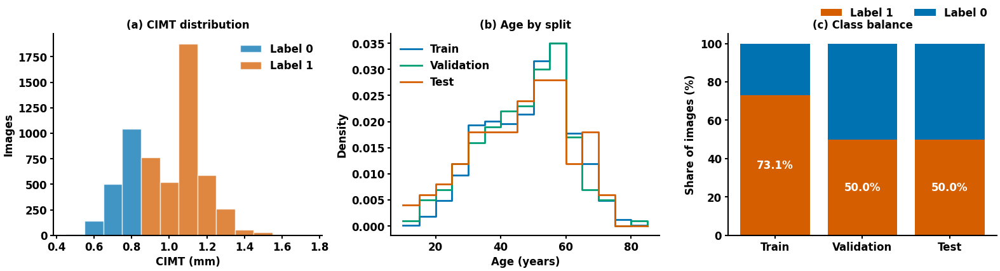

In [3]:
def get_patient_id(base_name):
    return re.sub(r'(_L|_R|_OD|_OS)$', '', base_name, flags=re.IGNORECASE)

pid = lambda n: get_patient_id(os.path.splitext(str(n))[0])
csv_df = pd.read_csv(CFG["csv_path"])
csv_df["patient"] = csv_df["image_name"].map(pid)
csv_df["eye"] = csv_df["image_name"].str.extract(r"_(L|R)\.", expand=False)
print(csv_df.shape); display(csv_df.head())

train_df = csv_df[csv_df["group"] == 1].copy()
val_df   = csv_df[csv_df["group"] == 2].copy()
test_df  = csv_df[csv_df["group"] == 3].copy()
if CFG["debug"]:
    train_df = train_df.sample(32, random_state=0); val_df = val_df.sample(8, random_state=0); test_df = test_df.sample(8, random_state=0)
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))   # row order == loader order

tp_, vp_, sp_ = (set(d["patient"]) for d in (train_df, val_df, test_df))
print(f"patients train/val/test = {len(tp_)}/{len(vp_)}/{len(sp_)} | overlap tv={len(tp_&vp_)} tt={len(tp_&sp_)} vt={len(vp_&sp_)}")
assert not (tp_ & vp_) and not (tp_ & sp_) and not (vp_ & sp_), "Patient leakage between CSV groups!"

SCALER = dict(age_mu=float(train_df["age"].mean()), age_sd=float(train_df["age"].std() + 1e-8),
              t_mu=float(train_df["thickness"].mean()), t_sd=float(train_df["thickness"].std() + 1e-8))
print(SCALER)

# ---------------- Table 1: dataset characteristics ----------------
rows = []
for gid, nm in [(1, "Training"), (2, "Validation"), (3, "Test"), (None, "Total")]:
    d = csv_df if gid is None else csv_df[csv_df["group"] == gid]
    rows.append({"Split": nm, "CSV group": "all" if gid is None else gid, "Images": len(d), "Patients": d["patient"].nunique(),
                 "Label 1 (CIMT ≥ 0.9 mm), n (%)": f"{int((d.label == 1).sum())} ({100 * (d.label == 1).mean():.1f})",
                 "CIMT (mm), mean ± SD": f"{d.thickness.mean():.3f} ± {d.thickness.std():.3f}",
                 "Age (y), mean ± SD": f"{d.True_age.mean():.1f} ± {d.True_age.std():.1f}",
                 "Gender = 1, n (%)": f"{int((d.gender == 1).sum())} ({100 * (d.gender == 1).mean():.1f})",
                 "Right / left eyes": f"{int((d.eye == 'R').sum())} / {int((d.eye == 'L').sum())}"})
save_table(pd.DataFrame(rows), "T1_dataset", "Dataset characteristics and patient-level split (CSV group column).")

# ---------------- Figure 2: dataset distributions ----------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
bins = np.arange(0.45, 1.85, 0.1)
for lab, c in [(0, CB[0]), (1, CB[1])]:
    ax[0].hist(csv_df.loc[csv_df.label == lab, "thickness"], bins=bins, alpha=.75, color=c, edgecolor="white", label=f"Label {lab}")
ax[0].set_xlabel("CIMT (mm)"); ax[0].set_ylabel("Images"); ax[0].set_title("(a) CIMT distribution"); ax[0].legend()
for gid, nm, c in [(1, "Train", CB[0]), (2, "Validation", CB[2]), (3, "Test", CB[1])]:
    h, e = np.histogram(csv_df.loc[csv_df.group == gid, "True_age"], bins=np.arange(10, 95, 5), density=True)
    ax[1].step(e[:-1], h, where="post", color=c, label=nm)
ax[1].set_xlabel("Age (years)"); ax[1].set_ylabel("Density"); ax[1].set_title("(b) Age by split"); ax[1].legend()
sp_names = ["Train", "Validation", "Test"]; fr = [100 * (csv_df.loc[csv_df.group == g, "label"] == 1).mean() for g in (1, 2, 3)]
ax[2].bar(sp_names, fr, color=CB[1], label="Label 1"); ax[2].bar(sp_names, [100 - f for f in fr], bottom=fr, color=CB[0], label="Label 0")
for i, f in enumerate(fr): ax[2].text(i, f / 2, f"{f:.1f}%", ha="center", va="center", color="white")
ax[2].set_ylabel("Share of images (%)"); ax[2].set_title("(c) Class balance"); ax[2].legend(loc="upper right", bbox_to_anchor=(1.0, 1.18), ncol=2)
plt.tight_layout(); save_fig(fig, "F2_dataset_distribution")


## 4. Dataset class and loaders

train=5206 val=400 test=200


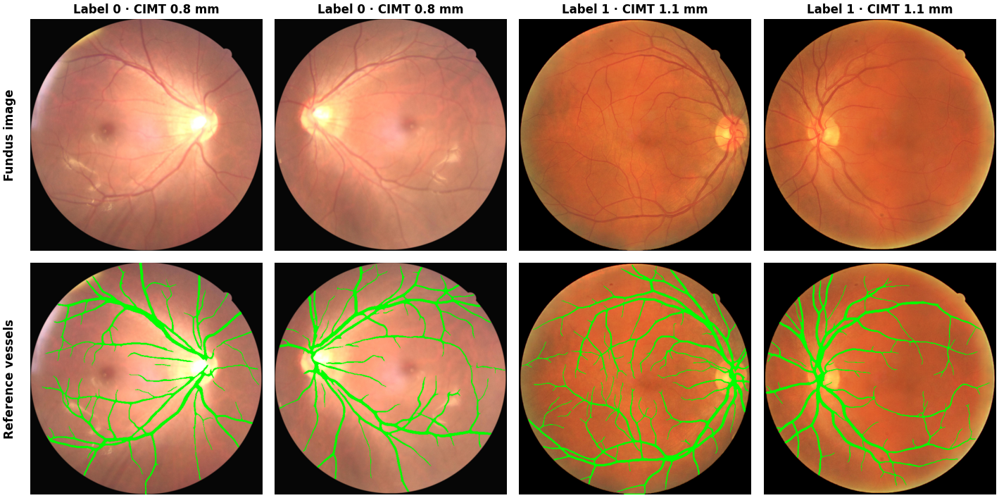

In [4]:
class MTDataset(Dataset):
    def __init__(self, images_dir, masks_dir, df, img_size=512, augment=False, scaler=SCALER):
        self.images_dir, self.masks_dir = images_dir, masks_dir
        self.df = df.reset_index(drop=True)
        self.img_size, self.augment, self.sc = img_size, augment, scaler

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        base = os.path.splitext(str(row["image_name"]))[0]
        s = self.img_size
        img  = Image.open(os.path.join(self.images_dir, base + ".png")).convert("RGB").resize((s, s), Image.BILINEAR)
        mask = Image.open(os.path.join(self.masks_dir,  base + "_mask.png")).convert("L").resize((s, s), Image.NEAREST)
        if self.augment:
            if random.random() < 0.5:
                img, mask = img.transpose(Image.FLIP_LEFT_RIGHT), mask.transpose(Image.FLIP_LEFT_RIGHT)
            if random.random() < 0.5:
                a = random.uniform(-15, 15)
                img, mask = img.rotate(a, resample=Image.BILINEAR), mask.rotate(a, resample=Image.NEAREST)
        img_np  = np.asarray(img, dtype=np.float32) / 255.0
        mask_np = (np.asarray(mask, dtype=np.float32) / 255.0 > 0.5).astype(np.float32)
        if self.augment and random.random() < 0.3:
            rng = np.random.default_rng()
            img_np = np.clip(img_np + rng.normal(0, 0.02, img_np.shape), 0, 1).astype(np.float32)
        age = (float(row["age"]) - self.sc["age_mu"]) / self.sc["age_sd"]
        clin = torch.tensor([age, float(row["gender"])], dtype=torch.float32)
        thick = (float(row["thickness"]) - self.sc["t_mu"]) / self.sc["t_sd"]
        return (torch.from_numpy(img_np).permute(2, 0, 1).contiguous(), torch.from_numpy(mask_np).unsqueeze(0), clin,
                torch.tensor(float(row["label"]), dtype=torch.float32), torch.tensor(thick, dtype=torch.float32))


class CachedMTDataset(MTDataset):
    """Identical samples / augmentation to MTDataset, but every image and mask is decoded + resized ONCE and kept in RAM (uint8).
    Used only for the reduced-protocol ablation / baseline runs, where PNG decoding would otherwise dominate the epoch time."""
    def __init__(self, images_dir, masks_dir, df, img_size=512, augment=False, scaler=SCALER):
        super().__init__(images_dir, masks_dir, df, img_size, augment, scaler)
        from concurrent.futures import ThreadPoolExecutor
        s = img_size
        def load(base):
            im = Image.open(os.path.join(images_dir, base + ".png")).convert("RGB").resize((s, s), Image.BILINEAR)
            mk = Image.open(os.path.join(masks_dir, base + "_mask.png")).convert("L").resize((s, s), Image.NEAREST)
            return np.asarray(im, dtype=np.uint8), np.asarray(mk, dtype=np.uint8)
        bases = [os.path.splitext(str(n))[0] for n in self.df["image_name"]]
        with ThreadPoolExecutor(8) as ex: out = list(ex.map(load, bases))
        self.imgs = np.stack([o[0] for o in out]); self.masks = np.stack([o[1] for o in out])
        print(f"  cached {len(bases)} images at {s}px in RAM ({(self.imgs.nbytes + self.masks.nbytes) / 2**20:.0f} MB)")

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img, mask = Image.fromarray(self.imgs[idx]), Image.fromarray(self.masks[idx])
        if self.augment:
            if random.random() < 0.5:
                img, mask = img.transpose(Image.FLIP_LEFT_RIGHT), mask.transpose(Image.FLIP_LEFT_RIGHT)
            if random.random() < 0.5:
                a = random.uniform(-15, 15)
                img, mask = img.rotate(a, resample=Image.BILINEAR), mask.rotate(a, resample=Image.NEAREST)
        img_np  = np.asarray(img, dtype=np.float32) / 255.0
        mask_np = (np.asarray(mask, dtype=np.float32) / 255.0 > 0.5).astype(np.float32)
        if self.augment and random.random() < 0.3:
            rng = np.random.default_rng()
            img_np = np.clip(img_np + rng.normal(0, 0.02, img_np.shape), 0, 1).astype(np.float32)
        age = (float(row["age"]) - self.sc["age_mu"]) / self.sc["age_sd"]
        clin = torch.tensor([age, float(row["gender"])], dtype=torch.float32)
        thick = (float(row["thickness"]) - self.sc["t_mu"]) / self.sc["t_sd"]
        return (torch.from_numpy(img_np).permute(2, 0, 1).contiguous(), torch.from_numpy(mask_np).unsqueeze(0), clin,
                torch.tensor(float(row["label"]), dtype=torch.float32), torch.tensor(thick, dtype=torch.float32))

def _seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_loaders(img_size, batch_size, cache=False):
    out = {}
    for nm, df, aug, shuf in [("train", train_df, True, True), ("val", val_df, False, False), ("test", test_df, False, False)]:
        ds = (CachedMTDataset if cache else MTDataset)(CFG["images_dir"], CFG["masks_dir"], df, img_size, aug)
        g = torch.Generator(); g.manual_seed(CFG["seed"])
        out[nm] = DataLoader(ds, batch_size=batch_size, shuffle=shuf, drop_last=aug, num_workers=CFG["num_workers"],
                             pin_memory=(device.type == "cuda"), worker_init_fn=_seed_worker, generator=g)
        out[nm + "_ds"] = ds
    return out

LD = make_loaders(CFG["img_size"], CFG["batch_size"])
train_loader, val_loader, test_loader, test_ds = LD["train"], LD["val"], LD["test"], LD["test_ds"]
print(f"train={len(LD['train_ds'])} val={len(LD['val_ds'])} test={len(test_ds)}")

# ---------------- Figure 3: sample images with reference masks ----------------
sel = []
for lab in (0, 1):
    sel += list(np.where(test_df["label"].values == lab)[0][:2])
fig, ax = plt.subplots(2, len(sel), figsize=(3.6 * len(sel), 7.4))
ax = np.atleast_2d(ax).reshape(2, -1)
for j, i in enumerate(sel):
    img, mask, clin, lab, th = test_ds[int(i)]
    im = img.permute(1, 2, 0).numpy(); mk = mask[0].numpy() > .5
    ov = im.copy(); ov[mk] = [0.0, 1.0, 0.0]
    ax[0, j].imshow(im); ax[0, j].set_title(f"Label {int(lab)} · CIMT {test_df.thickness[int(i)]:.1f} mm")
    ax[1, j].imshow(ov)
    ax[0, j].axis("off"); ax[1, j].axis("off")
ax[0, 0].text(-0.06, 0.5, "Fundus image", transform=ax[0, 0].transAxes, rotation=90, va="center", ha="right")
ax[1, 0].text(-0.06, 0.5, "Reference vessels", transform=ax[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); save_fig(fig, "F3_samples")


## 5. Proposed model — MT-Swin-UNet
Swin-Transformer U-Net (patch partition → 3 Swin encoder stages with patch merging → Swin bottleneck → 3 Swin decoder stages with patch expanding and skip concatenation → ×4 final expansion → 1×1 conv). The pooled bottleneck feature is fused with a clinical MLP (age, gender) and feeds the classification and thickness-regression heads.

In [5]:
# ---------------- helpers ----------------
class DropPath(nn.Module):
    def __init__(self, p=0.0):
        super().__init__(); self.p = p
    def forward(self, x):
        if self.p == 0.0 or not self.training: return x
        keep = 1.0 - self.p
        mask = x.new_empty((x.shape[0],) + (1,) * (x.ndim - 1)).bernoulli_(keep)
        return x * mask / keep

class Mlp(nn.Module):
    def __init__(self, dim, ratio=4.0, drop=0.0):
        super().__init__()
        h = int(dim * ratio)
        self.net = nn.Sequential(nn.Linear(dim, h), nn.GELU(), nn.Dropout(drop), nn.Linear(h, dim), nn.Dropout(drop))
    def forward(self, x): return self.net(x)

def window_partition(x, ws):            # (B,H,W,C) -> (B*nW, ws, ws, C)
    B, H, W, C = x.shape
    x = x.reshape(B, H // ws, ws, W // ws, ws, C)
    return x.permute(0, 1, 3, 2, 4, 5).reshape(-1, ws, ws, C)

def window_reverse(w, ws, H, W):        # (B*nW, ws, ws, C) -> (B,H,W,C)
    B = w.shape[0] // ((H // ws) * (W // ws))
    x = w.reshape(B, H // ws, W // ws, ws, ws, -1)
    return x.permute(0, 1, 3, 2, 4, 5).reshape(B, H, W, -1)

class WindowAttention(nn.Module):
    def __init__(self, dim, ws, heads, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        self.ws, self.heads, self.scale = ws, heads, (dim // heads) ** -0.5
        self.rel_table = nn.Parameter(torch.zeros((2 * ws - 1) * (2 * ws - 1), heads))
        trunc_normal_(self.rel_table, std=0.02)
        coords = torch.stack(torch.meshgrid(torch.arange(ws), torch.arange(ws), indexing="ij")).flatten(1)
        rel = (coords[:, :, None] - coords[:, None, :]).permute(1, 2, 0).contiguous()
        rel[:, :, 0] += ws - 1; rel[:, :, 1] += ws - 1; rel[:, :, 0] *= 2 * ws - 1
        self.register_buffer("rel_index", rel.sum(-1))
        self.qkv = nn.Linear(dim, dim * 3)
        self.attn_drop, self.proj = nn.Dropout(attn_drop), nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)

    def forward(self, x, mask=None):
        B_, N, C = x.shape
        qkv = self.qkv(x).reshape(B_, N, 3, self.heads, C // self.heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q * self.scale) @ k.transpose(-2, -1)
        bias = self.rel_table[self.rel_index.view(-1)].view(N, N, -1).permute(2, 0, 1)
        attn = attn + bias.unsqueeze(0)
        if mask is not None:
            nW = mask.shape[0]
            attn = attn.view(B_ // nW, nW, self.heads, N, N) + mask.unsqueeze(1).unsqueeze(0)
            attn = attn.view(-1, self.heads, N, N)
        attn = self.attn_drop(attn.softmax(dim=-1))
        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)
        return self.proj_drop(self.proj(x))

class SwinBlock(nn.Module):
    def __init__(self, dim, res, heads, window, shift, mlp_ratio=4.0, drop_path=0.0, drop=0.0):
        super().__init__()
        self.res = res
        if min(res) <= window:
            window, shift = min(res), 0
        else:
            while res[0] % window or res[1] % window:
                window -= 1
            if shift > 0:
                shift = window // 2
        self.window, self.shift = window, shift
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowAttention(dim, window, heads, drop, drop)
        self.drop_path = DropPath(drop_path)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = Mlp(dim, mlp_ratio, drop)
        if shift > 0:
            H, W = res
            img_mask = torch.zeros(1, H, W, 1); c = 0
            sl = (slice(0, -window), slice(-window, -shift), slice(-shift, None))
            for hs in sl:
                for wsl in sl:
                    img_mask[:, hs, wsl, :] = c; c += 1
            mw = window_partition(img_mask, window).view(-1, window * window)
            m = mw.unsqueeze(1) - mw.unsqueeze(2)
            m = m.masked_fill(m != 0, -100.0).masked_fill(m == 0, 0.0)
            self.register_buffer("attn_mask", m)
        else:
            self.attn_mask = None

    def forward(self, x):
        H, W = self.res; B, L, C = x.shape
        shortcut = x
        x = self.norm1(x).view(B, H, W, C)
        if self.shift > 0:
            x = torch.roll(x, shifts=(-self.shift, -self.shift), dims=(1, 2))
        xw = window_partition(x, self.window).view(-1, self.window * self.window, C)
        aw = self.attn(xw, self.attn_mask).view(-1, self.window, self.window, C)
        x = window_reverse(aw, self.window, H, W)
        if self.shift > 0:
            x = torch.roll(x, shifts=(self.shift, self.shift), dims=(1, 2))
        x = shortcut + self.drop_path(x.reshape(B, H * W, C))
        return x + self.drop_path(self.mlp(self.norm2(x)))

class SwinStage(nn.Module):
    """Swin Transformer Block xN: blocks alternate W-MSA (shift 0) and SW-MSA (shift = window // 2)."""
    def __init__(self, dim, res, depth, heads, window, dpr, drop=0.0, shifted=True):
        super().__init__()
        self.blocks = nn.ModuleList([SwinBlock(dim, res, heads, window, (window // 2) if (shifted and i % 2 == 1) else 0,
                                               drop_path=dpr[i], drop=drop) for i in range(depth)])
    def forward(self, x):
        for b in self.blocks: x = b(x)
        return x

class PatchEmbed(nn.Module):
    def __init__(self, in_ch, dim, patch=4):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, dim, kernel_size=patch, stride=patch); self.norm = nn.LayerNorm(dim)
    def forward(self, x): return self.norm(self.proj(x).flatten(2).transpose(1, 2))

class PatchMerging(nn.Module):
    def __init__(self, res, dim):
        super().__init__()
        self.res = res
        self.norm, self.reduction = nn.LayerNorm(4 * dim), nn.Linear(4 * dim, 2 * dim, bias=False)
    def forward(self, x):
        H, W = self.res; B, L, C = x.shape
        x = x.view(B, H, W, C)
        x = torch.cat([x[:, 0::2, 0::2], x[:, 1::2, 0::2], x[:, 0::2, 1::2], x[:, 1::2, 1::2]], dim=-1).view(B, -1, 4 * C)
        return self.reduction(self.norm(x))

class PatchExpand(nn.Module):
    def __init__(self, res, dim):
        super().__init__()
        self.res = res
        self.expand, self.norm = nn.Linear(dim, 2 * dim, bias=False), nn.LayerNorm(dim // 2)
    def forward(self, x):
        H, W = self.res; B, L, C = x.shape
        x = self.expand(x).view(B, H, W, 2, 2, C // 2).permute(0, 1, 3, 2, 4, 5).reshape(B, 4 * H * W, C // 2)
        return self.norm(x)

class FinalPatchExpand(nn.Module):
    def __init__(self, res, dim, scale=4):
        super().__init__()
        self.res, self.scale = res, scale
        self.expand, self.norm = nn.Linear(dim, scale * scale * dim, bias=False), nn.LayerNorm(dim)
    def forward(self, x):
        H, W = self.res; B, L, C = x.shape; s = self.scale
        x = self.expand(x).view(B, H, W, s, s, C).permute(0, 1, 3, 2, 4, 5).reshape(B, H * s * W * s, C)
        return self.norm(x)

class ClinicalMLP(nn.Module):
    def __init__(self, in_dim=2, hidden=32):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.LeakyReLU(0.01, inplace=True),
                                 nn.Linear(hidden, hidden), nn.LeakyReLU(0.01, inplace=True))
    def forward(self, x): return self.net(x)

# ---------------- MT-Swin-UNet (proposed) ----------------
class SwinUNetMultiTask(nn.Module):
    def __init__(self, img_size=512, in_ch=3, embed_dim=48, patch=4, depths=(2, 2, 2), bottleneck_depth=2,
                 heads=(3, 6, 12, 24), window=8, drop_path=0.1, drop=0.0, clinical_dim=2, clinical_hidden=32, fc_dim=128,
                 shifted=True, use_clinical=True, use_skip=True):
        super().__init__()
        assert img_size % (patch * 8) == 0, "img_size must be divisible by patch*8 (=32)"
        self.use_clinical = use_clinical; self.use_skip = use_skip
        C = embed_dim; r = img_size // patch
        res = [(r // 2 ** i, r // 2 ** i) for i in range(4)]
        dims = [C * 2 ** i for i in range(4)]
        self.dims, self.res, self.out_size = dims, res, r * patch
        n_blocks = 2 * sum(depths) + bottleneck_depth
        dpr = iter(torch.linspace(0, drop_path, n_blocks).tolist())
        take = lambda n: [next(dpr) for _ in range(n)]
        self.patch_embed = PatchEmbed(in_ch, C, patch)
        self.enc = nn.ModuleList([SwinStage(dims[i], res[i], depths[i], heads[i], window, take(depths[i]), drop, shifted) for i in range(3)])
        self.merge = nn.ModuleList([PatchMerging(res[i], dims[i]) for i in range(3)])
        self.bottleneck = SwinStage(dims[3], res[3], bottleneck_depth, heads[3], window, take(bottleneck_depth), drop, shifted)
        self.norm_b = nn.LayerNorm(dims[3])
        lv = (2, 1, 0)
        self.expand = nn.ModuleList([PatchExpand(res[i + 1], dims[i + 1]) for i in lv])
        self.concat_fc = nn.ModuleList([nn.Linear(2 * dims[i], dims[i]) for i in lv])
        self.dec = nn.ModuleList([SwinStage(dims[i], res[i], depths[i], heads[i], window, take(depths[i]), drop, shifted) for i in lv])
        self.final_expand = FinalPatchExpand(res[0], C, scale=patch)
        self.seg_head = nn.Conv2d(C, 1, kernel_size=1)
        self.clinical_mlp = ClinicalMLP(clinical_dim, clinical_hidden)
        self.shared_fc = nn.Sequential(nn.Linear(dims[3] + clinical_hidden, fc_dim), nn.LeakyReLU(0.01, inplace=True), nn.Dropout(0.3))
        self.cls_head = nn.Linear(fc_dim, 1)
        self.reg_head = nn.Linear(fc_dim, 1)
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x, clinical=None, level=4, fuse="mean"):
        B = x.shape[0]
        x = self.patch_embed(x)
        skips = []
        for i in range(3):
            x = self.enc[i](x); skips.append(x); x = self.merge[i](x)
        b = self.bottleneck(x)
        x = b
        for k, i in enumerate((2, 1, 0)):
            x = self.expand[k](x)
            sk = skips[i] if self.use_skip else torch.zeros_like(skips[i])          # ablation: no skip connections
            x = self.concat_fc[k](torch.cat([x, sk], dim=-1))
            x = self.dec[k](x)
        x = self.final_expand(x)
        x = x.transpose(1, 2).reshape(B, -1, self.out_size, self.out_size)
        seg = self.seg_head(x)
        cls_logit = reg_pred = None
        if clinical is not None:
            if not self.use_clinical: clinical = torch.zeros_like(clinical)      # ablation: image-only
            fused = torch.cat([self.norm_b(b).mean(1), self.clinical_mlp(clinical)], dim=1)
            h = self.shared_fc(fused)
            cls_logit, reg_pred = self.cls_head(h).squeeze(1), self.reg_head(h).squeeze(1)
        return dict(seg=seg, deep=[seg], cls=cls_logit, reg=reg_pred, att={})

def build_proposed(img_size, **kw):
    args = dict(embed_dim=CFG["embed_dim"], patch=CFG["patch_size"], window=CFG["window_size"], drop_path=CFG["drop_path"])
    args.update(kw)
    return SwinUNetMultiTask(img_size=img_size, **args)

model = build_proposed(CFG["img_size"]).to(device)
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print("stage dims:", model.dims, "| token grids:", [r[0] for r in model.res])
with torch.no_grad():
    model.eval()
    o = model(torch.randn(2, 3, CFG["img_size"], CFG["img_size"], device=device), torch.randn(2, 2, device=device))
print("seg:", tuple(o["seg"].shape), "| cls:", tuple(o["cls"].shape), "| reg:", tuple(o["reg"].shape))


Total parameters: 6,888,151
stage dims: [48, 96, 192, 384] | token grids: [128, 64, 32, 16]
seg: (2, 1, 512, 512) | cls: (2,) | reg: (2,)


### 5.1 Figure 1 — architecture of the proposed model

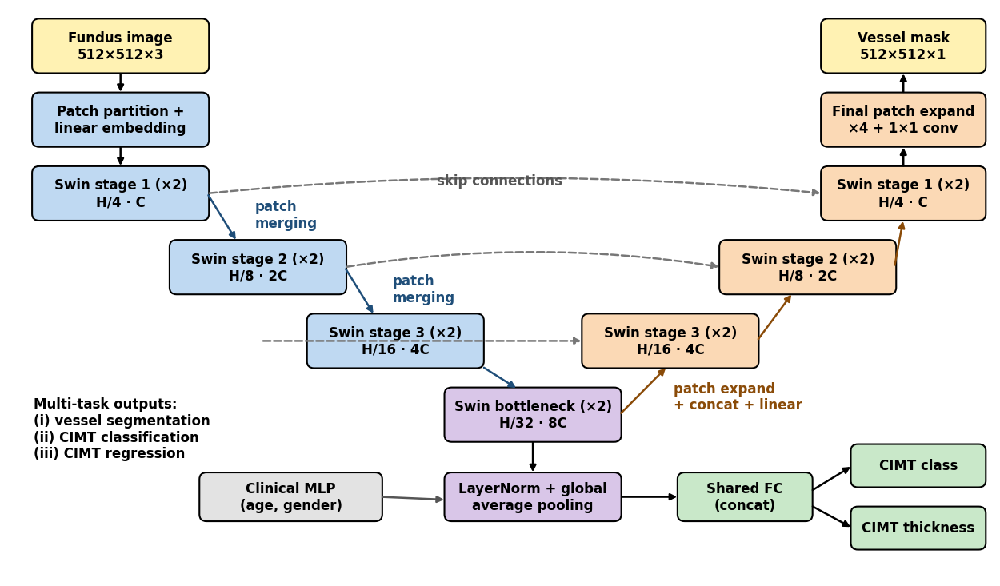

In [6]:
def draw_architecture():
    fig, ax = plt.subplots(figsize=(16, 9.4)); ax.set_xlim(-0.3, 16.3); ax.set_ylim(-0.4, 9.8); ax.axis("off")
    def box(x, y, w, h, txt, fc, ec="black"):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.12", fc=fc, ec=ec, lw=1.5))
        ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=12, fontweight="bold")
    def arrow(p0, p1, ls="-", c="black", rad=0.0):
        ax.annotate("", xy=p1, xytext=p0, arrowprops=dict(arrowstyle="-|>", lw=1.8, color=c, ls=ls, connectionstyle=f"arc3,rad={rad}"))
    enc_c, dec_c, bot_c, head_c, cli_c, io_c = "#BFD9F2", "#FBD9B5", "#D9C6E8", "#C9E8C9", "#E3E3E3", "#FFF2B3"
    box(0.2, 8.6, 2.9, 0.9, "Fundus image\n512×512×3", io_c)
    box(0.2, 7.3, 2.9, 0.9, "Patch partition +\nlinear embedding", enc_c)
    xs = [0.2, 2.5, 4.8]; ys = [6.0, 4.7, 3.4]; labels = ["Swin stage 1 (×2)\nH/4 · C", "Swin stage 2 (×2)\nH/8 · 2C", "Swin stage 3 (×2)\nH/16 · 4C"]
    for x, y, t in zip(xs, ys, labels): box(x, y, 2.9, 0.9, t, enc_c)
    box(7.1, 2.1, 2.9, 0.9, "Swin bottleneck (×2)\nH/32 · 8C", bot_c)
    dx = [11.2, 8.9, 6.6]
    dl = ["Swin stage 1 (×2)\nH/4 · C", "Swin stage 2 (×2)\nH/8 · 2C", "Swin stage 3 (×2)\nH/16 · 4C"]
    # decoder boxes: stage-3 level lowest
    box(9.4, 3.4, 2.9, 0.9, dl[2], dec_c); box(11.7, 4.7, 2.9, 0.9, dl[1], dec_c); box(13.4, 6.0, 2.7, 0.9, dl[0], dec_c)
    box(13.4, 7.3, 2.7, 0.9, "Final patch expand\n×4 + 1×1 conv", dec_c); box(13.4, 8.6, 2.7, 0.9, "Vessel mask\n512×512×1", io_c)
    arrow((1.65, 8.6), (1.65, 8.2)); arrow((1.65, 7.3), (1.65, 6.9))
    arrow((3.1, 6.45), (3.6, 5.6), c="#1f4e79"); arrow((5.4, 5.15), (5.9, 4.3), c="#1f4e79")
    ax.text(3.9, 5.85, "patch\nmerging", fontsize=12, fontweight="bold", color="#1f4e79", ha="left")
    ax.text(6.2, 4.55, "patch\nmerging", fontsize=12, fontweight="bold", color="#1f4e79", ha="left")
    arrow((7.7, 3.4), (8.3, 3.0), c="#1f4e79")
    arrow((10.0, 2.55), (10.8, 3.4), c="#8a4b08"); arrow((12.3, 3.85), (12.9, 4.7), c="#8a4b08"); arrow((14.6, 5.15), (14.75, 6.0), c="#8a4b08")
    ax.text(10.9, 2.65, "patch expand\n+ concat + linear", fontsize=12, fontweight="bold", color="#8a4b08")
    arrow((14.75, 6.9), (14.75, 7.3)); arrow((14.75, 8.2), (14.75, 8.6))
    # skip connections
    arrow((4.0, 3.85), (9.4, 3.85), ls="--", c="#777777"); arrow((5.4, 5.15), (11.7, 5.15), ls="--", c="#777777", rad=-0.08)
    arrow((3.1, 6.45), (13.4, 6.45), ls="--", c="#777777", rad=-0.05)
    ax.text(8.0, 6.6, "skip connections", fontsize=12, fontweight="bold", color="#555555", ha="center")
    # multi-task heads
    box(7.1, 0.7, 2.9, 0.8, "LayerNorm + global\naverage pooling", bot_c)
    box(3.0, 0.7, 3.0, 0.8, "Clinical MLP\n(age, gender)", cli_c)
    box(11.0, 0.7, 2.2, 0.8, "Shared FC\n(concat)", head_c)
    box(13.9, 1.3, 2.2, 0.7, "CIMT class", head_c); box(13.9, 0.2, 2.2, 0.7, "CIMT thickness", head_c)
    arrow((8.55, 2.1), (8.55, 1.5)); arrow((10.0, 1.1), (11.0, 1.1)); arrow((6.0, 1.1), (7.1, 1.05), c="#555555")
    arrow((13.2, 1.2), (13.9, 1.65)); arrow((13.2, 0.95), (13.9, 0.55))
    ax.text(0.2, 2.3, "Multi-task outputs:\n(i) vessel segmentation\n(ii) CIMT classification\n(iii) CIMT regression", fontsize=12, fontweight="bold", va="center")
    return fig

fig = draw_architecture(); save_fig(fig, "F1_architecture")


### 5.2 Baseline networks for the comparison study (defined here, trained only when `RUN_BASELINES = True`)

In [7]:
# ===================== ResUNet++ (Jha et al., 2019) =====================
# Residual units + Squeeze-and-Excitation + ASPP bridge + attention-gated decoder + ASPP output head.
# Layout follows the architecture figure:  Stem -> SE -> Res2 -> SE -> Res3 -> SE -> Res4 -> ASPP(bridge)
#                                          -> 3 x [Attention -> UpSample -> Concat -> Res] -> ASPP -> 1x1 conv -> Sigmoid

class SEBlock(nn.Module):
    """Squeeze & Excitation: global-avg-pool -> FC(C/r) -> ReLU -> FC(C) -> Sigmoid -> channel re-weighting."""
    def __init__(self, ch, ratio=8):
        super().__init__()
        mid = max(ch // ratio, 4)
        self.fc = nn.Sequential(nn.Linear(ch, mid), nn.ReLU(inplace=True),
                                nn.Linear(mid, ch), nn.Sigmoid())

    def forward(self, x):
        w = self.fc(x.mean(dim=(2, 3)))
        return x * w[:, :, None, None]


class StemBlock(nn.Module):
    """Conv3x3 -> BN -> ReLU -> Conv3x3, plus 1x1-conv shortcut, then Addition."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
        )
        self.shortcut = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        return self.conv(x) + self.shortcut(x)


class ResidualBlock(nn.Module):
    """Pre-activation residual unit: BN-ReLU-Conv3x3(stride) -> BN-ReLU-Conv3x3, plus 1x1 shortcut, Addition."""
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.BatchNorm2d(in_ch), nn.ReLU(inplace=False),
            nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
        )
        self.shortcut = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride=stride), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        return self.conv(x) + self.shortcut(x)


class ASPP(nn.Module):
    """Atrous Spatial Pyramid Pooling: parallel 3x3 convs (dilation 1, 6, 12, 18) are summed, then 1x1 fuse.
    `self.fuse` is the layer used as the Grad-CAM target for the bridge."""
    def __init__(self, in_ch, out_ch, rates=(1, 6, 12, 18)):
        super().__init__()
        self.branches = nn.ModuleList([
            nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=r, dilation=r), nn.BatchNorm2d(out_ch))
            for r in rates
        ])
        self.fuse = nn.Sequential(nn.Conv2d(out_ch, out_ch, 1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=False))

    def forward(self, x):
        return self.fuse(sum(b(x) for b in self.branches))


class AttentionBlock(nn.Module):
    """ResUNet++ attention gate. g = skip feature (high-res), x = decoder feature (low-res).
    Output = x re-weighted by an attention map computed from (pooled g) + x."""
    def __init__(self, g_ch, x_ch):
        super().__init__()
        self.g_conv = nn.Sequential(nn.BatchNorm2d(g_ch), nn.ReLU(inplace=False),
                                    nn.Conv2d(g_ch, x_ch, 3, padding=1))
        self.pool = nn.MaxPool2d(2)
        self.x_conv = nn.Sequential(nn.BatchNorm2d(x_ch), nn.ReLU(inplace=False),
                                    nn.Conv2d(x_ch, x_ch, 3, padding=1))
        self.out_conv = nn.Sequential(nn.BatchNorm2d(x_ch), nn.ReLU(inplace=False),
                                      nn.Conv2d(x_ch, x_ch, 3, padding=1))

    def forward(self, g, x):
        g = self.pool(self.g_conv(g))
        if g.shape[-2:] != x.shape[-2:]:
            g = F.interpolate(g, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return self.out_conv(g + self.x_conv(x)) * x


class UpStage(nn.Module):
    """Attention -> UpSampling -> Concatenate(skip) -> Residual block."""
    def __init__(self, x_ch, skip_ch, out_ch):
        super().__init__()
        self.att = AttentionBlock(skip_ch, x_ch)
        self.up = nn.Upsample(scale_factor=2, mode="nearest")
        self.res = ResidualBlock(x_ch + skip_ch, out_ch)

    def forward(self, x, skip):
        x = self.att(skip, x)
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(x, size=skip.shape[-2:], mode="nearest")
        return self.res(torch.cat([x, skip], dim=1))


class ResUNetPP(nn.Module):
    """ResUNet++ for segmentation. Returns raw logits (apply sigmoid outside, like the old DCNUNet).
    Channels with base_ch=16: [16, 32, 64, 128, 256]  (original paper uses base_ch=16 -> 256 at the bridge)."""
    def __init__(self, in_ch=3, out_ch=1, base_ch=16):
        super().__init__()
        f = [base_ch * 2 ** i for i in range(5)]
        self.f = f
        # encoder
        self.stem = StemBlock(in_ch, f[0]);          self.se1 = SEBlock(f[0])
        self.enc2 = ResidualBlock(f[0], f[1], 2);    self.se2 = SEBlock(f[1])
        self.enc3 = ResidualBlock(f[1], f[2], 2);    self.se3 = SEBlock(f[2])
        self.enc4 = ResidualBlock(f[2], f[3], 2)
        # bridge
        self.aspp = ASPP(f[3], f[4])
        # decoder
        self.dec1 = UpStage(f[4], f[2], f[3])
        self.dec2 = UpStage(f[3], f[1], f[2])
        self.dec3 = UpStage(f[2], f[0], f[1])
        # output head
        self.aspp_out = ASPP(f[1], f[0])
        self.seg_conv = nn.Conv2d(f[0], out_ch, 1)

    def _forward_features(self, x):
        s1 = self.se1(self.stem(x))
        s2 = self.se2(self.enc2(s1))
        s3 = self.se3(self.enc3(s2))
        b = self.aspp(self.enc4(s3))                 # bridge features (base_ch*16 channels)
        d = self.dec1(b, s3)
        d = self.dec2(d, s2)
        d = self.dec3(d, s1)
        seg_logits = self.seg_conv(self.aspp_out(d))
        return seg_logits, b

    def forward(self, x):
        return self._forward_features(x)[0]


# ===================== DeepLabV3+ (Chen et al., 2018) =====================
# Encoder : ResNet backbone with atrous (dilated) last stage -> output stride 16
#           -> ASPP: 1x1 conv | 3x3 r=6 | 3x3 r=12 | 3x3 r=18 | image pooling -> concat -> 1x1 conv
# Decoder : upsample x4 -> concat with 1x1-conv'd low-level features (layer1, stride 4) -> 3x3 conv -> upsample x4
import torchvision

class ASPPModule(nn.Module):
    """Atrous Spatial Pyramid Pooling (figure): 1x1, 3x3(r=6), 3x3(r=12), 3x3(r=18), image pooling -> concat -> 1x1 conv.
    `self.fuse` (1x1 conv + BN + ReLU) is the Grad-CAM target."""
    def __init__(self, in_ch, out_ch=256, rates=(6, 12, 18), dropout=0.1):
        super().__init__()
        def cbr(k, d):
            return nn.Sequential(nn.Conv2d(in_ch, out_ch, k, padding=0 if k == 1 else d, dilation=d, bias=False),
                                 nn.BatchNorm2d(out_ch), nn.ReLU(inplace=False))
        self.branches = nn.ModuleList([cbr(1, 1)] + [cbr(3, r) for r in rates])
        # image pooling branch (no BN: its feature map is 1x1, BN would fail with batch size 1)
        self.image_pool = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.ReLU(inplace=False))
        self.fuse = nn.Sequential(nn.Conv2d(out_ch * (len(rates) + 2), out_ch, 1, bias=False),
                                  nn.BatchNorm2d(out_ch), nn.ReLU(inplace=False))
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()

    def forward(self, x):
        outs = [b(x) for b in self.branches]
        outs.append(F.interpolate(self.image_pool(x), size=x.shape[-2:], mode="bilinear", align_corners=False))
        return self.drop(self.fuse(torch.cat(outs, dim=1)))


class DeepLabV3Plus(nn.Module):
    """DeepLabV3+ for binary segmentation. Returns raw logits at input resolution (apply sigmoid outside).
    backbone: 'resnet50' | 'resnet101'. pretrained=True needs internet (ImageNet weights); default False (from scratch).
    Input is expected in [0,1]; ImageNet mean/std normalisation is done inside the model."""
    def __init__(self, in_ch=3, out_ch=1, backbone="resnet50", pretrained=False, aspp_ch=256, low_ch=48):
        super().__init__()
        assert backbone in ("resnet50", "resnet101"), "dilated torchvision ResNets: resnet50 / resnet101"
        weights = None
        if pretrained:
            weights = "IMAGENET1K_V2" if backbone == "resnet50" else "IMAGENET1K_V2"
        net = getattr(torchvision.models, backbone)(weights=weights, replace_stride_with_dilation=[False, False, True])
        if in_ch != 3:
            net.conv1 = nn.Conv2d(in_ch, 64, 7, stride=2, padding=3, bias=False)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = net.layer1, net.layer2, net.layer3, net.layer4
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        self.aspp_ch = aspp_ch
        self.aspp = ASPPModule(2048, aspp_ch)
        self.low_proj = nn.Sequential(nn.Conv2d(256, low_ch, 1, bias=False), nn.BatchNorm2d(low_ch), nn.ReLU(inplace=False))
        self.dec_conv = nn.Sequential(nn.Conv2d(aspp_ch + low_ch, aspp_ch, 3, padding=1, bias=False),
                                      nn.BatchNorm2d(aspp_ch), nn.ReLU(inplace=False), nn.Dropout2d(0.1))
        self.seg_conv = nn.Conv2d(aspp_ch, out_ch, 1)

    def _forward_features(self, x):
        size = x.shape[-2:]
        if x.shape[1] == 3: x = (x - self.mean) / self.std
        low = self.layer1(self.stem(x))                       # stride 4, 256 ch
        high = self.layer4(self.layer3(self.layer2(low)))     # stride 16 (dilated), 2048 ch
        b = self.aspp(high)                                   # ASPP output (aspp_ch channels)
        up = F.interpolate(b, size=low.shape[-2:], mode="bilinear", align_corners=False)   # upsample x4
        d = self.dec_conv(torch.cat([up, self.low_proj(low)], dim=1))
        seg = F.interpolate(self.seg_conv(d), size=size, mode="bilinear", align_corners=False)  # upsample x4
        return seg, b

    def forward(self, x):
        return self._forward_features(x)[0]


# ===================== TransUNet (Chen et al., 2021) =====================
# CNN (ResNet-50 hybrid encoder) -> 1x1 linear projection -> Transformer encoder (n = 12 layers)
# -> reshape (D, H/16, W/16) -> Conv3x3+ReLU (512) -> cascaded upsampler with CNN skips at 1/8, 1/4, 1/2 -> seg head.
import torchvision

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, dim, heads, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        assert dim % heads == 0
        self.h, self.dh = heads, dim // heads
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)
        self.attn_drop, self.proj_drop = attn_drop, nn.Dropout(proj_drop)

    def forward(self, x):                                   # x: (B, N, D)
        B, N, D = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, self.dh).permute(2, 0, 3, 1, 4)
        if hasattr(F, "scaled_dot_product_attention"):
            o = F.scaled_dot_product_attention(q, k, v, dropout_p=self.attn_drop if self.training else 0.0)
        else:
            a = (q @ k.transpose(-2, -1)) / (self.dh ** 0.5)
            o = F.dropout(a.softmax(-1), self.attn_drop, self.training) @ v
        return self.proj_drop(self.proj(o.transpose(1, 2).reshape(B, N, D)))


class TransformerLayer(nn.Module):
    """Figure (a): LayerNorm -> MSA -> (+) -> LayerNorm -> MLP -> (+)."""
    def __init__(self, dim, heads, mlp_ratio=4.0, drop=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = MultiHeadSelfAttention(dim, heads, drop, drop)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = nn.Sequential(nn.Linear(dim, int(dim * mlp_ratio)), nn.GELU(), nn.Dropout(drop),
                                 nn.Linear(int(dim * mlp_ratio), dim), nn.Dropout(drop))

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))


def _conv_bn_relu(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=False))


class TUDecoderBlock(nn.Module):
    """Upsample x2 -> concat CNN skip (if any) -> Conv3x3+ReLU x2."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(_conv_bn_relu(in_ch + skip_ch, out_ch), _conv_bn_relu(out_ch, out_ch))

    def forward(self, x, skip=None):
        if skip is not None:
            x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            x = torch.cat([x, skip], dim=1)
        else:
            x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        return self.conv(x)


class TransUNet(nn.Module):
    """TransUNet (R50-hybrid) for binary segmentation; returns raw logits at input resolution.
    Defaults use a ViT-Small-sized Transformer (embed_dim=384, 6 heads, 12 layers) to fit a Kaggle GPU;
    the paper's ViT-Base setting is embed_dim=768, heads=12.  pretrained=True needs internet (ImageNet R50).
    Input in [0,1]; ImageNet mean/std normalisation is applied inside the model."""
    def __init__(self, in_ch=3, out_ch=1, img_size=512, embed_dim=384, depth=12, heads=6,
                 mlp_ratio=4.0, drop=0.1, pretrained=False):
        super().__init__()
        r50 = torchvision.models.resnet50(weights="IMAGENET1K_V2" if pretrained else None)
        if in_ch != 3:
            r50.conv1 = nn.Conv2d(in_ch, 64, 7, stride=2, padding=3, bias=False)
        self.stem = nn.Sequential(r50.conv1, r50.bn1, r50.relu)        # 64 ch  @ 1/2
        self.maxpool = r50.maxpool
        self.layer1, self.layer2, self.layer3 = r50.layer1, r50.layer2, r50.layer3   # 256@1/4, 512@1/8, 1024@1/16
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        # Linear projection of the CNN feature map (patch size 1 on the H/16 grid)
        self.patch_embed = nn.Conv2d(1024, embed_dim, kernel_size=1)
        self.grid = max(img_size // 16, 1)
        self.pos_embed = nn.Parameter(torch.zeros(1, self.grid * self.grid, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.pos_drop = nn.Dropout(drop)
        self.blocks = nn.ModuleList([TransformerLayer(embed_dim, heads, mlp_ratio, drop) for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim, eps=1e-6)
        # reshape -> Conv3x3+ReLU (512 ch @ 1/16)   [bridge / Grad-CAM target]
        self.conv_more = _conv_bn_relu(embed_dim, 512)
        self.bridge_ch = 512
        # cascaded upsampler: 256@1/8, 128@1/4, 64@1/2, 16@1
        self.dec1 = TUDecoderBlock(512, 512, 256)
        self.dec2 = TUDecoderBlock(256, 256, 128)
        self.dec3 = TUDecoderBlock(128, 64, 64)
        self.dec4 = TUDecoderBlock(64, 0, 16)
        self.seg_conv = nn.Conv2d(16, out_ch, 3, padding=1)             # segmentation head

    def _pos(self, h, w):
        if h == self.grid and w == self.grid:
            return self.pos_embed
        p = self.pos_embed.transpose(1, 2).reshape(1, -1, self.grid, self.grid)
        p = F.interpolate(p, size=(h, w), mode="bilinear", align_corners=False)
        return p.flatten(2).transpose(1, 2)

    def _forward_features(self, x):
        size = x.shape[-2:]
        if x.shape[1] == 3: x = (x - self.mean) / self.std
        f1 = self.stem(x)                       # 1/2
        f2 = self.layer1(self.maxpool(f1))      # 1/4
        f3 = self.layer2(f2)                    # 1/8
        f4 = self.layer3(f3)                    # 1/16
        t = self.patch_embed(f4)
        B, D, h, w = t.shape
        t = self.pos_drop(t.flatten(2).transpose(1, 2) + self._pos(h, w))
        for blk in self.blocks: t = blk(t)
        t = self.norm(t).transpose(1, 2).reshape(B, D, h, w)            # reshape -> (D, H/16, W/16)
        b = self.conv_more(t)
        d = self.dec1(b, f3); d = self.dec2(d, f2); d = self.dec3(d, f1); d = self.dec4(d)
        seg = self.seg_conv(d)
        if seg.shape[-2:] != size:
            seg = F.interpolate(seg, size=size, mode="bilinear", align_corners=False)
        return seg, b

    def forward(self, x):
        return self._forward_features(x)[0]


# ===================== SegFormer (Xie et al., 2021) =====================
# Hierarchical Mix Transformer (MiT) encoder: Overlap Patch Embedding -> N x [Efficient Self-Attn + Mix-FFN] per stage,
# features at 1/4, 1/8, 1/16, 1/32 (no positional encoding) -> lightweight all-MLP decoder
# (per-scale MLP -> upsample to 1/4 -> concat -> MLP fuse -> classifier) -> upsample to input size.
import math

class DropPath(nn.Module):
    def __init__(self, p=0.0):
        super().__init__(); self.p = p
    def forward(self, x):
        if self.p == 0.0 or not self.training: return x
        keep = 1 - self.p
        mask = x.new_empty((x.shape[0],) + (1,) * (x.ndim - 1)).bernoulli_(keep)
        return x * mask / keep


class OverlapPatchEmbed(nn.Module):
    """Overlapping patch embedding (conv with stride < kernel) + LayerNorm. Returns tokens (B, N, C) and (H, W)."""
    def __init__(self, in_ch, out_ch, k, s):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, out_ch, k, stride=s, padding=k // 2)
        self.norm = nn.LayerNorm(out_ch)
    def forward(self, x):
        x = self.proj(x); _, _, H, W = x.shape
        return self.norm(x.flatten(2).transpose(1, 2)), H, W


class EfficientSelfAttention(nn.Module):
    """Self-attention whose keys/values are spatially reduced by sr_ratio (strided conv) -> O(N^2/R) cost."""
    def __init__(self, dim, heads, sr_ratio, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        assert dim % heads == 0
        self.h, self.dh, self.sr_ratio = heads, dim // heads, sr_ratio
        self.q = nn.Linear(dim, dim); self.kv = nn.Linear(dim, dim * 2); self.proj = nn.Linear(dim, dim)
        self.attn_drop, self.proj_drop = attn_drop, nn.Dropout(proj_drop)
        if sr_ratio > 1:
            self.sr = nn.Conv2d(dim, dim, sr_ratio, stride=sr_ratio); self.sr_norm = nn.LayerNorm(dim)
        self._nkv = 0
    def forward(self, x, H, W):
        B, N, C = x.shape
        q = self.q(x).reshape(B, N, self.h, self.dh).transpose(1, 2)
        if self.sr_ratio > 1:
            xr = self.sr(x.transpose(1, 2).reshape(B, C, H, W)).reshape(B, C, -1).transpose(1, 2)
            xr = self.sr_norm(xr)
        else:
            xr = x
        self._nkv = xr.shape[1]
        k, v = self.kv(xr).reshape(B, -1, 2, self.h, self.dh).permute(2, 0, 3, 1, 4)
        if hasattr(F, "scaled_dot_product_attention"):
            o = F.scaled_dot_product_attention(q, k, v, dropout_p=self.attn_drop if self.training else 0.0)
        else:
            a = (q @ k.transpose(-2, -1)) / math.sqrt(self.dh)
            o = F.dropout(a.softmax(-1), self.attn_drop, self.training) @ v
        return self.proj_drop(self.proj(o.transpose(1, 2).reshape(B, N, C)))


class MixFFN(nn.Module):
    """Mix-FFN: MLP -> 3x3 depth-wise conv (zero-padding leaks position info, so no positional encoding) -> GELU -> MLP."""
    def __init__(self, dim, ratio=4, drop=0.0):
        super().__init__()
        hid = dim * ratio
        self.fc1 = nn.Linear(dim, hid)
        self.dw = nn.Conv2d(hid, hid, 3, padding=1, groups=hid)
        self.act = nn.GELU(); self.fc2 = nn.Linear(hid, dim); self.drop = nn.Dropout(drop)
    def forward(self, x, H, W):
        x = self.fc1(x); B, N, C = x.shape
        x = self.dw(x.transpose(1, 2).reshape(B, C, H, W)).flatten(2).transpose(1, 2)
        return self.drop(self.fc2(self.drop(self.act(x))))


class MiTBlock(nn.Module):
    def __init__(self, dim, heads, sr_ratio, mlp_ratio, drop, drop_path):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim); self.attn = EfficientSelfAttention(dim, heads, sr_ratio, drop, drop)
        self.norm2 = nn.LayerNorm(dim); self.ffn = MixFFN(dim, mlp_ratio, drop)
        self.dp = DropPath(drop_path)
    def forward(self, x, H, W):
        x = x + self.dp(self.attn(self.norm1(x), H, W))
        return x + self.dp(self.ffn(self.norm2(x), H, W))


MIT_CFG = {   # dims, heads, depths, sr_ratios
    "b0": dict(dims=(32, 64, 160, 256),  heads=(1, 2, 5, 8), depths=(2, 2, 2, 2),  sr=(8, 4, 2, 1)),
    "b1": dict(dims=(64, 128, 320, 512), heads=(1, 2, 5, 8), depths=(2, 2, 2, 2),  sr=(8, 4, 2, 1)),
    "b2": dict(dims=(64, 128, 320, 512), heads=(1, 2, 5, 8), depths=(3, 4, 6, 3),  sr=(8, 4, 2, 1)),
}


class SegFormer(nn.Module):
    """SegFormer (MiT encoder + all-MLP decoder) for binary segmentation. Returns raw logits at input resolution.
    variant: 'b0' (3.7M, light) | 'b1' | 'b2' (25M). Trained from scratch here (no ImageNet weights).
    Input in [0,1]; ImageNet mean/std normalisation is applied inside the model."""
    def __init__(self, in_ch=3, out_ch=1, variant="b2", decoder_dim=256, mlp_ratio=4, drop=0.0, drop_path=0.1, dec_drop=0.1):
        super().__init__()
        cfg = MIT_CFG[variant]; dims = cfg["dims"]; self.dims = dims
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        dpr = torch.linspace(0, drop_path, sum(cfg["depths"])).tolist(); c = 0
        self.embeds, self.stages, self.norms = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()
        prev = in_ch
        for i in range(4):
            k, s = (7, 4) if i == 0 else (3, 2)
            self.embeds.append(OverlapPatchEmbed(prev, dims[i], k, s))
            self.stages.append(nn.ModuleList([MiTBlock(dims[i], cfg["heads"][i], cfg["sr"][i], mlp_ratio, drop, dpr[c + j])
                                              for j in range(cfg["depths"][i])]))
            self.norms.append(nn.LayerNorm(dims[i])); c += cfg["depths"][i]; prev = dims[i]
        # all-MLP decoder: per-scale linear (1x1 conv) -> upsample -> concat -> fuse MLP -> classifier
        self.dec_mlps = nn.ModuleList([nn.Conv2d(d, decoder_dim, 1) for d in dims])
        self.fuse = nn.Sequential(nn.Conv2d(4 * decoder_dim, decoder_dim, 1, bias=False),
                                  nn.BatchNorm2d(decoder_dim), nn.ReLU(inplace=False))   # bridge / Grad-CAM target
        self.dec_drop = nn.Dropout2d(dec_drop)
        self.seg_conv = nn.Conv2d(decoder_dim, out_ch, 1)
        self.bridge_ch = decoder_dim
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Conv2d):
            fan_out = m.kernel_size[0] * m.kernel_size[1] * m.out_channels // m.groups
            nn.init.normal_(m.weight, 0, math.sqrt(2.0 / fan_out))
            if m.bias is not None: nn.init.zeros_(m.bias)

    def _forward_features(self, x):
        size = x.shape[-2:]
        if x.shape[1] == 3: x = (x - self.mean) / self.std
        feats = []
        for emb, blocks, norm in zip(self.embeds, self.stages, self.norms):
            x, H, W = emb(x)
            for blk in blocks: x = blk(x, H, W)
            x = norm(x).transpose(1, 2).reshape(x.shape[0], -1, H, W)
            feats.append(x)
        tgt = feats[0].shape[-2:]
        ups = [F.interpolate(m(f), size=tgt, mode="bilinear", align_corners=False) if i else m(f)
               for i, (m, f) in enumerate(zip(self.dec_mlps, feats))]
        b = self.fuse(torch.cat(ups[::-1], dim=1))                                   # H/4 x W/4 x C
        seg = F.interpolate(self.seg_conv(self.dec_drop(b)), size=size, mode="bilinear", align_corners=False)
        return seg, b

    def forward(self, x):
        return self._forward_features(x)[0]


# ---------------- plain U-Net / Attention U-Net (written here) ----------------
def _cbr(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
class DoubleConv(nn.Module):
    def __init__(self, i, o): super().__init__(); self.net = nn.Sequential(_cbr(i, o), _cbr(o, o))
    def forward(self, x): return self.net(x)

class AttGate(nn.Module):
    """Additive attention gate of Attention U-Net (Oktay et al., 2018)."""
    def __init__(self, Fg, Fl, Fi):
        super().__init__()
        self.Wg = nn.Sequential(nn.Conv2d(Fg, Fi, 1), nn.BatchNorm2d(Fi)); self.Wx = nn.Sequential(nn.Conv2d(Fl, Fi, 1), nn.BatchNorm2d(Fi))
        self.psi = nn.Sequential(nn.Conv2d(Fi, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid()); self.relu = nn.ReLU(inplace=True)
    def forward(self, g, x): return x * self.psi(self.relu(self.Wg(g) + self.Wx(x)))

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=32, attention=False):
        super().__init__()
        f = [base * 2 ** i for i in range(5)]
        self.enc = nn.ModuleList([DoubleConv(in_ch, f[0])] + [DoubleConv(f[i], f[i + 1]) for i in range(4)])
        self.pool = nn.MaxPool2d(2)
        self.up = nn.ModuleList([nn.ConvTranspose2d(f[i + 1], f[i], 2, stride=2) for i in range(4)])
        self.gate = nn.ModuleList([AttGate(f[i], f[i], f[i] // 2) for i in range(4)]) if attention else None
        self.dec = nn.ModuleList([DoubleConv(2 * f[i], f[i]) for i in range(4)])
        self.seg_conv = nn.Conv2d(f[0], out_ch, 1); self.bridge_ch = f[4]
    def _forward_features(self, x):
        skips = []
        for i in range(4):
            x = self.enc[i](x); skips.append(x); x = self.pool(x)
        b = self.enc[4](x); x = b
        for i in (3, 2, 1, 0):
            x = self.up[i](x)
            if x.shape[-2:] != skips[i].shape[-2:]: x = F.interpolate(x, size=skips[i].shape[-2:], mode="bilinear", align_corners=False)
            s = self.gate[i](x, skips[i]) if self.gate is not None else skips[i]
            x = self.dec[i](torch.cat([s, x], dim=1))
        return self.seg_conv(x), b
    def forward(self, x): return self._forward_features(x)[0]

class MTWrap(nn.Module):
    """Gives any segmentation network the SAME multi-task heads as the proposed model (fair comparison)."""
    def __init__(self, net, bridge_ch, clinical_dim=2, clinical_hidden=32, fc_dim=128):
        super().__init__()
        self.net = net; self.gap = nn.AdaptiveAvgPool2d(1); self.clinical_mlp = ClinicalMLP(clinical_dim, clinical_hidden)
        self.shared_fc = nn.Sequential(nn.Linear(bridge_ch + clinical_hidden, fc_dim), nn.LeakyReLU(0.01, inplace=True), nn.Dropout(0.3))
        self.cls_head = nn.Linear(fc_dim, 1); self.reg_head = nn.Linear(fc_dim, 1)
    def forward(self, x, clinical=None, level=4, fuse="mean"):
        seg, b = self.net._forward_features(x); cls_logit = reg_pred = None
        if clinical is not None:
            h = self.shared_fc(torch.cat([self.gap(b).flatten(1), self.clinical_mlp(clinical)], dim=1))
            cls_logit, reg_pred = self.cls_head(h).squeeze(1), self.reg_head(h).squeeze(1)
        return dict(seg=seg, deep=[seg], cls=cls_logit, reg=reg_pred, att={})

def make_model(name, img_size):
    if name == PROPOSED:          return build_proposed(img_size)
    if name == "U-Net":           n = UNet(); return MTWrap(n, n.bridge_ch)
    if name == "Attention U-Net": n = UNet(attention=True); return MTWrap(n, n.bridge_ch)
    if name == "ResUNet++":       n = ResUNetPP(3, 1, 16); return MTWrap(n, n.f[4])
    if name == "DeepLabV3+":      n = DeepLabV3Plus(3, 1, "resnet50", False); return MTWrap(n, n.aspp_ch)
    if name == "TransUNet":       n = TransUNet(3, 1, img_size=img_size); return MTWrap(n, n.bridge_ch)
    if name == "SegFormer-B2":    n = SegFormer(3, 1, "b2"); return MTWrap(n, n.bridge_ch)
    raise ValueError(name)

ALL_MODELS = [PROPOSED] + BASELINES
for _n in ALL_MODELS:
    _m = make_model(_n, 128 if CFG["debug"] else 256)
    print(f"{_n:<28s} {sum(p.numel() for p in _m.parameters())/1e6:7.2f} M parameters")
    del _m


MT-Swin-UNet (Proposed)         6.89 M parameters


## 6. Loss and metrics

In [8]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0): super().__init__(); self.smooth = smooth
    def forward(self, logits, t):
        p = torch.sigmoid(logits).flatten(1); t = t.flatten(1)
        inter = (p * t).sum(1)
        return 1 - ((2 * inter + self.smooth) / (p.sum(1) + t.sum(1) + self.smooth)).mean()

class FocalLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2.0): super().__init__(); self.alpha, self.gamma = alpha, gamma
    def forward(self, logits, t):
        p = torch.sigmoid(logits).clamp(1e-6, 1 - 1e-6)
        pos = -self.alpha * (1 - p) ** self.gamma * t * torch.log(p)
        neg = -(1 - self.alpha) * p ** self.gamma * (1 - t) * torch.log(1 - p)
        return (pos + neg).mean()

n_pos, n_neg = int((train_df["label"] == 1).sum()), int((train_df["label"] == 0).sum())
pos_weight = torch.tensor(n_neg / max(n_pos, 1), dtype=torch.float32, device=device)
print(f"pos={n_pos} neg={n_neg} pos_weight={pos_weight.item():.3f}")

class MultiTaskLoss(nn.Module):
    """w_seg * (Dice + lam * Focal) + w_cls * BCE(pos_weight) + w_reg * SmoothL1."""
    def __init__(self, lam, w_seg, w_cls, w_reg, pos_weight):
        super().__init__()
        self.dice, self.focal, self.lam = DiceLoss(), FocalLoss(), lam
        self.bce, self.reg = nn.BCEWithLogitsLoss(pos_weight=pos_weight), nn.SmoothL1Loss()
        self.w = (w_seg, w_cls, w_reg)
    def forward(self, out, masks, labels, thick):
        seg = torch.stack([self.dice(h.float(), masks) + self.lam * self.focal(h.float(), masks) for h in out["deep"]]).mean()
        cls = self.bce(out["cls"].float(), labels)
        reg = self.reg(out["reg"].float(), thick)
        return self.w[0] * seg + self.w[1] * cls + self.w[2] * reg, (seg.item(), cls.item(), reg.item())

criterion = MultiTaskLoss(CFG["lam"], CFG["w_seg"], CFG["w_cls"], CFG["w_reg"], pos_weight)

def per_image_seg(logits, masks, thr=0.5):
    p = (torch.sigmoid(logits.float()) > thr).float().flatten(1); t = masks.flatten(1)
    tp = (p * t).sum(1); fp = (p * (1 - t)).sum(1); fn = ((1 - p) * t).sum(1); tn = ((1 - p) * (1 - t)).sum(1)
    e = 1e-8
    d = dict(Dice=2 * tp / (2 * tp + fp + fn + e), IoU=tp / (tp + fp + fn + e), ACC=(tp + tn) / (tp + tn + fp + fn + e),
             SE=tp / (tp + fn + e), SP=tn / (tn + fp + e))
    return {k: v.cpu().numpy() for k, v in d.items()}

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)

@torch.no_grad()
def evaluate(model, loader, criterion=None, collect_pixels=False, pix_per_img=2000, tf=None, clin_tf=None):
    """tf: image perturbation (robustness); clin_tf: clinical-input perturbation (feature contribution)."""
    model.eval()
    seg = {k: [] for k in ["Dice", "IoU", "ACC", "SE", "SP"]}
    cls_p, cls_t, reg_p, reg_t, pix_p, pix_t = [], [], [], [], [], []
    tot, n = 0.0, 0
    for imgs, masks, clin, labels, thick in loader:
        imgs, masks, clin = imgs.to(device), masks.to(device), clin.to(device)
        labels, thick = labels.to(device), thick.to(device)
        if tf is not None: imgs = tf(imgs)
        if clin_tf is not None: clin = clin_tf(clin)
        with autocast_ctx():
            out = model(imgs, clin)
        if criterion is not None and out["cls"] is not None:
            tot += criterion(out, masks, labels, thick)[0].item() * imgs.size(0)
        n += imgs.size(0)
        for k, v in per_image_seg(out["seg"], masks).items(): seg[k].append(v)
        if out["cls"] is not None:
            cls_p.append(torch.sigmoid(out["cls"].float()).cpu().numpy()); cls_t.append(labels.cpu().numpy())
            reg_p.append(out["reg"].float().cpu().numpy() * SCALER["t_sd"] + SCALER["t_mu"])
            reg_t.append(thick.cpu().numpy() * SCALER["t_sd"] + SCALER["t_mu"])
        if collect_pixels:
            pr = torch.sigmoid(out["seg"].float()).flatten(1); tg = masks.flatten(1)
            idx = torch.randint(0, pr.shape[1], (pix_per_img,), device=pr.device)
            pix_p.append(pr[:, idx].cpu().numpy().ravel()); pix_t.append(tg[:, idx].cpu().numpy().ravel())
    res = dict(seg={k: np.concatenate(v) for k, v in seg.items()}, loss=tot / max(n, 1))
    if cls_p:
        res.update(cls_prob=np.concatenate(cls_p), cls_true=np.concatenate(cls_t),
                   reg_pred=np.concatenate(reg_p), reg_true=np.concatenate(reg_t))
    if collect_pixels:
        res.update(pix_prob=np.concatenate(pix_p), pix_true=np.concatenate(pix_t))
    return res

def summarize(res):
    m = {f"seg_{k}": float(v.mean()) for k, v in res["seg"].items()}
    if "cls_prob" in res:
        y, p = res["cls_true"], res["cls_prob"]
        m["cls_ACC"] = accuracy_score(y, p > 0.5)
        m["cls_AUC"] = roc_auc_score(y, p) if len(np.unique(y)) > 1 else float("nan")
        m["reg_MAE"] = mean_absolute_error(res["reg_true"], res["reg_pred"])
        m["reg_RMSE"] = mean_squared_error(res["reg_true"], res["reg_pred"]) ** 0.5
        m["reg_R2"] = r2_score(res["reg_true"], res["reg_pred"])
    return m


pos=3808 neg=1398 pos_weight=0.367


## 7. Training routine (shared by the main model, the ablations and the baselines)
AdamW (no weight decay on norms / biases / relative-position tables), linear warm-up, ReduceLROnPlateau, mixed precision, gradient clipping. The best epoch is selected on **validation** only.

In [9]:
def fit(model, tag, loaders, epochs, crit, w, lr=None, ckpt_path=None, verbose=True):
    lr = lr or CFG["lr"]
    decay, no_decay = [], []
    for n_, p_ in model.named_parameters():
        (no_decay if (p_.ndim <= 1 or "rel_table" in n_ or n_.endswith(".bias")) else decay).append(p_)
    optimizer = torch.optim.AdamW([dict(params=decay, weight_decay=CFG["weight_decay"]), dict(params=no_decay, weight_decay=0.0)], lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    warm = min(CFG["warmup_epochs"], max(epochs - 1, 0))
    ckpt_path = ckpt_path or os.path.join(CKPT_DIR, re.sub(r"[^A-Za-z0-9]+", "_", tag) + "_best.pth")
    best, hist, t_start = -1e9, [], time.time()
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        if epoch <= warm:
            for g_ in optimizer.param_groups: g_["lr"] = lr * epoch / (warm + 1)
        elif epoch == warm + 1:
            for g_ in optimizer.param_groups: g_["lr"] = lr
        model.train(); tot = seg_t = cls_t = reg_t = 0.0
        for imgs, masks, clin, labels, thick in loaders["train"]:
            imgs, masks, clin = imgs.to(device), masks.to(device), clin.to(device)
            labels, thick = labels.to(device), thick.to(device)
            optimizer.zero_grad(set_to_none=True)
            with autocast_ctx():
                out = model(imgs, clin)
            loss, (s, c, r) = crit(out, masks, labels, thick)
            scaler.scale(loss).backward(); scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            b = imgs.size(0); tot += loss.item() * b; seg_t += s * b; cls_t += c * b; reg_t += r * b
        ntr = len(loaders["train"]) * loaders["train"].batch_size
        vres = evaluate(model, loaders["val"], crit); vm = summarize(vres)
        if epoch > warm: scheduler.step(vres["loss"])
        score = (w[0] > 0) * vm["seg_Dice"] + (w[1] > 0) * vm["cls_ACC"] + (w[2] > 0) * vm["reg_R2"]
        hist.append(dict(epoch=epoch, train_loss=tot / ntr, train_seg=seg_t / ntr, train_cls=cls_t / ntr, train_reg=reg_t / ntr,
                         val_loss=vres["loss"], lr=optimizer.param_groups[0]["lr"], **vm))
        flag = ""
        if score > best:
            best = score; torch.save(model.state_dict(), ckpt_path); flag = "  <- best"
        if verbose:
            print(f"[{tag}] Ep {epoch:03d}/{epochs} ({time.time()-t0:.0f}s) loss {tot/ntr:.3f}/{vres['loss']:.3f} | Dice {vm['seg_Dice']:.4f} | "
                  f"ACC {vm['cls_ACC']:.3f} AUC {vm['cls_AUC']:.3f} | MAE {vm['reg_MAE']:.4f} R2 {vm['reg_R2']:.3f}{flag}")
    hist_df = pd.DataFrame(hist)
    hist_df.attrs["train_minutes"] = (time.time() - t_start) / 60
    return hist_df, ckpt_path


## 8. Main model: train (or load) the proposed MT-Swin-UNet
Set `MAIN_CKPT` in the Config cell to reuse an existing checkpoint.

In [10]:
def _find(name):
    """Look for a file produced by an earlier session: this session's q1 folder first, then any attached /kaggle/input dataset / notebook output."""
    own = os.path.join(CKPT_DIR if name.endswith(".pth") else QDIR, name)
    if os.path.exists(own): return own
    hits = sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True)) if os.path.isdir("/kaggle/input") else []
    return hits[0] if hits else None

ckpt_in = _find("mt_swinunet_main_best.pth") if MAIN_CKPT == "auto" else MAIN_CKPT
hist_in = _find("main_training_history.csv") if MAIN_HISTORY_CSV == "auto" else MAIN_HISTORY_CSV
main_ckpt = ckpt_in or os.path.join(CKPT_DIR, "mt_swinunet_main_best.pth")
hist_df = None
if ckpt_in:
    print("Re-using the already trained main model:", ckpt_in)
    if hist_in and os.path.exists(hist_in): hist_df = pd.read_csv(hist_in); print("training history:", hist_in)
    else: print("(no training-history CSV found -> Figure 4 will be skipped)")
else:
    print("No existing checkpoint found -> training the main model (about 2 h on a T4).")
    hist_df, _ = fit(model, "main", LD, CFG["epochs"], criterion, (CFG["w_seg"], CFG["w_cls"], CFG["w_reg"]), ckpt_path=main_ckpt)
    hist_df.to_csv(os.path.join(QDIR, "main_training_history.csv"), index=False)
model.load_state_dict(torch.load(main_ckpt, map_location=device)); model.eval()
N_PARAMS = sum(p.numel() for p in model.parameters())
print(f"Loaded best checkpoint ({N_PARAMS/1e6:.2f} M parameters).")


No existing checkpoint found -> training the main model (about 2 h on a T4).
[main] Ep 001/30 (478s) loss 1.405/1.548 | Dice 0.6275 | ACC 0.672 AUC 0.751 | MAE 0.1834 R2 -0.020  <- best
[main] Ep 002/30 (227s) loss 1.148/1.331 | Dice 0.7373 | ACC 0.698 AUC 0.786 | MAE 0.1767 R2 0.074  <- best
[main] Ep 003/30 (226s) loss 0.927/1.040 | Dice 0.7793 | ACC 0.777 AUC 0.865 | MAE 0.1380 R2 0.338  <- best
[main] Ep 004/30 (226s) loss 0.849/0.983 | Dice 0.8019 | ACC 0.785 AUC 0.868 | MAE 0.1336 R2 0.377  <- best
[main] Ep 005/30 (226s) loss 0.817/0.954 | Dice 0.8264 | ACC 0.780 AUC 0.869 | MAE 0.1328 R2 0.376  <- best
[main] Ep 006/30 (227s) loss 0.791/1.030 | Dice 0.8361 | ACC 0.775 AUC 0.869 | MAE 0.1406 R2 0.321
[main] Ep 007/30 (226s) loss 0.773/0.933 | Dice 0.8475 | ACC 0.785 AUC 0.869 | MAE 0.1330 R2 0.390  <- best
[main] Ep 008/30 (227s) loss 0.760/0.924 | Dice 0.8607 | ACC 0.785 AUC 0.867 | MAE 0.1336 R2 0.368
[main] Ep 009/30 (227s) loss 0.742/0.908 | Dice 0.8706 | ACC 0.780 AUC 0.870

## 9. Table 2 — implementation details and Table 3 — architecture

In [11]:
# ---------------- Table 2: implementation details ----------------
env = dict(torch=torch.__version__, cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
t2 = [("Backbone", "Swin-Transformer U-Net (patch 4, depths 2-2-2, bottleneck 2, heads 3-6-12-24, window 8, relative position bias, shifted windows)"),
      ("Embedding dimension C", f"{CFG['embed_dim']} (stage dims C, 2C, 4C, 8C)"),
      ("Trainable parameters", f"{N_PARAMS/1e6:.2f} M"),
      ("Input", f"{CFG['img_size']}×{CFG['img_size']} RGB fundus (values in [0,1]) + age (standardised) + gender"),
      ("Outputs", "vessel mask (1×1 conv), CIMT class (BCE, pos_weight = %.3f), CIMT thickness (SmoothL1, standardised target)" % pos_weight.item()),
      ("Segmentation loss", f"Dice + {CFG['lam']} × Focal (α = 0.8, γ = 2)"),
      ("Task weights (seg / cls / reg)", f"{CFG['w_seg']} / {CFG['w_cls']} / {CFG['w_reg']}"),
      ("Optimiser", f"AdamW, lr {CFG['lr']}, weight decay {CFG['weight_decay']} (none on norm / bias / rel-pos), {CFG['warmup_epochs']} warm-up epochs, ReduceLROnPlateau (×0.5, patience 5), grad-clip 1.0"),
      ("Batch size / epochs", f"{CFG['batch_size']} / {CFG['epochs']} (main); {CFG['exp_batch_size']} / {CFG['exp_epochs']} at {CFG['exp_img_size']} px (ablation, baselines)"),
      ("Stochastic depth", str(CFG["drop_path"])),
      ("Augmentation", "horizontal flip (p = .5), rotation ±15° (p = .5), Gaussian noise σ = 0.02 (p = .3)"),
      ("Model selection", "best epoch by validation Dice + classification ACC + thickness R² (active tasks only)"),
      ("Mixed precision", str(USE_AMP)), ("Seed", str(CFG["seed"])),
      ("Split", "CSV group: 1 = train, 2 = validation, 3 = test (patient-level, leakage-checked)"),
      ("Software / hardware", f"PyTorch {env['torch']}, CUDA {env['cuda']}, {env['gpu']}"),
      ("Bootstrap", f"{CFG['n_boot']} patient-level (cluster) resamples for 95 % CIs")]
save_table(pd.DataFrame(t2, columns=["Item", "Setting"]), "T2_implementation", "Implementation details.")

# ---------------- Table 3: architecture / parameters ----------------
def n_params(*mods): return sum(p.numel() for m in mods for p in m.parameters())
names = ["Encoder stage 1", "Encoder stage 2", "Encoder stage 3", "Bottleneck", "Decoder stage 3", "Decoder stage 2", "Decoder stage 1"]
stages = [model.enc[0], model.enc[1], model.enc[2], model.bottleneck, model.dec[0], model.dec[1], model.dec[2]]
rows = []
for nm, st in zip(names, stages):
    b0 = st.blocks[0]
    rows.append({"Stage": nm, "Token grid": f"{b0.res[0]}×{b0.res[1]}", "Dim": b0.norm1.normalized_shape[0], "Heads": b0.attn.heads,
                 "Window": b0.window, "Blocks": len(st.blocks), "Attention": "/".join("SW" if b.shift > 0 else "W" for b in st.blocks),
                 "Params (K)": round(n_params(st) / 1e3, 1)})
arch_df = pd.DataFrame(rows)
comp = {"Patch embedding": n_params(model.patch_embed), "Encoder (Swin + merging)": n_params(model.enc, model.merge),
        "Bottleneck": n_params(model.bottleneck, model.norm_b), "Decoder (expand + concat + Swin)": n_params(model.expand, model.concat_fc, model.dec),
        "Final expand + segmentation head": n_params(model.final_expand, model.seg_head),
        "Clinical MLP + shared FC + cls / reg heads": n_params(model.clinical_mlp, model.shared_fc, model.cls_head, model.reg_head)}
comp_df = pd.DataFrame({"Component": list(comp), "Params (M)": [round(v / 1e6, 3) for v in comp.values()]})
comp_df["Share (%)"] = (100 * comp_df["Params (M)"] / comp_df["Params (M)"].sum()).round(1)
save_table(arch_df, "T3a_architecture_stages", "Stage configuration of MT-Swin-UNet.")
save_table(comp_df, "T3b_parameter_breakdown", "Parameter breakdown of MT-Swin-UNet.")



T2_implementation: Implementation details.


,Item,Setting
0,Backbone,"Swin-Transformer U-Net (patch 4, depths 2-2-2,..."
1,Embedding dimension C,"48 (stage dims C, 2C, 4C, 8C)"
2,Trainable parameters,6.89 M
3,Input,"512×512 RGB fundus (values in [0,1]) + age (st..."
4,Outputs,"vessel mask (1×1 conv), CIMT class (BCE, pos_w..."
5,Segmentation loss,"Dice + 0.5 × Focal (α = 0.8, γ = 2)"
6,Task weights (seg / cls / reg),1.0 / 1.0 / 1.0
7,Optimiser,"AdamW, lr 0.0001, weight decay 0.01 (none on n..."
8,Batch size / epochs,"8 / 30 (main); 8 / 15 at 256 px (ablation, bas..."
9,Stochastic depth,0.1



T3a_architecture_stages: Stage configuration of MT-Swin-UNet.


,Stage,Token grid,Dim,Heads,Window,Blocks,Attention,Params (K)
0,Encoder stage 1,128×128,48,3,8,2,W/SW,57.9
1,Encoder stage 2,64×64,96,6,8,2,W/SW,226.4
2,Encoder stage 3,32×32,192,12,8,2,W/SW,895.1
3,Bottleneck,16×16,384,24,8,2,W/SW,3559.7
4,Decoder stage 3,32×32,192,12,8,2,W/SW,895.1
5,Decoder stage 2,64×64,96,6,8,2,W/SW,226.4
6,Decoder stage 1,128×128,48,3,8,2,W/SW,57.9



T3b_parameter_breakdown: Parameter breakdown of MT-Swin-UNet.


,Component,Params (M),Share (%)
0,Patch embedding,0.002,0.0
1,Encoder (Swin + merging),1.569,22.8
2,Bottleneck,3.560,51.7
3,Decoder (expand + concat + Swin),1.664,24.2
4,Final expand + segmentation head,0.037,0.5
5,Clinical MLP + shared FC + cls / reg heads,0.055,0.8


## 10. Figure 4 — training curves

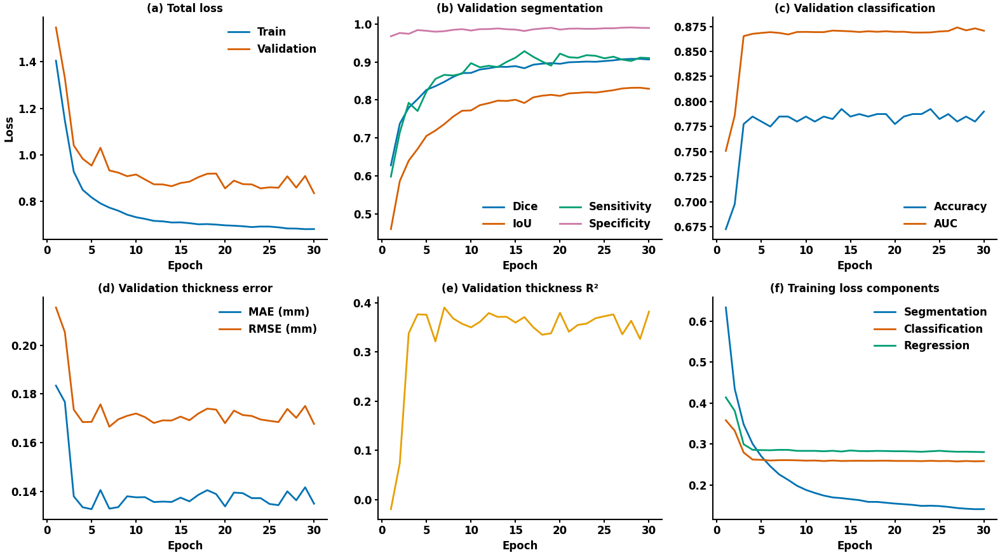

In [12]:
if hist_df is None:
    print("No training history available (set MAIN_HISTORY_CSV when using MAIN_CKPT) -> Figure 4 skipped.")
else:
    fig, ax = plt.subplots(2, 3, figsize=(16, 9))
    e = hist_df.epoch
    ax[0, 0].plot(e, hist_df.train_loss, color=CB[0], label="Train"); ax[0, 0].plot(e, hist_df.val_loss, color=CB[1], label="Validation")
    ax[0, 0].set_title("(a) Total loss"); ax[0, 0].set_ylabel("Loss"); ax[0, 0].legend()
    ax[0, 1].plot(e, hist_df.seg_Dice, color=CB[0], label="Dice"); ax[0, 1].plot(e, hist_df.seg_IoU, color=CB[1], label="IoU")
    ax[0, 1].plot(e, hist_df.seg_SE, color=CB[2], label="Sensitivity"); ax[0, 1].plot(e, hist_df.seg_SP, color=CB[3], label="Specificity")
    ax[0, 1].set_title("(b) Validation segmentation"); ax[0, 1].legend(ncol=2, loc="lower right")
    ax[0, 2].plot(e, hist_df.cls_ACC, color=CB[0], label="Accuracy"); ax[0, 2].plot(e, hist_df.cls_AUC, color=CB[1], label="AUC")
    ax[0, 2].set_title("(c) Validation classification"); ax[0, 2].legend(loc="lower right")
    ax[1, 0].plot(e, hist_df.reg_MAE, color=CB[0], label="MAE (mm)"); ax[1, 0].plot(e, hist_df.reg_RMSE, color=CB[1], label="RMSE (mm)")
    ax[1, 0].set_title("(d) Validation thickness error"); ax[1, 0].legend()
    ax[1, 1].plot(e, hist_df.reg_R2, color=CB[4]); ax[1, 1].set_title("(e) Validation thickness R²")
    ax[1, 2].plot(e, hist_df.train_seg, color=CB[0], label="Segmentation"); ax[1, 2].plot(e, hist_df.train_cls, color=CB[1], label="Classification")
    ax[1, 2].plot(e, hist_df.train_reg, color=CB[2], label="Regression"); ax[1, 2].set_title("(f) Training loss components"); ax[1, 2].legend()
    for a in ax[1]: a.set_xlabel("Epoch")
    for a in ax[0]: a.set_xlabel("Epoch")
    plt.tight_layout(); save_fig(fig, "F4_training_curves")


## 11. Test-set evaluation of the proposed model
Predictions on the held-out **test set (CSV group 3)** with the validation-selected checkpoint. Confidence intervals are **patient-level (cluster) bootstrap** percentiles — both eyes of one patient are resampled together.

In [13]:
res_val  = evaluate(model, LD["val"],  criterion)
res_test = evaluate(model, LD["test"], criterion, collect_pixels=True)
tm = summarize(res_test)
y_te, p_te = res_test["cls_true"].astype(int), res_test["cls_prob"]
t_te, tp_te = res_test["reg_true"], res_test["reg_pred"]
print({k: round(v, 4) for k, v in tm.items()})

# ------------- patient-level cluster bootstrap -------------
test_pids = test_df["patient"].values                 # same order as the test loader (shuffle=False)
def cluster_index(pids):
    g = {}
    for i, p in enumerate(pids): g.setdefault(p, []).append(i)
    return [np.array(v) for v in g.values()]
PIDX = cluster_index(test_pids)

def boot_indices(pidx, n_boot, seed=42):
    rng = np.random.default_rng(seed)
    for _ in range(n_boot):
        yield np.concatenate([pidx[k] for k in rng.integers(0, len(pidx), len(pidx))])

def boot_metrics(fn, *arrs, strat=None, pidx=None, n_boot=None, seed=42):
    """fn(*arrs) -> dict of scalars. Returns (point estimates, {metric: (lo, hi)}) from patient-level bootstrap."""
    pidx = PIDX if pidx is None else pidx; n_boot = n_boot or CFG["n_boot"]
    point = fn(*arrs); store = {k: [] for k in point}
    for ix in boot_indices(pidx, n_boot, seed):
        if strat is not None and len(np.unique(strat[ix])) < 2: continue
        r = fn(*[a[ix] for a in arrs])
        for k, v in r.items(): store[k].append(v)
    ci = {k: (np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5)) if len(v) else (np.nan, np.nan) for k, v in store.items()}
    return point, ci

def ece_score(y, p, n_bins=10):
    idx = np.clip(np.digitize(p, np.linspace(0, 1, n_bins + 1)[1:-1]), 0, n_bins - 1); e = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e

def seg_fn(d, i, a, s, p):
    return dict(Dice=d.mean(), IoU=i.mean(), Accuracy=a.mean(), Sensitivity=s.mean(), Specificity=p.mean())

def cls_fn(y, p, thr=0.5):
    yh = (p >= thr).astype(int)
    tn, fp, fn_, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    sens, spec = tp / max(tp + fn_, 1), tn / max(tn + fp, 1)
    return dict(AUC=roc_auc_score(y, p), AP=average_precision_score(y, p), Accuracy=(tp + tn) / len(y), Balanced_acc=(sens + spec) / 2,
                Sensitivity=sens, Specificity=spec, PPV=tp / max(tp + fp, 1), NPV=tn / max(tn + fn_, 1),
                F1=f1_score(y, yh, zero_division=0), MCC=matthews_corrcoef(y, yh), Brier=brier_score_loss(y, p), ECE=ece_score(y, p))

def reg_fn(t, p):
    return dict(MAE=np.abs(t - p).mean(), RMSE=np.sqrt(((t - p) ** 2).mean()), R2=r2_score(t, p),
                Pearson_r=np.corrcoef(t, p)[0, 1], Within_0p1mm_pct=100 * (np.abs(t - p) <= 0.1 + 1e-9).mean())

S = res_test["seg"]
pt_s, ci_s = boot_metrics(seg_fn, S["Dice"], S["IoU"], S["ACC"], S["SE"], S["SP"])
pt_c, ci_c = boot_metrics(cls_fn, y_te, p_te, strat=y_te)
pt_r, ci_r = boot_metrics(reg_fn, t_te, tp_te)

rows = []
for task, pt, ci in [("Segmentation", pt_s, ci_s), ("CIMT classification", pt_c, ci_c), ("CIMT regression", pt_r, ci_r)]:
    for k, v in pt.items():
        rows.append({"Task": task, "Metric": k.replace("_", " "), "Estimate": round(float(v), 4), "95% CI low": round(float(ci[k][0]), 4),
                     "95% CI high": round(float(ci[k][1]), 4), "Estimate (95% CI)": fmt_ci(v, *ci[k])})
t4 = pd.DataFrame(rows)
save_table(t4, "T4_main_results", f"Test-set results of MT-Swin-UNet (n = {len(test_df)} images, {len(PIDX)} patients) with 95% patient-level bootstrap CIs.")
print(classification_report(y_te, (p_te > .5).astype(int), target_names=["Label 0", "Label 1"]))


{'seg_Dice': 0.9063, 'seg_IoU': 0.8289, 'seg_ACC': 0.9818, 'seg_SE': 0.9111, 'seg_SP': 0.9893, 'cls_ACC': 0.845, 'cls_AUC': np.float64(0.9463), 'reg_MAE': 0.108, 'reg_RMSE': 0.1386, 'reg_R2': 0.4778}

T4_main_results: Test-set results of MT-Swin-UNet (n = 200 images, 100 patients) with 95% patient-level bootstrap CIs.


,Task,Metric,Estimate,95% CI low,95% CI high,Estimate (95% CI)
0,Segmentation,Dice,0.9063,0.9036,0.9088,0.906 (0.904–0.909)
1,Segmentation,IoU,0.8289,0.8246,0.8331,0.829 (0.825–0.833)
2,Segmentation,Accuracy,0.9818,0.9815,0.9821,0.982 (0.981–0.982)
3,Segmentation,Sensitivity,0.9111,0.9074,0.9143,0.911 (0.907–0.914)
4,Segmentation,Specificity,0.9893,0.9890,0.9896,0.989 (0.989–0.990)
5,CIMT classification,AUC,0.9463,0.8994,0.9828,0.946 (0.899–0.983)
6,CIMT classification,AP,0.9499,0.9015,0.9849,0.950 (0.902–0.985)
7,CIMT classification,Accuracy,0.8450,0.7700,0.9100,0.845 (0.770–0.910)
8,CIMT classification,Balanced acc,0.8450,0.7695,0.9094,0.845 (0.770–0.909)
9,CIMT classification,Sensitivity,0.9200,0.8372,0.9811,0.920 (0.837–0.981)


              precision    recall  f1-score   support

     Label 0       0.91      0.77      0.83       100
     Label 1       0.80      0.92      0.86       100

    accuracy                           0.84       200
   macro avg       0.85      0.84      0.84       200
weighted avg       0.85      0.84      0.84       200



### 11.1 Table 5 — classification operating points
The threshold is fixed **on the validation set** (Youden's J) and then applied once to the test set — no test-set tuning.

In [14]:
yv, pv = res_val["cls_true"].astype(int), res_val["cls_prob"]
fpr_v, tpr_v, thr_v = roc_curve(yv, pv)
thr_youden = float(thr_v[np.argmax(tpr_v - fpr_v)])
print(f"Validation Youden threshold = {thr_youden:.3f}")
rows = []
for nm, thr in [("Default (0.5)", 0.5), (f"Youden on validation ({thr_youden:.2f})", thr_youden)]:
    pt, ci = boot_metrics(lambda y, p, t=thr: cls_fn(y, p, t), y_te, p_te, strat=y_te)
    r = {"Operating point": nm}
    for k in ["Sensitivity", "Specificity", "PPV", "NPV", "Accuracy", "Balanced_acc", "F1", "MCC"]:
        r[k.replace("_", " ")] = fmt_ci(pt[k], *ci[k])
    cm = confusion_matrix(y_te, (p_te >= thr).astype(int), labels=[0, 1]).ravel()
    r.update({"TN": int(cm[0]), "FP": int(cm[1]), "FN": int(cm[2]), "TP": int(cm[3])})
    rows.append(r)
save_table(pd.DataFrame(rows), "T5_operating_points", "Classification operating points on the test set (threshold chosen on validation).")


Validation Youden threshold = 0.670

T5_operating_points: Classification operating points on the test set (threshold chosen on validation).


,Operating point,Sensitivity,Specificity,PPV,NPV,Accuracy,Balanced acc,F1,MCC,TN,FP,FN,TP
0,Default (0.5),0.920 (0.837–0.981),0.770 (0.661–0.878),0.800 (0.687–0.893),0.906 (0.806–0.979),0.845 (0.770–0.910),0.845 (0.770–0.909),0.856 (0.777–0.918),0.698 (0.550–0.824),77,23,8,92
1,Youden on validation (0.67),0.820 (0.700–0.917),0.930 (0.857–0.984),0.921 (0.842–0.983),0.838 (0.737–0.926),0.875 (0.810–0.930),0.875 (0.809–0.932),0.868 (0.787–0.929),0.755 (0.625–0.865),93,7,18,82


## 12. Segmentation figures — Figure 5 (qualitative) and Figure 6 (statistics)

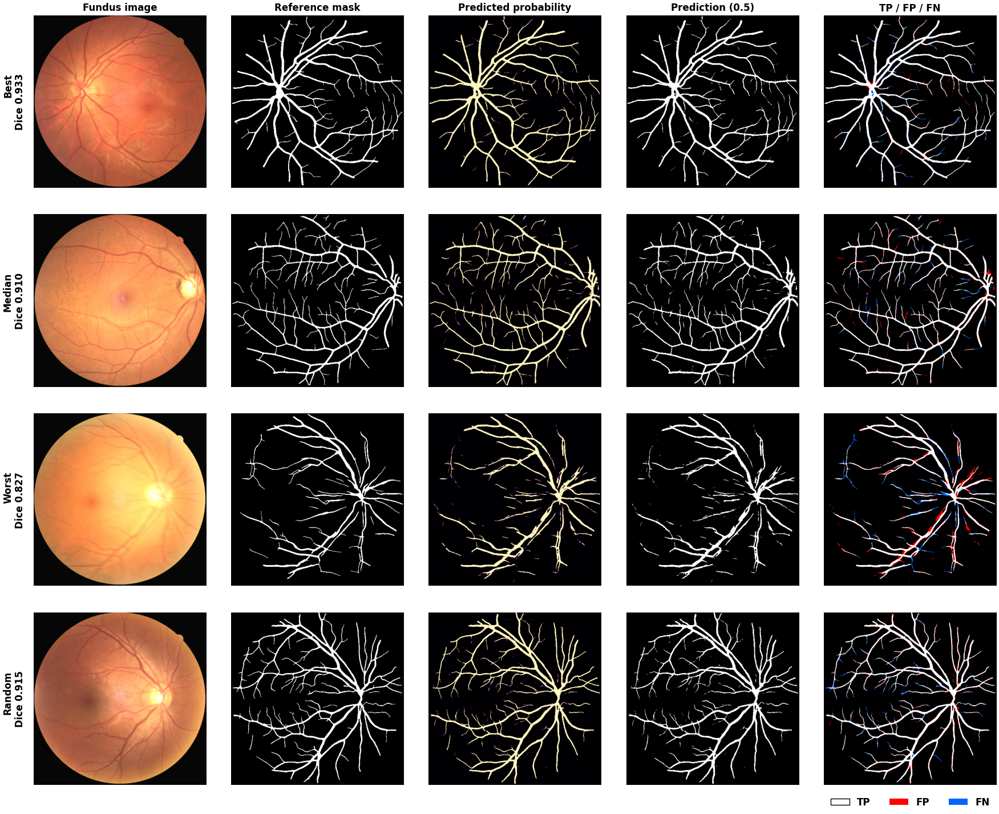

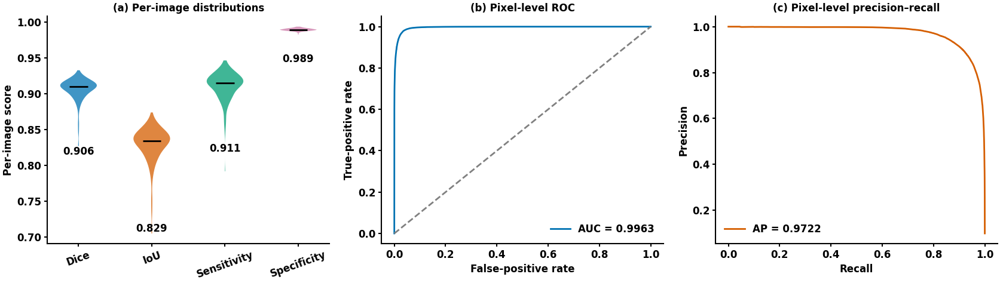

In [15]:
dice_te = res_test["seg"]["Dice"]; order = np.argsort(dice_te)
rng = np.random.default_rng(0)
picks = [("Best", int(order[-1])), ("Median", int(order[len(order) // 2])), ("Worst", int(order[0])), ("Random", int(rng.integers(len(order))))]
cols = ["Fundus image", "Reference mask", "Predicted probability", "Prediction (0.5)", "TP / FP / FN"]
fig, ax = plt.subplots(len(picks), 5, figsize=(18, 3.7 * len(picks)))
for r_i, (tag, idx) in enumerate(picks):
    img, mask, clin, lab, th = test_ds[idx]
    with torch.no_grad(), autocast_ctx():
        out = model(img[None].to(device), clin[None].to(device))
    gt = mask[0].numpy() > 0.5
    prob = torch.sigmoid(out["seg"].float())[0, 0].cpu().numpy(); pred = prob > 0.5
    err = np.zeros(gt.shape + (3,)); err[gt & pred] = 1; err[~gt & pred] = [1, 0, 0]; err[gt & ~pred] = [0, .4, 1]
    ax[r_i, 0].imshow(img.permute(1, 2, 0).numpy()); ax[r_i, 1].imshow(gt, cmap="gray")
    ax[r_i, 2].imshow(prob, cmap="magma", vmin=0, vmax=1); ax[r_i, 3].imshow(pred, cmap="gray"); ax[r_i, 4].imshow(err)
    for a in ax[r_i]: a.axis("off")
    ax[r_i, 0].text(-0.05, 0.5, f"{tag}\nDice {dice_te[idx]:.3f}", transform=ax[r_i, 0].transAxes, rotation=90, va="center", ha="right")
for j, c in enumerate(cols): ax[0, j].set_title(c)
ax[-1, 4].legend(handles=[Patch(fc="white", ec="k", label="TP"), Patch(fc="red", label="FP"), Patch(fc=(0, .4, 1), label="FN")],
                 loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3)
plt.tight_layout(); save_fig(fig, "F5_segmentation_qualitative")

# ---------------- Figure 6: segmentation statistics ----------------
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
data = [S["Dice"], S["IoU"], S["SE"], S["SP"]]; labs = ["Dice", "IoU", "Sensitivity", "Specificity"]
vp = ax[0].violinplot(data, showmedians=True, showextrema=False)
for b, c in zip(vp["bodies"], CB): b.set_facecolor(c); b.set_alpha(.75)
vp["cmedians"].set_color("black")
ax[0].set_xticks(range(1, 5)); ax[0].set_xticklabels(labs, rotation=20); ax[0].set_ylabel("Per-image score"); ax[0].set_title("(a) Per-image distributions")
for i, d in enumerate(data, 1): ax[0].text(i, np.percentile(d, 2) - 0.03, f"{d.mean():.3f}", ha="center", va="top")
fpr, tpr, _ = roc_curve(res_test["pix_true"], res_test["pix_prob"]); pix_auc = roc_auc_score(res_test["pix_true"], res_test["pix_prob"])
ax[1].plot(fpr, tpr, color=CB[0], label=f"AUC = {pix_auc:.4f}")
ax[1].plot([0, 1], [0, 1], "--", color="gray"); ax[1].set_xlabel("False-positive rate"); ax[1].set_ylabel("True-positive rate"); ax[1].set_title("(b) Pixel-level ROC"); ax[1].legend(loc="lower right")
pr_, rc_, _ = precision_recall_curve(res_test["pix_true"], res_test["pix_prob"])
ax[2].plot(rc_, pr_, color=CB[1], label=f"AP = {average_precision_score(res_test['pix_true'], res_test['pix_prob']):.4f}")
ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].set_title("(c) Pixel-level precision–recall"); ax[2].legend(loc="lower left")
plt.tight_layout(); save_fig(fig, "F6_segmentation_statistics")


## 13. Classification figure — Figure 7

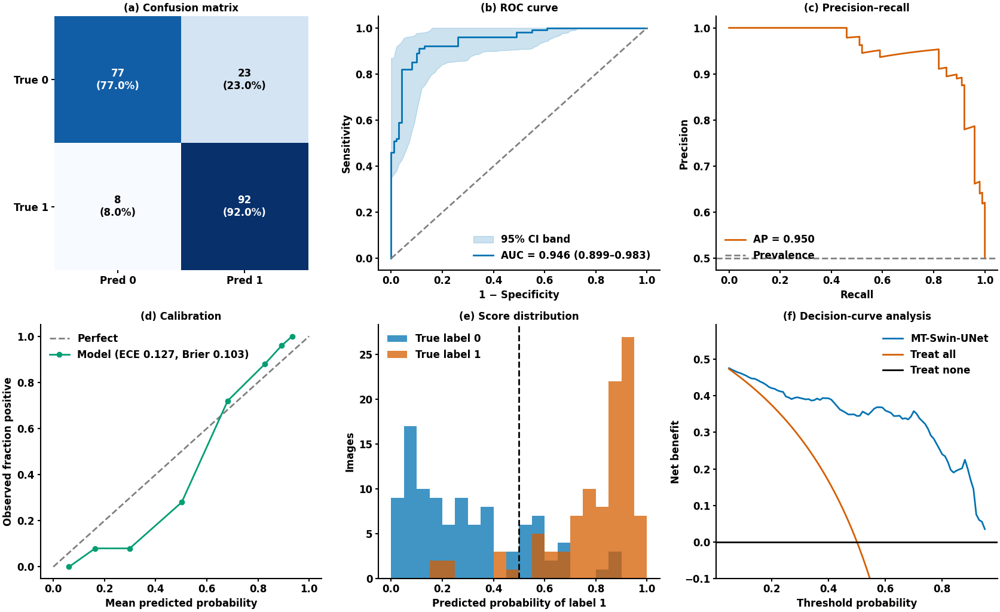

In [16]:
fig, ax = plt.subplots(2, 3, figsize=(17, 10.5))
# (a) confusion matrix
cm = confusion_matrix(y_te, (p_te > .5).astype(int), labels=[0, 1])
ax[0, 0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0, 0].text(j, i, f"{cm[i, j]}\n({100 * cm[i, j] / cm[i].sum():.1f}%)", ha="center", va="center",
                      color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0, 0].set_xticks([0, 1]); ax[0, 0].set_yticks([0, 1]); ax[0, 0].set_xticklabels(["Pred 0", "Pred 1"]); ax[0, 0].set_yticklabels(["True 0", "True 1"])
ax[0, 0].set_title("(a) Confusion matrix"); ax[0, 0].spines[["left", "bottom"]].set_visible(False)
# (b) ROC with bootstrap band
grid = np.linspace(0, 1, 101); tprs = []
for ix in boot_indices(PIDX, min(CFG["n_boot"], 500), 7):
    if len(np.unique(y_te[ix])) < 2: continue
    f_, t_, _ = roc_curve(y_te[ix], p_te[ix]); tprs.append(np.interp(grid, f_, t_))
lo, hi = np.percentile(tprs, 2.5, axis=0), np.percentile(tprs, 97.5, axis=0)
f0, t0, _ = roc_curve(y_te, p_te)
ax[0, 1].fill_between(grid, lo, hi, color=CB[0], alpha=.2, label="95% CI band"); ax[0, 1].plot(f0, t0, color=CB[0], label=f"AUC = {fmt_ci(pt_c['AUC'], *ci_c['AUC'])}")
ax[0, 1].plot([0, 1], [0, 1], "--", color="gray"); ax[0, 1].set_xlabel("1 − Specificity"); ax[0, 1].set_ylabel("Sensitivity"); ax[0, 1].set_title("(b) ROC curve"); ax[0, 1].legend(loc="lower right", fontsize=12)
# (c) PR
pr_, rc_, _ = precision_recall_curve(y_te, p_te)
ax[0, 2].plot(rc_, pr_, color=CB[1], label=f"AP = {pt_c['AP']:.3f}"); ax[0, 2].axhline(y_te.mean(), ls="--", color="gray", label="Prevalence")
ax[0, 2].set_xlabel("Recall"); ax[0, 2].set_ylabel("Precision"); ax[0, 2].set_title("(c) Precision–recall"); ax[0, 2].legend(loc="lower left")
# (d) calibration
fr_, mp_ = calibration_curve(y_te, p_te, n_bins=8, strategy="quantile")
ax[1, 0].plot([0, 1], [0, 1], "--", color="gray", label="Perfect"); ax[1, 0].plot(mp_, fr_, "o-", color=CB[2], label=f"Model (ECE {pt_c['ECE']:.3f}, Brier {pt_c['Brier']:.3f})")
ax[1, 0].set_xlabel("Mean predicted probability"); ax[1, 0].set_ylabel("Observed fraction positive"); ax[1, 0].set_title("(d) Calibration"); ax[1, 0].legend(loc="upper left")
# (e) probability distributions
bins = np.linspace(0, 1, 21)
ax[1, 1].hist(p_te[y_te == 0], bins=bins, alpha=.75, color=CB[0], label="True label 0"); ax[1, 1].hist(p_te[y_te == 1], bins=bins, alpha=.75, color=CB[1], label="True label 1")
ax[1, 1].axvline(0.5, ls="--", color="k"); ax[1, 1].set_xlabel("Predicted probability of label 1"); ax[1, 1].set_ylabel("Images"); ax[1, 1].set_title("(e) Score distribution"); ax[1, 1].legend()
# (f) decision-curve analysis
pts = np.linspace(0.05, 0.95, 91); n_ = len(y_te); prev = y_te.mean()
nb_m = [((p_te >= t) & (y_te == 1)).sum() / n_ - ((p_te >= t) & (y_te == 0)).sum() / n_ * t / (1 - t) for t in pts]
nb_all = [prev - (1 - prev) * t / (1 - t) for t in pts]
ax[1, 2].plot(pts, nb_m, color=CB[0], label="MT-Swin-UNet"); ax[1, 2].plot(pts, nb_all, color=CB[1], label="Treat all"); ax[1, 2].axhline(0, color="k", label="Treat none")
ax[1, 2].set_ylim(-0.1, max(nb_m) * 1.25); ax[1, 2].set_xlabel("Threshold probability"); ax[1, 2].set_ylabel("Net benefit"); ax[1, 2].set_title("(f) Decision-curve analysis"); ax[1, 2].legend()
plt.tight_layout(); save_fig(fig, "F7_classification")


## 14. Regression figure — Figure 8

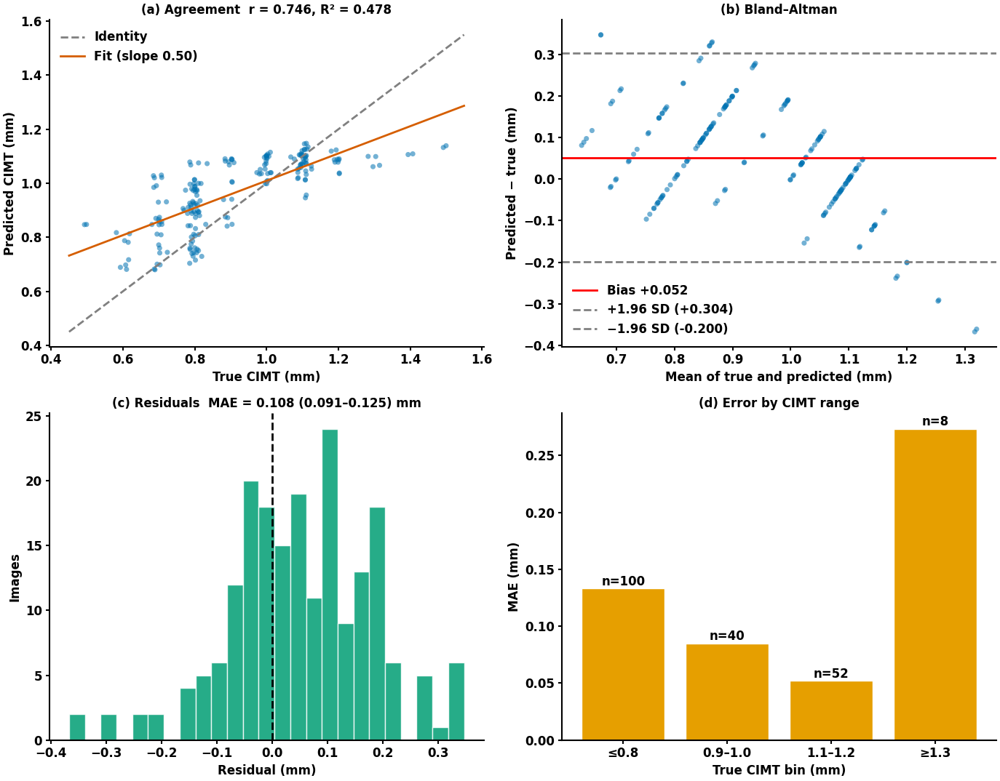

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(14, 11))
jit = np.random.default_rng(1).normal(0, 0.012, len(t_te))
ax[0, 0].scatter(t_te + jit, tp_te, s=26, alpha=.55, color=CB[0], edgecolor="none")
lim = [min(t_te.min(), tp_te.min()) - .05, max(t_te.max(), tp_te.max()) + .05]; ax[0, 0].plot(lim, lim, "--", color="gray", label="Identity")
sl, ic = np.polyfit(t_te, tp_te, 1); ax[0, 0].plot(lim, [sl * l + ic for l in lim], color=CB[1], label=f"Fit (slope {sl:.2f})")
ax[0, 0].set_xlabel("True CIMT (mm)"); ax[0, 0].set_ylabel("Predicted CIMT (mm)")
ax[0, 0].set_title(f"(a) Agreement  r = {pt_r['Pearson_r']:.3f}, R² = {pt_r['R2']:.3f}"); ax[0, 0].legend(loc="upper left")
mean_, diff = (t_te + tp_te) / 2, tp_te - t_te; bias, sd = diff.mean(), diff.std()
ax[0, 1].scatter(mean_, diff, s=26, alpha=.55, color=CB[0], edgecolor="none")
ax[0, 1].axhline(bias, color="r", label=f"Bias {bias:+.3f}"); ax[0, 1].axhline(bias + 1.96 * sd, ls="--", color="gray", label=f"+1.96 SD ({bias + 1.96 * sd:+.3f})")
ax[0, 1].axhline(bias - 1.96 * sd, ls="--", color="gray", label=f"−1.96 SD ({bias - 1.96 * sd:+.3f})")
ax[0, 1].set_xlabel("Mean of true and predicted (mm)"); ax[0, 1].set_ylabel("Predicted − true (mm)"); ax[0, 1].set_title("(b) Bland–Altman"); ax[0, 1].legend(loc="lower left", fontsize=12)
ax[1, 0].hist(diff, bins=25, color=CB[2], alpha=.85, edgecolor="white"); ax[1, 0].axvline(0, color="k", ls="--")
ax[1, 0].set_xlabel("Residual (mm)"); ax[1, 0].set_ylabel("Images"); ax[1, 0].set_title(f"(c) Residuals  MAE = {fmt_ci(pt_r['MAE'], *ci_r['MAE'])} mm")
edges = [0.45, 0.85, 1.05, 1.25, 2.0]; names_ = ["≤0.8", "0.9–1.0", "1.1–1.2", "≥1.3"]
mae_b, n_b = [], []
for a_, b_ in zip(edges[:-1], edges[1:]):
    m_ = (t_te >= a_) & (t_te < b_); mae_b.append(np.abs(diff[m_]).mean() if m_.any() else np.nan); n_b.append(int(m_.sum()))
ax[1, 1].bar(names_, mae_b, color=CB[4], edgecolor="white")
for i, (v, n_) in enumerate(zip(mae_b, n_b)): ax[1, 1].text(i, (v if v == v else 0) + .003, f"n={n_}", ha="center")
ax[1, 1].set_xlabel("True CIMT bin (mm)"); ax[1, 1].set_ylabel("MAE (mm)"); ax[1, 1].set_title("(d) Error by CIMT range")
plt.tight_layout(); save_fig(fig, "F8_regression")


## 15. Explainability — Figure 9 (Grad-CAM) and Figure 10 (t-SNE of the shared embedding)
Grad-CAM is computed on the Swin bottleneck tokens (H/32 grid) for the classification logit and the thickness output; warm colours = regions that increase the predicted CIMT / label-1 evidence.

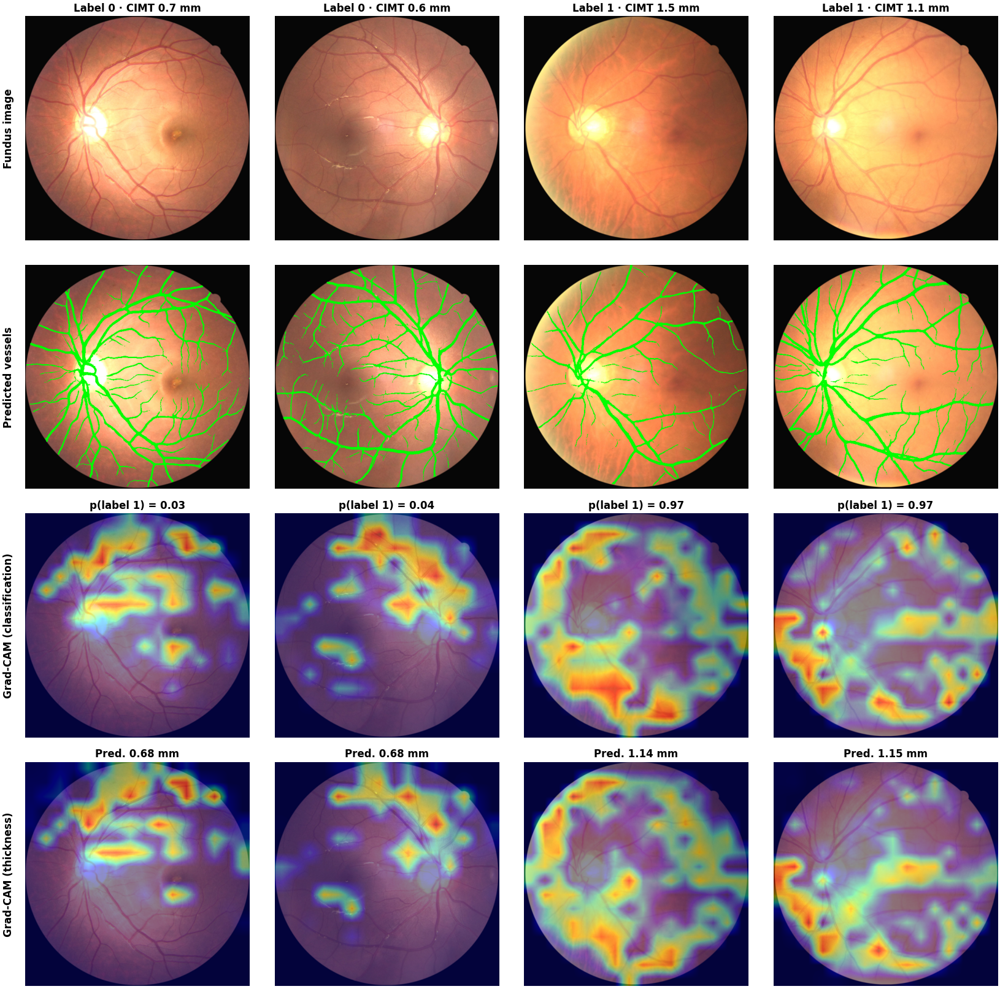

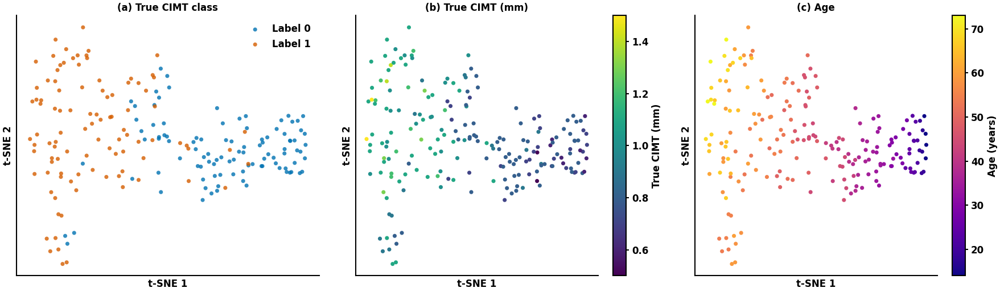

In [18]:
def grad_cams(model, img, clin):
    """Grad-CAM on the bottleneck tokens for the classification logit and the thickness output."""
    model.eval(); store = {}
    def hk(m, i, o):
        o.retain_grad(); store["a"] = o
    h = model.bottleneck.register_forward_hook(hk)
    cams = {}
    try:
        for tgt in ("cls", "reg"):
            model.zero_grad(set_to_none=True)
            with torch.enable_grad():
                out = model(img[None].to(device), clin[None].to(device))
                out[tgt].sum().backward()
            a = store["a"]; g = a.grad                                  # (1, N, C)
            w = g.mean(dim=1, keepdim=True)
            cam = torch.relu((a * w).sum(-1))                           # (1, N)
            n = int(math.sqrt(cam.shape[1])); cam = cam.reshape(1, 1, n, n)
            cam = F.interpolate(cam, size=img.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
            cams[tgt] = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).detach().cpu().numpy()
    finally:
        h.remove(); model.zero_grad(set_to_none=True)
    return cams, out

correct0 = np.where((y_te == 0) & (p_te < .5))[0]; correct1 = np.where((y_te == 1) & (p_te >= .5))[0]
sel = list(correct0[np.argsort(p_te[correct0])[:2]]) + list(correct1[np.argsort(-p_te[correct1])[:2]])
fig, ax = plt.subplots(4, len(sel), figsize=(4.2 * len(sel), 16.4)); ax = np.atleast_2d(ax).reshape(4, -1)
for j, i in enumerate(sel):
    img, mask, clin, lab, th = test_ds[int(i)]
    cams, out = grad_cams(model, img, clin)
    im = img.permute(1, 2, 0).numpy(); seg_pred = (torch.sigmoid(out["seg"].float())[0, 0] > .5).cpu().numpy()
    ov = im.copy(); ov[seg_pred] = [0, 1, 0]
    ax[0, j].imshow(im); ax[0, j].set_title(f"Label {int(lab)} · CIMT {test_df.thickness[int(i)]:.1f} mm")
    ax[1, j].imshow(ov)
    ax[2, j].imshow(im); ax[2, j].imshow(cams["cls"], cmap="jet", alpha=.45)
    ax[3, j].imshow(im); ax[3, j].imshow(cams["reg"], cmap="jet", alpha=.45)
    ax[2, j].set_title(f"p(label 1) = {p_te[int(i)]:.2f}"); ax[3, j].set_title(f"Pred. {tp_te[int(i)]:.2f} mm")
    for r in range(4): ax[r, j].axis("off")
for r, t in enumerate(["Fundus image", "Predicted vessels", "Grad-CAM (classification)", "Grad-CAM (thickness)"]):
    ax[r, 0].text(-0.05, 0.5, t, transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); save_fig(fig, "F9_gradcam")

# ---------------- Figure 10: t-SNE of the shared multi-task embedding ----------------
feats = []
hk = model.shared_fc.register_forward_hook(lambda m, i, o: feats.append(o.detach().float().cpu().numpy()))
_ = evaluate(model, LD["test"])
hk.remove()
emb = np.concatenate(feats)
z = TSNE(n_components=2, perplexity=min(30, max(5, len(emb) // 6)), init="pca", random_state=42).fit_transform(emb)
fig, ax = plt.subplots(1, 3, figsize=(18, 5.4))
for lab, c, nm in [(0, CB[0], "Label 0"), (1, CB[1], "Label 1")]:
    ax[0].scatter(z[y_te == lab, 0], z[y_te == lab, 1], s=26, color=c, alpha=.8, label=nm, edgecolor="none")
ax[0].set_title("(a) True CIMT class"); ax[0].legend(); 
sc = ax[1].scatter(z[:, 0], z[:, 1], c=t_te, cmap="viridis", s=26, edgecolor="none"); cb = plt.colorbar(sc, ax=ax[1]); cb.set_label("True CIMT (mm)"); ax[1].set_title("(b) True CIMT (mm)")
sc = ax[2].scatter(z[:, 0], z[:, 1], c=test_df["True_age"].values, cmap="plasma", s=26, edgecolor="none"); cb = plt.colorbar(sc, ax=ax[2]); cb.set_label("Age (years)"); ax[2].set_title("(c) Age")
for a in ax: a.set_xlabel("t-SNE 1"); a.set_ylabel("t-SNE 2"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); save_fig(fig, "F10_tsne")


## 16. Table 6 — contribution of the clinical inputs (age, gender)
Test-time perturbation of the clinical vector: neutralise age (training mean), neutralise gender (training proportion), both, or randomly permute the clinical vectors across images (mean of 5 permutations). Image input is unchanged.

In [19]:
g_mean = float(train_df["gender"].mean())
def neutral(age=False, gender=False):
    def f(c):
        c = c.clone()
        if age: c[:, 0] = 0.0
        if gender: c[:, 1] = g_mean
        return c
    return f
def permute_clin(c):
    return c[torch.randperm(c.shape[0], device=c.device)]

variants = [("Full model (age + gender)", None), ("Age neutralised", neutral(age=True)), ("Gender neutralised", neutral(gender=True)),
            ("Age and gender neutralised (image only)", neutral(True, True))]
rows = []
for nm, f in variants:
    r = summarize(evaluate(model, LD["test"], clin_tf=f))
    rows.append({"Clinical input": nm, "AUC": r["cls_AUC"], "Accuracy": r["cls_ACC"], "MAE (mm)": r["reg_MAE"], "R²": r["reg_R2"]})
acc = []
for s_ in range(5):
    torch.manual_seed(100 + s_); acc.append(summarize(evaluate(model, LD["test"], clin_tf=permute_clin)))
rows.append({"Clinical input": "Clinical vectors permuted (mean of 5)", "AUC": np.mean([a["cls_AUC"] for a in acc]), "Accuracy": np.mean([a["cls_ACC"] for a in acc]),
             "MAE (mm)": np.mean([a["reg_MAE"] for a in acc]), "R²": np.mean([a["reg_R2"] for a in acc])})
t6 = pd.DataFrame(rows).round(4)
t6["ΔAUC vs full"] = (t6["AUC"] - t6["AUC"].iloc[0]).round(4); t6["ΔMAE vs full"] = (t6["MAE (mm)"] - t6["MAE (mm)"].iloc[0]).round(4)
save_table(t6, "T6_clinical_contribution", "Effect of removing / permuting the clinical inputs at test time (no re-training).")



T6_clinical_contribution: Effect of removing / permuting the clinical inputs at test time (no re-training).


,Clinical input,AUC,Accuracy,MAE (mm),R²,ΔAUC vs full,ΔMAE vs full
0,Full model (age + gender),0.9463,0.845,0.1080,0.4778,0.0000,0.0000
1,Age neutralised,0.4263,0.470,0.1861,-0.2682,-0.5200,0.0781
2,Gender neutralised,0.9279,0.860,0.1103,0.4505,-0.0184,0.0023
3,Age and gender neutralised (image only),0.4486,0.500,0.1821,-0.2523,-0.4977,0.0741
4,Clinical vectors permuted (mean of 5),0.9193,0.824,0.1248,0.3020,-0.0270,0.0168


## 17. Table 7 and Figure 11 — subgroup analysis (gender, age group, eye, CIMT class)


T7_subgroups: Subgroup analysis on the test set (95% patient-level bootstrap CIs).


,Subgroup,Level,Images,Patients,Dice,AUC,Accuracy,MAE (mm)
0,Gender,Gender = 0,74,37,0.906 (0.901–0.911),0.908 (0.783–0.991),0.851,0.116 (0.089–0.146)
1,Gender,Gender = 1,126,63,0.907 (0.904–0.909),0.955 (0.901–0.994),0.841,0.103 (0.085–0.124)
2,Age group,40–54 y,70,35,0.910 (0.907–0.912),0.880 (0.765–0.978),0.671,0.133 (0.106–0.161)
3,Age group,< 40 y,66,33,0.907 (0.902–0.911),0.750 (0.574–0.906),0.939,0.089 (0.065–0.115)
4,Age group,≥ 55 y,64,32,0.902 (0.896–0.907),0.767 (0.611–0.895),0.938,0.100 (0.070–0.138)
5,Eye,Left eye,100,100,0.907 (0.904–0.910),0.946 (0.899–0.982),0.840,0.108 (0.091–0.125)
6,Eye,Right eye,100,100,0.905 (0.902–0.908),0.949 (0.904–0.984),0.850,0.108 (0.091–0.125)
7,CIMT class,Label 0 (< 0.9 mm),100,50,0.907 (0.903–0.910),–,0.770,0.133 (0.109–0.157)
8,CIMT class,Label 1 (≥ 0.9 mm),100,50,0.906 (0.902–0.909),–,0.920,0.083 (0.063–0.105)


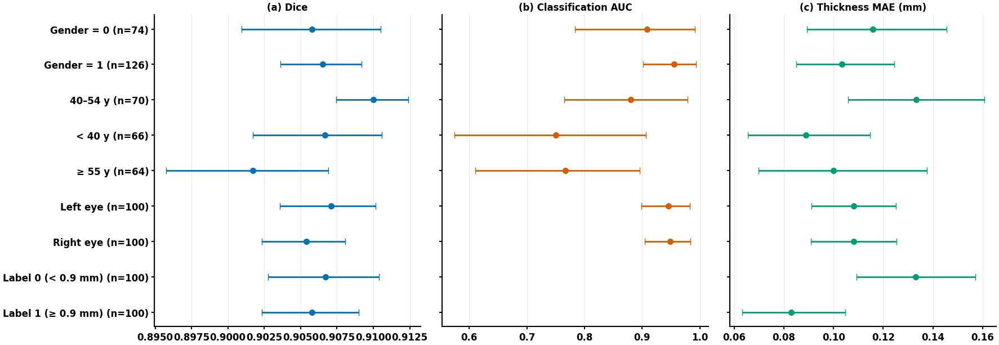

In [20]:
sg = test_df.copy()
for k, v in [("dice", res_test["seg"]["Dice"]), ("p", p_te), ("y", y_te), ("tp", tp_te), ("tt", t_te)]: sg[k] = v
sg["Age group"] = pd.cut(sg["True_age"], [0, 40, 55, 200], labels=["< 40 y", "40–54 y", "≥ 55 y"], right=False).astype(str)
sg["Gender"] = sg["gender"].map({0: "Gender = 0", 1: "Gender = 1"}); sg["Eye"] = sg["eye"].map({"R": "Right eye", "L": "Left eye"})
sg["CIMT class"] = sg["label"].map({0: "Label 0 (< 0.9 mm)", 1: "Label 1 (≥ 0.9 mm)"})
rows, forest = [], []
for fam in ["Gender", "Age group", "Eye", "CIMT class"]:
    for lev in sorted(sg[fam].dropna().unique()):
        d = sg[sg[fam] == lev]; ix = d.index.values
        px = cluster_index(d["patient"].values)
        def f_dice(x): return dict(v=x.mean())
        pt, ci = boot_metrics(f_dice, d["dice"].values, pidx=px)
        r = {"Subgroup": fam, "Level": lev, "Images": len(d), "Patients": d["patient"].nunique(), "Dice": fmt_ci(pt["v"], *ci["v"])}
        auc = np.nan
        if d["y"].nunique() > 1:
            ptc, cic = boot_metrics(lambda y, p: dict(v=roc_auc_score(y, p)), d["y"].values, d["p"].values, strat=d["y"].values, pidx=px)
            r["AUC"] = fmt_ci(ptc["v"], *cic["v"]); auc = (ptc["v"], *cic["v"])
        else:
            r["AUC"] = "–"
        r["Accuracy"] = f"{accuracy_score(d['y'], d['p'] > .5):.3f}"
        ptr, cir = boot_metrics(lambda t, p: dict(v=np.abs(t - p).mean()), d["tt"].values, d["tp"].values, pidx=px)
        r["MAE (mm)"] = fmt_ci(ptr["v"], *cir["v"])
        rows.append(r); forest.append((f"{lev} (n={len(d)})", (pt["v"], *ci["v"]), auc, (ptr["v"], *cir["v"])))
save_table(pd.DataFrame(rows), "T7_subgroups", "Subgroup analysis on the test set (95% patient-level bootstrap CIs).")

fig, ax = plt.subplots(1, 3, figsize=(18, 6.4), sharey=True)
ypos = np.arange(len(forest))[::-1]
for k, (title, idx_) in enumerate([("(a) Dice", 1), ("(b) Classification AUC", 2), ("(c) Thickness MAE (mm)", 3)]):
    for yy, f in zip(ypos, forest):
        v = f[idx_]
        if isinstance(v, float) and np.isnan(v): continue
        ax[k].errorbar(v[0], yy, xerr=[[max(v[0] - v[1], 0)], [max(v[2] - v[0], 0)]], fmt="o", color=CB[k], capsize=4, ms=7)
    ax[k].set_title(title); ax[k].set_yticks(ypos); ax[k].set_yticklabels([f[0] for f in forest]); ax[k].grid(axis="x", alpha=.3)
plt.tight_layout(); save_fig(fig, "F11_subgroups")


## 18. Table 9 and Figure 13 — retinal-vessel biomarkers from the predicted masks vs CIMT
Vessel density, skeleton length density, mean vessel width (area / skeleton length) and box-counting fractal dimension computed inside the field of view; correlated with the true CIMT and compared between CIMT classes.


T9_vessel_biomarkers: Association of vessel biomarkers with CIMT (test set).


,Mask source,Biomarker,Pearson r (CIMT),p (Pearson),Spearman ρ,p (Spearman),AUC for label,Label 0 mean ± SD,Label 1 mean ± SD
0,Predicted masks,Vessel density,-0.219,1.9e-03,-0.299,1.7e-05,0.669,0.131 ± 0.019,0.124 ± 0.016
1,Predicted masks,Skeleton length density,-0.045,5.3e-01,-0.084,2.4e-01,0.557,33.445 ± 5.600,33.133 ± 4.424
2,Predicted masks,Mean width px,-0.397,5.9e-09,-0.423,4.4e-10,0.743,3.953 ± 0.250,3.748 ± 0.195
3,Predicted masks,Fractal dimension,-0.198,4.8e-03,-0.245,4.6e-04,0.633,1.426 ± 0.035,1.415 ± 0.032
4,Reference masks,Vessel density,-0.207,3.3e-03,-0.288,3.6e-05,0.664,0.130 ± 0.019,0.123 ± 0.015
5,Reference masks,Skeleton length density,-0.062,3.8e-01,-0.116,1.0e-01,0.573,33.946 ± 5.579,33.466 ± 4.369
6,Reference masks,Mean width px,-0.332,1.5e-06,-0.323,3.2e-06,0.694,3.843 ± 0.239,3.677 ± 0.188
7,Reference masks,Fractal dimension,-0.180,1.1e-02,-0.226,1.3e-03,0.622,1.424 ± 0.036,1.415 ± 0.030


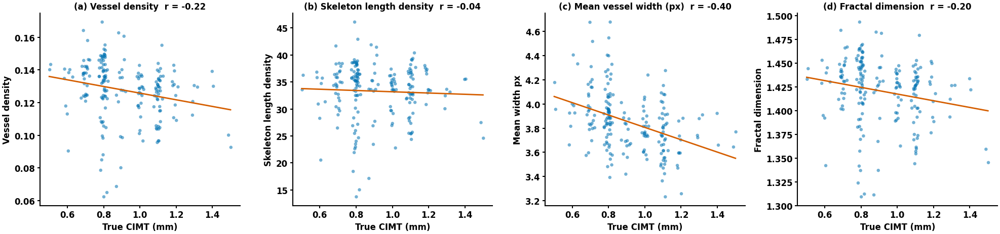

In [21]:
def fractal_dim(m):
    sizes = [2, 4, 8, 16, 32, 64]; counts = []
    for s in sizes:
        H, W = (m.shape[0] // s) * s, (m.shape[1] // s) * s
        blk = m[:H, :W].reshape(H // s, s, W // s, s).any(axis=(1, 3)); counts.append(max(blk.sum(), 1))
    return -np.polyfit(np.log(sizes), np.log(counts), 1)[0]

def vessel_biomarkers(mask, fov):
    mask = mask & fov; area = fov.sum() + 1e-8
    sk = skeletonize(mask); n_sk = sk.sum()
    return dict(Vessel_density=mask.sum() / area, Skeleton_length_density=n_sk / area * 1e3,
                Mean_width_px=mask.sum() / max(n_sk, 1), Fractal_dimension=fractal_dim(mask))

@torch.no_grad()
def collect_masks(model, loader):
    model.eval(); P, G, V = [], [], []
    for imgs, masks, clin, *_ in loader:
        with autocast_ctx():
            out = model(imgs.to(device), clin.to(device))
        P.append((torch.sigmoid(out["seg"].float())[:, 0] > .5).cpu().numpy()); G.append(masks[:, 0].numpy() > .5)
        V.append((imgs.mean(1).numpy() > 0.06))
    return np.concatenate(P), np.concatenate(G), np.concatenate(V)

PM, GM, FOV = collect_masks(model, LD["test"])
bm_pred = pd.DataFrame([vessel_biomarkers(PM[i], FOV[i]) for i in range(len(PM))])
bm_gt   = pd.DataFrame([vessel_biomarkers(GM[i], FOV[i]) for i in range(len(GM))])
rows = []
for src, bm in [("Predicted masks", bm_pred), ("Reference masks", bm_gt)]:
    for c in bm.columns:
        v = bm[c].values; ok = np.isfinite(v)
        pr, pp = stats.pearsonr(v[ok], t_te[ok]); sr, sp = stats.spearmanr(v[ok], t_te[ok])
        auc_b = roc_auc_score(y_te[ok], v[ok]); auc_b = max(auc_b, 1 - auc_b)
        rows.append({"Mask source": src, "Biomarker": c.replace("_", " "), "Pearson r (CIMT)": round(pr, 3), "p (Pearson)": f"{pp:.1e}",
                     "Spearman ρ": round(sr, 3), "p (Spearman)": f"{sp:.1e}", "AUC for label": round(auc_b, 3),
                     "Label 0 mean ± SD": f"{v[ok][y_te[ok] == 0].mean():.3f} ± {v[ok][y_te[ok] == 0].std():.3f}",
                     "Label 1 mean ± SD": f"{v[ok][y_te[ok] == 1].mean():.3f} ± {v[ok][y_te[ok] == 1].std():.3f}"})
save_table(pd.DataFrame(rows), "T9_vessel_biomarkers", "Association of vessel biomarkers with CIMT (test set).")

fig, ax = plt.subplots(1, 4, figsize=(20, 4.9))
for a, c, t_ in zip(ax, ["Vessel_density", "Skeleton_length_density", "Mean_width_px", "Fractal_dimension"],
                    ["(a) Vessel density", "(b) Skeleton length density", "(c) Mean vessel width (px)", "(d) Fractal dimension"]):
    v = bm_pred[c].values
    a.scatter(t_te + np.random.default_rng(2).normal(0, .012, len(t_te)), v, s=22, alpha=.55, color=CB[0], edgecolor="none")
    sl, ic = np.polyfit(t_te, v, 1); xs = np.array([t_te.min(), t_te.max()]); a.plot(xs, sl * xs + ic, color=CB[1])
    a.set_xlabel("True CIMT (mm)"); a.set_ylabel(c.replace("_", " ")); a.set_title(f"{t_}  r = {np.corrcoef(t_te, v)[0, 1]:.2f}")
plt.tight_layout(); save_fig(fig, "F13_biomarkers")


## 19. Table 8 and Figure 12 — robustness to image degradation (no re-training)
The trained model is evaluated on the test set after synthetic degradations of increasing severity.


T8_robustness: Robustness of MT-Swin-UNet to synthetic image degradations (test set).


,Perturbation,Level,Severity,Dice,AUC,Accuracy,MAE (mm),ΔDice,ΔAUC
0,Clean,–,0,0.9063,0.9463,0.845,0.1080,0.0000,0.0000
1,Gaussian noise (σ),0.02,1,0.8774,0.9474,0.845,0.1074,-0.0289,0.0011
2,Gaussian noise (σ),0.05,2,0.7820,0.9488,0.845,0.1061,-0.1243,0.0025
3,Gaussian noise (σ),0.1,3,0.5715,0.9492,0.845,0.1050,-0.3348,0.0029
4,Gaussian blur (σ px),1,1,0.8834,0.9458,0.850,0.1090,-0.0229,-0.0005
5,Gaussian blur (σ px),2,2,0.7883,0.9444,0.840,0.1106,-0.1180,-0.0019
6,Gaussian blur (σ px),4,3,0.3977,0.9432,0.840,0.1133,-0.5086,-0.0031
7,Darkening (×),0.8,1,0.9061,0.9464,0.845,0.1081,-0.0002,0.0001
8,Darkening (×),0.6,2,0.9015,0.9458,0.850,0.1082,-0.0048,-0.0005
9,Darkening (×),0.4,3,0.8621,0.9471,0.850,0.1083,-0.0442,0.0008


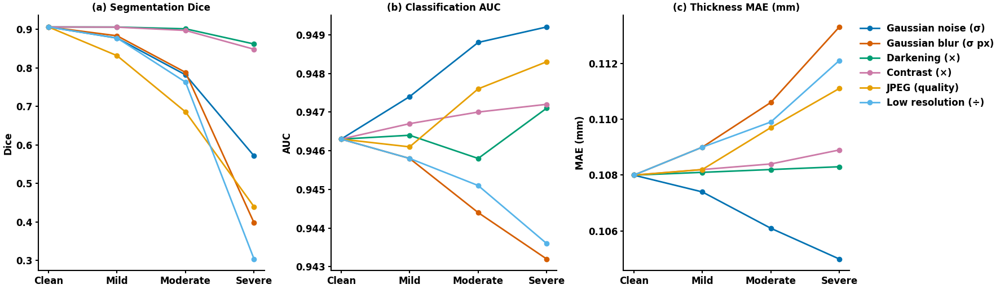

In [22]:
def p_noise(s):  return lambda x: (x + torch.randn_like(x) * s).clamp(0, 1)
def p_blur(sig): return lambda x: TF.gaussian_blur(x, [int(2 * round(3 * sig) + 1)] * 2, [sig, sig])
def p_dark(f):   return lambda x: (x * f).clamp(0, 1)
def p_contrast(f):
    return lambda x: ((x - x.mean((1, 2, 3), keepdim=True)) * f + x.mean((1, 2, 3), keepdim=True)).clamp(0, 1)
def p_lowres(k):
    return lambda x: F.interpolate(F.interpolate(x, scale_factor=1 / k, mode="bilinear", align_corners=False), size=x.shape[-2:], mode="bilinear", align_corners=False)
def p_jpeg(q):
    import io
    def f(x):
        out = []
        for im in x.cpu():
            buf = io.BytesIO(); Image.fromarray((im.permute(1, 2, 0).numpy() * 255).astype(np.uint8)).save(buf, "JPEG", quality=q); buf.seek(0)
            out.append(torch.from_numpy(np.asarray(Image.open(buf).convert("RGB"), dtype=np.float32) / 255.).permute(2, 0, 1))
        return torch.stack(out).to(x.device)
    return f

PERT = {"Gaussian noise (σ)": [(0.02, p_noise(.02)), (0.05, p_noise(.05)), (0.10, p_noise(.10))],
        "Gaussian blur (σ px)": [(1, p_blur(1)), (2, p_blur(2)), (4, p_blur(4))],
        "Darkening (×)": [(0.8, p_dark(.8)), (0.6, p_dark(.6)), (0.4, p_dark(.4))],
        "Contrast (×)": [(0.8, p_contrast(.8)), (0.6, p_contrast(.6)), (0.4, p_contrast(.4))],
        "JPEG (quality)": [(50, p_jpeg(50)), (20, p_jpeg(20)), (10, p_jpeg(10))],
        "Low resolution (÷)": [(2, p_lowres(2)), (4, p_lowres(4)), (8, p_lowres(8))]}
rob_rows = [{"Perturbation": "Clean", "Level": "–", "Severity": 0, "Dice": tm["seg_Dice"], "AUC": tm["cls_AUC"], "Accuracy": tm["cls_ACC"], "MAE (mm)": tm["reg_MAE"]}]
if RUN_ROBUSTNESS:
    for fam, levels in PERT.items():
        for sev, (lv, f) in enumerate(levels, 1):
            torch.manual_seed(0)
            r = summarize(evaluate(model, LD["test"], tf=f))
            rob_rows.append({"Perturbation": fam, "Level": lv, "Severity": sev, "Dice": r["seg_Dice"], "AUC": r["cls_AUC"], "Accuracy": r["cls_ACC"], "MAE (mm)": r["reg_MAE"]})
    rob = pd.DataFrame(rob_rows)
    for c in ["Dice", "AUC", "Accuracy", "MAE (mm)"]: rob[c] = rob[c].astype(float).round(4)
    rob["ΔDice"] = (rob["Dice"] - rob["Dice"].iloc[0]).round(4); rob["ΔAUC"] = (rob["AUC"] - rob["AUC"].iloc[0]).round(4)
    save_table(rob, "T8_robustness", "Robustness of MT-Swin-UNet to synthetic image degradations (test set).")
    fig, ax = plt.subplots(1, 3, figsize=(18, 5.4))
    for k, (met, ttl) in enumerate([("Dice", "(a) Segmentation Dice"), ("AUC", "(b) Classification AUC"), ("MAE (mm)", "(c) Thickness MAE (mm)")]):
        for ci_, fam in enumerate(PERT):
            d = rob[rob["Perturbation"] == fam]
            ax[k].plot([0] + list(d["Severity"]), [rob[met].iloc[0]] + list(d[met]), "o-", color=CB[ci_ % len(CB)], label=fam)
        ax[k].set_xticks([0, 1, 2, 3]); ax[k].set_xticklabels(["Clean", "Mild", "Moderate", "Severe"]); ax[k].set_title(ttl)
    ax[0].set_ylabel("Dice"); ax[1].set_ylabel("AUC"); ax[2].set_ylabel("MAE (mm)")
    ax[2].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
    plt.tight_layout(); save_fig(fig, "F12_robustness")
else:
    print("RUN_ROBUSTNESS = False -> skipped")


## 20. Table 10 and Figure 14 — computational efficiency (all models, no training needed)
Parameters, GFLOPs (PyTorch `FlopCounterMode`, 1 MAC = 2 FLOPs, one 512×512 image), inference latency (batch 1, AMP) and peak GPU memory.

In [23]:
try:
    from torch.utils.flop_counter import FlopCounterMode
except Exception:
    FlopCounterMode = None

def complexity(name, size):
    m = make_model(name, size).to(device).eval()
    n_par = sum(p.numel() for p in m.parameters()) / 1e6
    x = torch.randn(1, 3, size, size, device=device); c = torch.randn(1, 2, device=device)
    gfl = float("nan")
    if FlopCounterMode is not None:
        try:
            with torch.no_grad(), FlopCounterMode(display=False) as fc: m(x, c)
            gfl = fc.get_total_flops() / 1e9
        except Exception as e:
            print("FLOP count failed for", name, "-", e)
    lat = mem = float("nan")
    with torch.no_grad():
        for _ in range(3):
            with autocast_ctx(): m(x, c)
        if device.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        for _ in range(10):
            with autocast_ctx(): m(x, c)
        if device.type == "cuda": torch.cuda.synchronize(); mem = torch.cuda.max_memory_allocated() / 2**20
        lat = (time.time() - t0) / 10 * 1000
    del m; gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()
    return dict(Model=name, **{"Params (M)": n_par, "GFLOPs (512 px)": gfl, "Latency (ms)": lat, "Peak memory (MB)": mem})

COMPLEXITY = None
if RUN_COMPLEXITY:
    sz = 128 if CFG["debug"] else 512
    COMPLEXITY = pd.DataFrame([complexity(n, sz) for n in ALL_MODELS]).round(2)
    save_table(COMPLEXITY, "T10_efficiency", f"Computational cost at {sz}×{sz} input (batch 1, AMP).")
    if len(COMPLEXITY) > 1:
        fig, ax = plt.subplots(1, 3, figsize=(18, 5.4))
        for a, col, ttl in zip(ax, ["Params (M)", "GFLOPs (512 px)", "Latency (ms)"], ["(a) Parameters (M)", "(b) GFLOPs", "(c) Latency (ms)"]):
            cols_ = [CB[1] if n == PROPOSED else CB[6] for n in COMPLEXITY["Model"]]
            a.barh(COMPLEXITY["Model"], COMPLEXITY[col], color=cols_, edgecolor="white")
            for i, v in enumerate(COMPLEXITY[col]): a.text(v, i, f" {v:.1f}", va="center")
            a.set_title(ttl); a.invert_yaxis()
            a.set_xlim(0, np.nanmax(COMPLEXITY[col]) * 1.25)
        ax[1].set_yticklabels([]); ax[2].set_yticklabels([])
        plt.tight_layout(); save_fig(fig, "F14_efficiency")



T10_efficiency: Computational cost at 512×512 input (batch 1, AMP).


,Model,Params (M),GFLOPs (512 px),Latency (ms),Peak memory (MB)
0,MT-Swin-UNet (Proposed),6.89,16.81,23.33,575.97


## 21. Ablation study and baseline comparison (reduced protocol)
All models below are trained **with the same multi-task heads, data split, loss, optimiser, augmentation and budget** (`exp_img_size`, `exp_epochs`), so the comparison is fair.
The training images are decoded once and kept in RAM (`EXP_CACHE_RAM`), which makes the reduced-protocol epochs several times faster.

* **Ablation (`RUN_ABLATION = True`, 14 variants, about 3–3.5 h on a T4, protected by the time budget):** (i) *multi-task design* — segmentation only, +classification, +regression, clinical inputs removed, task-loss weights;
  (ii) *architecture* — no shifted windows, no skip connections, window size, embedding width; (iii) *loss* — Dice-only vs hybrid with λ = 0.5 / 1.0.
* **Baselines:** not run in this version (`BASELINES = []`).
* Every finished model is cached in `q1/exp_results.json` + `q1/preds/*.npz`; a stopped run resumes where it left off, and a later session can pick the cache up through `RESUME_Q1_DIR`.


In [24]:
EXP_IMG, EXP_EP, EXP_BS = CFG["exp_img_size"], CFG["exp_epochs"], CFG["exp_batch_size"]
EXP_LD = None
RUN_TIMES, TIME_SKIPPED, FAILED = [], [], []
FIG_IDX = [int(i) for i in np.linspace(0, len(test_df) - 1, 6)]          # fixed test images for the model-comparison figure
slug = lambda t: re.sub(r"[^A-Za-z0-9]+", "_", t).strip("_")
npz_path = lambda tag: os.path.join(PRED_DIR, slug(tag) + ".npz")
elapsed_h = lambda: (time.time() - SESSION_T0) / 3600

def get_exp_loaders():
    global EXP_LD
    if EXP_LD is None: EXP_LD = make_loaders(EXP_IMG, EXP_BS, cache=EXP_CACHE_RAM)
    return EXP_LD

def run_experiment(tag, builder, w=(1, 1, 1), lam=None, kind="ablation"):
    if tag in RESULTS and os.path.exists(npz_path(tag)):
        print(f"[{tag}] cached"); return
    if not (RUN_ABLATION if kind == "ablation" else RUN_BASELINES):
        print(f"[{tag}] no cached result and RUN_{'ABLATION' if kind == 'ablation' else 'BASELINES'} = False -> skipped"); return
    # ---- time budget: never start a run that could push the session past the limit ----
    est = (float(np.mean(RUN_TIMES)) if RUN_TIMES else 0.30) * (2.2 if "C = 96" in tag else 1.0)
    if elapsed_h() + est + RESERVE_H > TIME_BUDGET_H:
        print(f"[{tag}] SKIPPED by the time budget (elapsed {elapsed_h():.1f} h + ~{est:.1f} h needed + {RESERVE_H} h reserve > {TIME_BUDGET_H} h). "
              f"Re-run the notebook later with RESUME_Q1_DIR to finish the remaining variants.")
        TIME_SKIPPED.append(tag); return
    t_run = time.time()
    try:
        set_seed(CFG["seed"]); ld = get_exp_loaders()
        net = builder().to(device)
        lam_ = CFG["lam"] if lam is None else lam
        crit = MultiTaskLoss(lam_, w[0], w[1], w[2], pos_weight)
        hist, ck = fit(net, tag, ld, EXP_EP, crit, w, ckpt_path=os.path.join(CKPT_DIR, slug(tag) + ".pth"))
        net.load_state_dict(torch.load(ck, map_location=device)); net.eval()
        r = evaluate(net, ld["test"], crit); m = summarize(r)
        viz = []
        with torch.no_grad():
            for i in FIG_IDX:
                img, mask, clin, *_ = ld["test_ds"][i]
                with autocast_ctx(): o = net(img[None].to(device), clin[None].to(device))
                viz.append(torch.sigmoid(o["seg"].float())[0, 0].cpu().numpy().astype(np.float16))
        S_ = r["seg"]
        np.savez_compressed(npz_path(tag), dice=S_["Dice"], iou=S_["IoU"], acc=S_["ACC"], se=S_["SE"], sp=S_["SP"], cls_prob=r["cls_prob"],
                            cls_true=r["cls_true"], reg_pred=r["reg_pred"], reg_true=r["reg_true"], viz=np.stack(viz))
        RESULTS[tag] = dict(metrics={k: float(v) for k, v in m.items()}, params_M=float(sum(p.numel() for p in net.parameters()) / 1e6),
                            train_min=float(hist.attrs.get("train_minutes", float("nan"))), w=[float(x) for x in w], lam=float(lam_),
                            img=EXP_IMG, epochs=EXP_EP, kind=kind)
        json.dump(RESULTS, open(RES_JSON, "w"), indent=1)
        del net
        if os.path.exists(ck): os.remove(ck)
        RUN_TIMES.append((time.time() - t_run) / 3600 / (2.2 if "C = 96" in tag else 1.0))
        print(f"[{tag}] done in {(time.time() - t_run) / 60:.1f} min  ->  Dice {m['seg_Dice']:.4f} | AUC {m['cls_AUC']:.4f} | MAE {m['reg_MAE']:.4f}   "
              f"(session time {elapsed_h():.2f} h)\n")
    except Exception as e:                       # one failing variant (e.g. out-of-memory) must not stop the whole notebook
        import traceback; traceback.print_exc()
        print(f"[{tag}] FAILED ({type(e).__name__}) -> continuing with the next variant\n"); FAILED.append(tag)
    finally:
        gc.collect()
        if device.type == "cuda": torch.cuda.empty_cache()

# ---------------- ablation configurations, in PRIORITY order (the last ones are dropped first if time runs short) ----------------
# (tag, model kwargs, task weights, lambda, group)
ABLATIONS = [(PROPOSED,                                   dict(),                   (1, 1, 1),     None, "Full model"),
             ("Segmentation only (no cls / reg heads)",   dict(),                   (1, 0, 0),     None, "Multi-task design"),
             ("Seg + classification (no regression)",    dict(),                   (1, 1, 0),     None, "Multi-task design"),
             ("Seg + regression (no classification)",     dict(),                   (1, 0, 1),     None, "Multi-task design"),
             ("w/o clinical inputs (image only)",         dict(use_clinical=False), (1, 1, 1),     None, "Multi-task design"),
             ("w/o shifted windows",                      dict(shifted=False),      (1, 1, 1),     None, "Architecture"),
             ("w/o skip connections",                     dict(use_skip=False),     (1, 1, 1),     None, "Architecture"),
             ("Dice-only segmentation loss (λ = 0)",      dict(),                   (1, 1, 1),     0.0,  "Loss"),
             ("Task weights 1 / 0.5 / 0.5",               dict(),                   (1, .5, .5),   None, "Multi-task design"),
             ("Task weights 1 / 2 / 2",                   dict(),                   (1, 2, 2),     None, "Multi-task design"),
             ("Hybrid loss with λ = 1.0",                 dict(),                   (1, 1, 1),     1.0,  "Loss"),
             ("Embedding dim C = 24",                     dict(embed_dim=24),       (1, 1, 1),     None, "Architecture"),
             ("Window size 4",                            dict(window=4),           (1, 1, 1),     None, "Architecture"),
             ("Embedding dim C = 96",                     dict(embed_dim=96),       (1, 1, 1),     None, "Architecture")]
ABL_GROUP = {t: g for t, *_, g in ABLATIONS}
for k_, (tag, kw, w, lam, _g) in enumerate(ABLATIONS, 1):
    print(f"--- ablation {k_}/{len(ABLATIONS)}: {tag}   (session time {elapsed_h():.2f} h)")
    run_experiment(tag, (lambda kw=kw: build_proposed(EXP_IMG, **kw)), w, lam, kind="ablation")
for tag in BASELINES:
    run_experiment(tag, (lambda t=tag: make_model(t, EXP_IMG)), kind="baseline")
print(f"\nablation finished at session time {elapsed_h():.2f} h | cached: {len([k for k in RESULTS])} | "
      f"skipped by time budget: {TIME_SKIPPED or 'none'} | failed: {FAILED or 'none'}")


--- ablation 1/14: MT-Swin-UNet (Proposed)   (session time 2.04 h)
  cached 5206 images at 256px in RAM (1302 MB)
  cached 400 images at 256px in RAM (100 MB)
  cached 200 images at 256px in RAM (50 MB)
[MT-Swin-UNet (Proposed)] Ep 001/15 (65s) loss 1.497/1.700 | Dice 0.5516 | ACC 0.632 AUC 0.740 | MAE 0.1927 R2 -0.111  <- best
[MT-Swin-UNet (Proposed)] Ep 002/15 (64s) loss 1.249/1.382 | Dice 0.6697 | ACC 0.690 AUC 0.797 | MAE 0.1709 R2 0.127  <- best
[MT-Swin-UNet (Proposed)] Ep 003/15 (64s) loss 1.029/1.111 | Dice 0.7139 | ACC 0.780 AUC 0.865 | MAE 0.1378 R2 0.341  <- best
[MT-Swin-UNet (Proposed)] Ep 004/15 (64s) loss 0.949/1.058 | Dice 0.7439 | ACC 0.785 AUC 0.868 | MAE 0.1363 R2 0.361  <- best
[MT-Swin-UNet (Proposed)] Ep 005/15 (65s) loss 0.919/1.032 | Dice 0.7627 | ACC 0.785 AUC 0.869 | MAE 0.1340 R2 0.371  <- best
[MT-Swin-UNet (Proposed)] Ep 006/15 (64s) loss 0.900/1.092 | Dice 0.7692 | ACC 0.785 AUC 0.869 | MAE 0.1393 R2 0.331
[MT-Swin-UNet (Proposed)] Ep 007/15 (64s) loss 0.

### 21.1 Table 11 and Figure 15 — ablation


T11_ablation: Ablation study (256px, 15 epochs, identical protocol; '–' = task not trained).


,Group,Model / variant,Dice,IoU,Sensitivity,Specificity,Cls AUC,Cls ACC,MAE (mm),R²,Params (M),Train (min),Δ Dice,Δ Cls AUC,Δ MAE (mm)
0,Full model,MT-Swin-UNet (Proposed),0.8043,0.6731,0.8202,0.9762,0.9456,0.855,0.1079,0.4753,6.8882,16.1131,0.0000,0.0000,0.0000
1,Multi-task design,Segmentation only (no cls / reg heads),0.8563,0.7491,0.8580,0.9843,NaN,NaN,NaN,NaN,6.8882,16.0888,0.0520,NaN,NaN
2,Multi-task design,Seg + classification (no regression),0.8248,0.7022,0.8213,0.9816,0.9470,0.835,NaN,NaN,6.8882,16.1813,0.0204,0.0013,NaN
3,Multi-task design,Seg + regression (no classification),0.8119,0.6837,0.8199,0.9783,NaN,NaN,0.1065,0.4961,6.8882,16.1700,0.0076,NaN,-0.0014
4,Multi-task design,w/o clinical inputs (image only),0.7774,0.6365,0.7807,0.9752,0.8239,0.735,0.1269,0.2885,6.8882,16.0548,-0.0269,-0.1217,0.0190
5,Architecture,w/o shifted windows,0.8179,0.6923,0.8113,0.9812,0.9482,0.840,0.1093,0.4662,6.8882,15.6940,0.0136,0.0026,0.0014
6,Architecture,w/o skip connections,0.7842,0.6455,0.8022,0.9738,0.9462,0.840,0.1120,0.4419,6.8882,16.0347,-0.0201,0.0006,0.0041
7,Loss,Dice-only segmentation loss (λ = 0),0.7890,0.6521,0.7832,0.9781,0.9474,0.840,0.1068,0.4994,6.8882,16.1094,-0.0153,0.0018,-0.0011
8,Multi-task design,Task weights 1 / 0.5 / 0.5,0.8169,0.6909,0.8431,0.9761,0.9466,0.835,0.1089,0.4755,6.8882,16.2272,0.0126,0.0010,0.0010
9,Multi-task design,Task weights 1 / 2 / 2,0.8022,0.6702,0.7936,0.9798,0.9472,0.855,0.1051,0.5045,6.8882,16.1497,-0.0021,0.0016,-0.0027


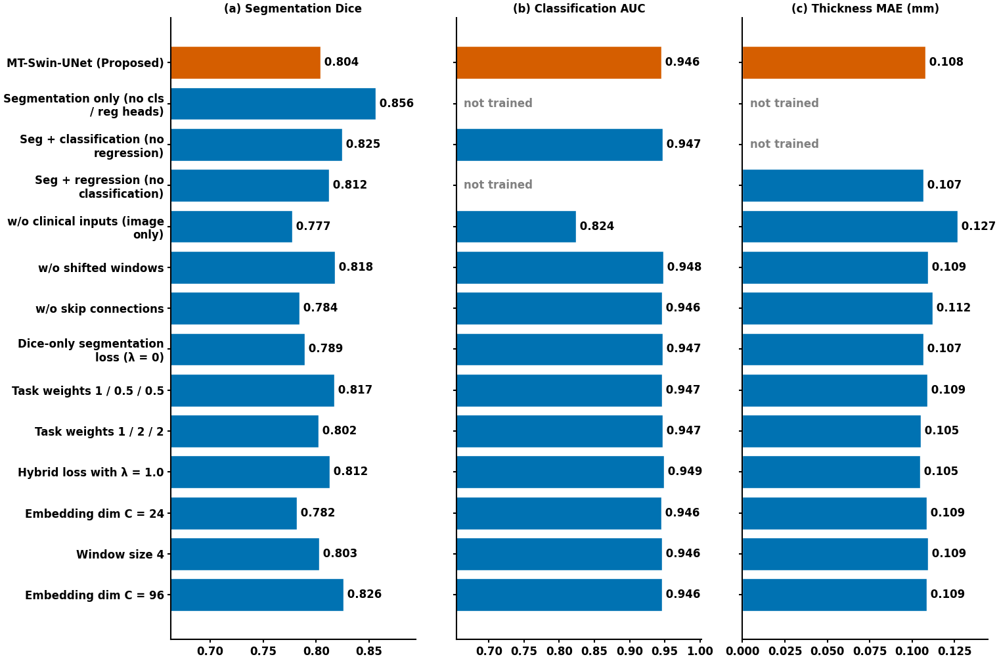

In [25]:
def row_from(tag, extra=None):
    r = RESULTS[tag]; m = r["metrics"]; w = r["w"]
    d = {"Model / variant": tag, "Dice": m["seg_Dice"], "IoU": m["seg_IoU"], "Sensitivity": m["seg_SE"], "Specificity": m["seg_SP"],
         "Cls AUC": m["cls_AUC"] if w[1] > 0 else np.nan, "Cls ACC": m["cls_ACC"] if w[1] > 0 else np.nan,
         "MAE (mm)": m["reg_MAE"] if w[2] > 0 else np.nan, "R²": m["reg_R2"] if w[2] > 0 else np.nan,
         "Params (M)": r["params_M"], "Train (min)": r["train_min"]}
    return d

abl_tags = [a[0] for a in ABLATIONS if a[0] in RESULTS]
ABL_LINES = []
ABL = None
if abl_tags:
    ABL = pd.DataFrame([row_from(t) for t in abl_tags])
    for c, s in [("Dice", 1), ("Cls AUC", 1), ("MAE (mm)", -1)]:
        ABL["Δ " + c] = (ABL[c] - ABL[c].iloc[0]).round(4)
    ABL.insert(0, "Group", ABL["Model / variant"].map(ABL_GROUP))
    save_table(ABL.round(4), "T11_ablation", f"Ablation study ({EXP_IMG}px, {EXP_EP} epochs, identical protocol; '–' = task not trained).")
    import textwrap
    fig, ax = plt.subplots(1, 3, figsize=(15.5, 0.58 * len(ABL) + 2.2), sharey=True)
    for a, col, ttl in zip(ax, ["Dice", "Cls AUC", "MAE (mm)"], ["(a) Segmentation Dice", "(b) Classification AUC", "(c) Thickness MAE (mm)"]):
        v = ABL[col].values; cols_ = [CB[1] if i == 0 else CB[0] for i in range(len(ABL))]
        ok_ = [i for i, x in enumerate(v) if x == x]
        a.barh(ok_, [v[i] for i in ok_], color=[cols_[i] for i in ok_], edgecolor="white")
        for i, x in enumerate(v):
            if x != x: a.text(0.03, i, "not trained", transform=a.get_yaxis_transform(), va="center", color="gray")
            else: a.text(x, i, f" {x:.3f}", va="center")
        a.set_title(ttl); a.set_yticks(range(len(ABL))); a.set_yticklabels([textwrap.fill(s, 26) for s in ABL["Model / variant"]]); a.invert_yaxis()
        lo_ = np.nanmin(v) if np.isfinite(v).any() else 0; hi_ = np.nanmax(v) if np.isfinite(v).any() else 1
        a.set_xlim(max(0, lo_ - (hi_ - lo_) * 1.2 - 0.02) if col != "MAE (mm)" else 0, hi_ + (hi_ - lo_) * 0.35 + 0.01)
    plt.tight_layout(); save_fig(fig, "F15_ablation")
    # ---- auto-generated summary sentences (also printed in the final summary) ----
    for _, r_ in ABL.iloc[1:].iterrows():
        parts = [f"ΔDice {r_['Δ Dice']:+.3f}"]
        if r_["Cls AUC"] == r_["Cls AUC"]: parts.append(f"ΔAUC {r_['Δ Cls AUC']:+.3f}")
        if r_["MAE (mm)"] == r_["MAE (mm)"]: parts.append(f"ΔMAE {r_['Δ MAE (mm)']:+.3f} mm")
        ABL_LINES.append(f"- Ablation · {r_['Model / variant']}: " + ", ".join(parts) + " (vs the full model).")
else:
    print("No ablation results yet (set RUN_ABLATION = True).")


### 21.2 Table 12, Figure 16 and Figure 17 — comparison with baselines

In [26]:
base_tags = [t for t in [PROPOSED] + BASELINES if t in RESULTS]
BASE = None
if len(base_tags) > 1:
    BASE = pd.DataFrame([row_from(t) for t in base_tags]).drop(columns=["Train (min)"])
    if COMPLEXITY is not None:
        BASE = BASE.merge(COMPLEXITY[["Model", "GFLOPs (512 px)", "Latency (ms)"]].rename(columns={"Model": "Model / variant"}), on="Model / variant", how="left")
    save_table(BASE.round(4), "T12_baselines", f"Comparison with baselines trained under the identical multi-task protocol ({EXP_IMG}px, {EXP_EP} epochs).")
    fig, ax = plt.subplots(1, 3, figsize=(20, 5.8), sharey=True)
    for a, col, ttl in zip(ax, ["Dice", "Cls AUC", "MAE (mm)"], ["(a) Segmentation Dice", "(b) Classification AUC", "(c) Thickness MAE (mm)"]):
        v = BASE[col].values; cols_ = [CB[1] if n == PROPOSED else CB[6] for n in BASE["Model / variant"]]
        a.barh(range(len(BASE)), v, color=cols_, edgecolor="white")
        for i, x in enumerate(v): a.text(x, i, f" {x:.3f}", va="center")
        a.set_title(ttl); a.set_yticks(range(len(BASE))); a.set_yticklabels(BASE["Model / variant"]); a.invert_yaxis()
        a.set_xlim(max(0, np.nanmin(v) - (np.nanmax(v) - np.nanmin(v)) * 1.0 - 0.02) if col != "MAE (mm)" else 0, np.nanmax(v) + (np.nanmax(v) - np.nanmin(v)) * 0.4 + 0.01)
    plt.tight_layout(); save_fig(fig, "F16_baselines")

    # ---- Figure 17: qualitative comparison on fixed test images ----
    ld = get_exp_loaders(); ds_ = ld["test_ds"]; show = FIG_IDX[:4]
    fig, ax = plt.subplots(len(show), 2 + len(base_tags), figsize=(2.6 * (2 + len(base_tags)), 2.7 * len(show)))
    for r_i, i in enumerate(show):
        img, mask, *_ = ds_[i]; gt = mask[0].numpy() > .5
        ax[r_i, 0].imshow(img.permute(1, 2, 0).numpy()); ax[r_i, 1].imshow(gt, cmap="gray")
        for c_i, t in enumerate(base_tags):
            pr = np.load(npz_path(t))["viz"][FIG_IDX.index(i)].astype(np.float32) > .5
            e = np.zeros(gt.shape + (3,)); e[gt & pr] = 1; e[~gt & pr] = [1, 0, 0]; e[gt & ~pr] = [0, .4, 1]
            ax[r_i, 2 + c_i].imshow(e)
        for a in ax[r_i]: a.axis("off")
    heads = ["Image", "Reference"] + [t.replace(" (Proposed)", "\n(Proposed)") for t in base_tags]
    for j, h in enumerate(heads): ax[0, j].set_title(h, fontsize=12)
    ax[-1, -1].legend(handles=[Patch(fc="white", ec="k", label="TP"), Patch(fc="red", label="FP"), Patch(fc=(0, .4, 1), label="FN")],
                      loc="upper center", bbox_to_anchor=(-1.5, -0.02), ncol=3)
    plt.tight_layout(); save_fig(fig, "F17_model_comparison_qualitative")
else:
    print("Baselines are not part of this run (BASELINES = []) -> Table 12 / Figures 16-17 skipped.")


Baselines are not part of this run (BASELINES = []) -> Table 12 / Figures 16-17 skipped.


### 21.3 Table 13 — statistical significance against each baseline
Paired tests on the same test images: Wilcoxon signed-rank on per-image Dice; patient-level paired bootstrap for ΔAUC and ΔMAE (two-sided p from the bootstrap distribution); exact McNemar test for classification correctness. Holm–Bonferroni correction across baselines.

In [27]:
def holm(ps):
    ps = np.array(ps, dtype=float); order = np.argsort(ps); out = np.empty_like(ps); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(ps) - rank) * ps[i]); out[i] = min(run, 1.0)
    return out

def paired_boot(fn, A, B, n_boot=None, seed=11, strat=None):
    n_boot = n_boot or CFG["n_boot"]; diffs = []
    for ix in boot_indices(PIDX, n_boot, seed):
        if strat is not None and len(np.unique(strat[ix])) < 2: continue
        diffs.append(fn(*[a[ix] for a in A]) - fn(*[b[ix] for b in B]))
    d = np.array(diffs); p = 2 * min((d <= 0).mean(), (d >= 0).mean()); return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5), max(p, 1.0 / len(d))

auc_fn = lambda y, p: roc_auc_score(y, p)
mae_fn = lambda t, p: np.abs(t - p).mean()
dice_fn = lambda d: d.mean()

STAT = None
if PROPOSED in RESULTS and len(base_tags) > 1:
    P = np.load(npz_path(PROPOSED)); rows = []
    for t in base_tags[1:]:
        B = np.load(npz_path(t))
        w_p = stats.wilcoxon(P["dice"], B["dice"]).pvalue if np.any(P["dice"] != B["dice"]) else 1.0
        dd = paired_boot(dice_fn, (P["dice"],), (B["dice"],))
        da = paired_boot(auc_fn, (P["cls_true"], P["cls_prob"]), (B["cls_true"], B["cls_prob"]), strat=P["cls_true"])
        dm = paired_boot(mae_fn, (P["reg_true"], P["reg_pred"]), (B["reg_true"], B["reg_pred"]))
        cp = (P["cls_prob"] > .5) == (P["cls_true"] > .5); cb = (B["cls_prob"] > .5) == (B["cls_true"] > .5)
        b_, c_ = int((cp & ~cb).sum()), int((~cp & cb).sum())
        p_mc = stats.binomtest(b_, b_ + c_, 0.5).pvalue if (b_ + c_) > 0 else 1.0
        rows.append({"Baseline": t, "ΔDice (P − B)": f"{dd[0]:+.4f} ({dd[1]:+.4f}, {dd[2]:+.4f})", "p Dice (Wilcoxon)": w_p,
                     "ΔAUC (P − B)": f"{da[0]:+.4f} ({da[1]:+.4f}, {da[2]:+.4f})", "p AUC (boot)": da[3],
                     "ΔMAE (P − B)": f"{dm[0]:+.4f} ({dm[1]:+.4f}, {dm[2]:+.4f})", "p MAE (boot)": dm[3],
                     "McNemar b/c": f"{b_}/{c_}", "p ACC (McNemar)": p_mc})
    STAT = pd.DataFrame(rows)
    for col in ["p Dice (Wilcoxon)", "p AUC (boot)", "p MAE (boot)", "p ACC (McNemar)"]:
        STAT[col + " Holm"] = holm(STAT[col].values)
    for col in [c for c in STAT.columns if c.startswith("p ")]: STAT[col] = STAT[col].map(lambda v: f"{v:.4f}" if v >= 1e-4 else "<0.0001")
    save_table(STAT, "T13_significance", "Paired significance tests of the proposed model (P) against each baseline (B); ΔMAE < 0 favours the proposed model.")
else:
    print("Significance tests need cached results of the proposed model and at least one baseline.")


Significance tests need cached results of the proposed model and at least one baseline.


### 21.4 Table 11b — are the ablation differences statistically significant?
Same paired tests as Table 13, now against the full model; variants that did not train a task show “–” for that task.

In [28]:
# ---------------- Table 11b: significance of each ablation against the full model ----------------
ABL_STAT = None
abl_cmp = [a[0] for a in ABLATIONS[1:] if a[0] in RESULTS]
if PROPOSED in RESULTS and abl_cmp:
    Pn = np.load(npz_path(PROPOSED)); rows, raw = [], {"dice": [], "auc": [], "mae": [], "acc": []}
    for t in abl_cmp:
        V = np.load(npz_path(t)); w_ = RESULTS[t]["w"]; r = {"Variant": t}
        w_p = stats.wilcoxon(V["dice"], Pn["dice"]).pvalue if np.any(V["dice"] != Pn["dice"]) else 1.0
        dd = paired_boot(dice_fn, (V["dice"],), (Pn["dice"],))
        r["ΔDice (variant − full)"] = f"{dd[0]:+.4f} ({dd[1]:+.4f}, {dd[2]:+.4f})"; raw["dice"].append(w_p)
        if w_[1] > 0:
            da = paired_boot(auc_fn, (V["cls_true"], V["cls_prob"]), (Pn["cls_true"], Pn["cls_prob"]), strat=Pn["cls_true"])
            r["ΔAUC (variant − full)"] = f"{da[0]:+.4f} ({da[1]:+.4f}, {da[2]:+.4f})"; raw["auc"].append(da[3])
            cv = (V["cls_prob"] > .5) == (V["cls_true"] > .5); cf = (Pn["cls_prob"] > .5) == (Pn["cls_true"] > .5)
            b_, c_ = int((cv & ~cf).sum()), int((~cv & cf).sum())
            raw["acc"].append(stats.binomtest(b_, b_ + c_, 0.5).pvalue if (b_ + c_) > 0 else 1.0)
        else:
            r["ΔAUC (variant − full)"] = "–"; raw["auc"].append(np.nan); raw["acc"].append(np.nan)
        if w_[2] > 0:
            dm = paired_boot(mae_fn, (V["reg_true"], V["reg_pred"]), (Pn["reg_true"], Pn["reg_pred"]))
            r["ΔMAE (variant − full)"] = f"{dm[0]:+.4f} ({dm[1]:+.4f}, {dm[2]:+.4f})"; raw["mae"].append(dm[3])
        else:
            r["ΔMAE (variant − full)"] = "–"; raw["mae"].append(np.nan)
        rows.append(r)
    ABL_STAT = pd.DataFrame(rows)
    for key, col in [("dice", "p Dice (Wilcoxon)"), ("auc", "p AUC (boot)"), ("mae", "p MAE (boot)"), ("acc", "p ACC (McNemar)")]:
        p_ = np.array(raw[key], dtype=float); ok = ~np.isnan(p_); h_ = np.full_like(p_, np.nan); h_[ok] = holm(p_[ok])
        ABL_STAT[col] = [("–" if np.isnan(v) else (f"{v:.4f}" if v >= 1e-4 else "<0.0001")) for v in p_]
        ABL_STAT[col + " Holm"] = [("–" if np.isnan(v) else (f"{v:.4f}" if v >= 1e-4 else "<0.0001")) for v in h_]
    save_table(ABL_STAT, "T11b_ablation_significance",
               "Paired significance of each ablated variant against the full model (Δ = variant − full; for MAE, Δ > 0 means the variant is worse). Holm-corrected across variants.")
else:
    print("Ablation significance needs the cached full model and at least one ablated variant.")



T11b_ablation_significance: Paired significance of each ablated variant against the full model (Δ = variant − full; for MAE, Δ > 0 means the variant is worse). Holm-corrected across variants.


,Variant,ΔDice (variant − full),ΔAUC (variant − full),ΔMAE (variant − full),p Dice (Wilcoxon),p Dice (Wilcoxon) Holm,p AUC (boot),p AUC (boot) Holm,p MAE (boot),p MAE (boot) Holm,p ACC (McNemar),p ACC (McNemar) Holm
0,Segmentation only (no cls / reg heads),"+0.0520 (+0.0510, +0.0529)",–,–,<0.0001,<0.0001,–,–,–,–,–,–
1,Seg + classification (no regression),"+0.0205 (+0.0197, +0.0212)","+0.0013 (-0.0041, +0.0071)",–,<0.0001,<0.0001,0.6340,1.0000,–,–,0.1250,1.0000
2,Seg + regression (no classification),"+0.0076 (+0.0070, +0.0082)",–,"-0.0013 (-0.0039, +0.0013)",<0.0001,<0.0001,–,–,0.3160,0.7520,–,–
3,w/o clinical inputs (image only),"-0.0269 (-0.0282, -0.0258)","-0.1216 (-0.1830, -0.0661)","+0.0190 (+0.0070, +0.0318)",<0.0001,<0.0001,0.0010,0.0110,0.0010,0.0110,0.0001,0.0013
4,w/o shifted windows,"+0.0136 (+0.0130, +0.0142)","+0.0027 (-0.0006, +0.0073)","+0.0014 (+0.0003, +0.0025)",<0.0001,<0.0001,0.1420,1.0000,0.0200,0.1800,0.2500,1.0000
5,w/o skip connections,"-0.0201 (-0.0215, -0.0186)","+0.0006 (-0.0046, +0.0070)","+0.0041 (+0.0020, +0.0061)",<0.0001,<0.0001,0.8640,1.0000,0.0010,0.0110,0.4531,1.0000
6,Dice-only segmentation loss (λ = 0),"-0.0153 (-0.0164, -0.0144)","+0.0018 (-0.0015, +0.0067)","-0.0010 (-0.0042, +0.0021)",<0.0001,<0.0001,0.3200,1.0000,0.5320,0.7520,0.2500,1.0000
7,Task weights 1 / 0.5 / 0.5,"+0.0126 (+0.0121, +0.0132)","+0.0010 (-0.0020, +0.0046)","+0.0010 (-0.0005, +0.0023)",<0.0001,<0.0001,0.5500,1.0000,0.1880,0.7520,0.1250,1.0000
8,Task weights 1 / 2 / 2,"-0.0021 (-0.0028, -0.0014)","+0.0015 (-0.0052, +0.0090)","-0.0028 (-0.0057, +0.0001)",<0.0001,<0.0001,0.5960,1.0000,0.0560,0.4480,1.0000,1.0000
9,Hybrid loss with λ = 1.0,"+0.0082 (+0.0075, +0.0089)","+0.0033 (-0.0005, +0.0090)","-0.0030 (-0.0062, +0.0003)",<0.0001,<0.0001,0.0980,0.9800,0.0860,0.6020,0.2500,1.0000


## 22. External validation — FUNDUS_MASK dataset (Table 14, Figures 18–19)
The trained MT-Swin-UNet is applied **as is** (no fine-tuning, no threshold tuning, fixed 0.5) to an independent public fundus-vessel dataset (`FUNDUS_MASK / Fundus image segmentation`, folders `image/` and `mask/`, files paired by name).
This dataset has **no CIMT labels, age or gender**, so only the **segmentation head** can be validated externally (the model is called with `clinical = None`).
There are no patient identifiers either, hence the 95 % bootstrap CIs are **image-level** (internal test-set CIs stay patient-level).

In [29]:
# ===================== External validation dataset (FUNDUS_MASK) =====================
KEY_LINES = []          # sentences collected by sections 22-26 and printed in the final summary

def _natural(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", s)]

def _index_dir(d):
    return {os.path.splitext(f)[0]: os.path.join(d, f) for f in os.listdir(d)
            if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"))}

EXT_IMG_DIR, EXT_MSK_DIR = os.path.join(EXT_ROOT, "image"), os.path.join(EXT_ROOT, "mask")
EXT_OK = bool(RUN_EXTERNAL and os.path.isdir(EXT_IMG_DIR) and os.path.isdir(EXT_MSK_DIR))

class ExtSegDataset(Dataset):
    """External set: (image, binary mask). Same preprocessing as training: square resize, values in [0, 1]."""
    def __init__(self, names, img_map, msk_map, img_size=512):
        self.names, self.img_map, self.msk_map, self.img_size = names, img_map, msk_map, img_size
    def __len__(self): return len(self.names)
    def __getitem__(self, i):
        n, s = self.names[i], self.img_size
        img = Image.open(self.img_map[n]).convert("RGB").resize((s, s), Image.BILINEAR)
        mk = np.asarray(Image.open(self.msk_map[n]).convert("L").resize((s, s), Image.NEAREST), dtype=np.float32)
        gt = (mk > 0.5 * mk.max()).astype(np.float32) if mk.max() > 0 else np.zeros_like(mk)      # works for 0/1 and 0/255 masks
        x = torch.from_numpy(np.asarray(img, dtype=np.float32) / 255.0).permute(2, 0, 1).contiguous()
        return x, torch.from_numpy(gt).unsqueeze(0)

if not EXT_OK:
    print("External validation skipped: RUN_EXTERNAL is False or the folders were not found:\n ", EXT_IMG_DIR, "\n ", EXT_MSK_DIR)
else:
    _im, _mk = _index_dir(EXT_IMG_DIR), _index_dir(EXT_MSK_DIR)
    EXT_NAMES = sorted(set(_im) & set(_mk), key=_natural)
    print(f"external images: {len(_im)} | masks: {len(_mk)} | paired by file name: {len(EXT_NAMES)}")
    if set(_im) ^ set(_mk): print("  unpaired files ignored:", sorted(set(_im) ^ set(_mk), key=_natural)[:10], "...")
    assert len(EXT_NAMES) > 0, "no image/mask pairs found in the external folders"
    ext_ds = ExtSegDataset(EXT_NAMES, _im, _mk, CFG["img_size"])
    ext_loader = DataLoader(ext_ds, batch_size=CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"], pin_memory=(device.type == "cuda"))
    _i0 = Image.open(_im[EXT_NAMES[0]]); _m0 = Image.open(_mk[EXT_NAMES[0]])
    print(f"first pair: image {_i0.size} {_i0.mode} | mask {_m0.size} {_m0.mode} -> resized to {CFG['img_size']}x{CFG['img_size']}")
    fg = np.mean([ext_ds[i][1].mean().item() for i in range(min(20, len(ext_ds)))])
    print(f"mean foreground fraction of the external masks (first 20): {fg:.3f}   (vessels are normally 5-15 %; > 0.5 would mean an inverted mask)")
    PIDX_EXT = [np.array([i]) for i in range(len(ext_ds))]          # image-level bootstrap (no patient ids available)

external images: 100 | masks: 100 | paired by file name: 100
first pair: image (512, 512) RGB | mask (512, 512) L -> resized to 512x512
mean foreground fraction of the external masks (first 20): 0.088   (vessels are normally 5-15 %; > 0.5 would mean an inverted mask)


In [30]:
# ---------------- inference on the external set (fixed threshold 0.5) + Table 14 ----------------
EXT_THR = np.round(np.arange(0.1, 0.91, 0.1), 2)

@torch.no_grad()
def evaluate_external(model, loader, pix_per_img=4000):
    model.eval(); torch.manual_seed(0)
    seg = {k: [] for k in ("Dice", "IoU", "ACC", "SE", "SP")}; sweep = {float(t): [] for t in EXT_THR}; pp, pt_ = [], []
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        with autocast_ctx():
            out = model(imgs)                                   # clinical = None -> segmentation head only
        lg = out["seg"].float()
        for k, v in per_image_seg(lg, masks).items(): seg[k].append(v)
        for t in EXT_THR: sweep[float(t)].append(per_image_seg(lg, masks, thr=float(t))["Dice"])
        pr = torch.sigmoid(lg).flatten(1); tg = masks.flatten(1)
        ix = torch.randint(0, pr.shape[1], (pix_per_img,), device=pr.device)
        pp.append(pr[:, ix].cpu().numpy().ravel()); pt_.append(tg[:, ix].cpu().numpy().ravel())
    return dict(seg={k: np.concatenate(v) for k, v in seg.items()}, sweep={t: np.concatenate(v) for t, v in sweep.items()},
                pix_prob=np.concatenate(pp), pix_true=np.concatenate(pt_))

if EXT_OK:
    ext_res = evaluate_external(model, ext_loader)
    E = ext_res["seg"]
    pt_e, ci_e = boot_metrics(seg_fn, E["Dice"], E["IoU"], E["ACC"], E["SE"], E["SP"], pidx=PIDX_EXT)
    ext_auc = roc_auc_score(ext_res["pix_true"], ext_res["pix_prob"]); ext_ap = average_precision_score(ext_res["pix_true"], ext_res["pix_prob"])
    key = {"Dice": "Dice", "IoU": "IoU", "Accuracy": "ACC", "Sensitivity": "SE", "Specificity": "SP"}
    c_int, c_ext = f"Internal test, pseudo-reference (n = {len(S['Dice'])})", f"External, ground truth (n = {len(E['Dice'])})"
    rows = []
    for k, kk in key.items():
        mw = stats.mannwhitneyu(S[kk], E[kk], alternative="two-sided").pvalue
        rows.append({"Metric": k, c_int: fmt_ci(pt_s[k], *ci_s[k]), c_ext: fmt_ci(pt_e[k], *ci_e[k]),
                     "Δ (external − internal)": f"{pt_e[k] - pt_s[k]:+.3f}", "p (Mann–Whitney)": f"{mw:.1e}"})
    pix_auc_int = roc_auc_score(res_test["pix_true"], res_test["pix_prob"]); pix_ap_int = average_precision_score(res_test["pix_true"], res_test["pix_prob"])
    rows.append({"Metric": "Pixel AUC", c_int: f"{pix_auc_int:.4f}", c_ext: f"{ext_auc:.4f}", "Δ (external − internal)": f"{ext_auc - pix_auc_int:+.4f}", "p (Mann–Whitney)": "–"})
    rows.append({"Metric": "Pixel AP", c_int: f"{pix_ap_int:.4f}", c_ext: f"{ext_ap:.4f}", "Δ (external − internal)": f"{ext_ap - pix_ap_int:+.4f}", "p (Mann–Whitney)": "–"})
    save_table(pd.DataFrame(rows), "T14_external_validation",
               "External validation of the segmentation head on FUNDUS_MASK (no fine-tuning, threshold 0.5). External CIs are image-level bootstrap; internal CIs patient-level.")
    best_t = max(EXT_THR, key=lambda t: ext_res["sweep"][float(t)].mean())
    print(f"Descriptive threshold sensitivity (NOT used for selection): mean Dice at 0.5 = {ext_res['sweep'][0.5].mean():.4f}; "
          f"best of the grid = {ext_res['sweep'][float(best_t)].mean():.4f} at t = {best_t}")
    KEY_LINES.append(f"- External validation (FUNDUS_MASK, n = {len(E['Dice'])} images, no fine-tuning): Dice {fmt_ci(pt_e['Dice'], *ci_e['Dice'])}, "
                     f"IoU {fmt_ci(pt_e['IoU'], *ci_e['IoU'])}, sensitivity {fmt_ci(pt_e['Sensitivity'], *ci_e['Sensitivity'])}, "
                     f"specificity {fmt_ci(pt_e['Specificity'], *ci_e['Specificity'])}.")


T14_external_validation: External validation of the segmentation head on FUNDUS_MASK (no fine-tuning, threshold 0.5). External CIs are image-level bootstrap; internal CIs patient-level.


,Metric,"Internal test, pseudo-reference (n = 200)","External, ground truth (n = 100)",Δ (external − internal),p (Mann–Whitney)
0,Dice,0.906 (0.904–0.909),0.788 (0.781–0.793),-0.119,3.1e-45
1,IoU,0.829 (0.825–0.833),0.651 (0.643–0.658),-0.178,3.1e-45
2,Accuracy,0.982 (0.981–0.982),0.963 (0.962–0.964),-0.019,2.9e-45
3,Sensitivity,0.911 (0.907–0.914),0.794 (0.783–0.804),-0.117,1.0e-43
4,Specificity,0.989 (0.989–0.990),0.979 (0.979–0.980),-0.010,6.8e-44
5,Pixel AUC,0.9963,0.9780,-0.0182,–
6,Pixel AP,0.9722,0.8651,-0.1071,–


Descriptive threshold sensitivity (NOT used for selection): mean Dice at 0.5 = 0.7875; best of the grid = 0.7877 at t = 0.7


### 22.1 Figure 18 — training sample · external sample · predicted segmentation · ground-truth comparison
Columns 1–2: training images with their (pseudo-)reference masks. Columns 3–6: external images, ground truth, the model's prediction and the TP / FP / FN comparison.

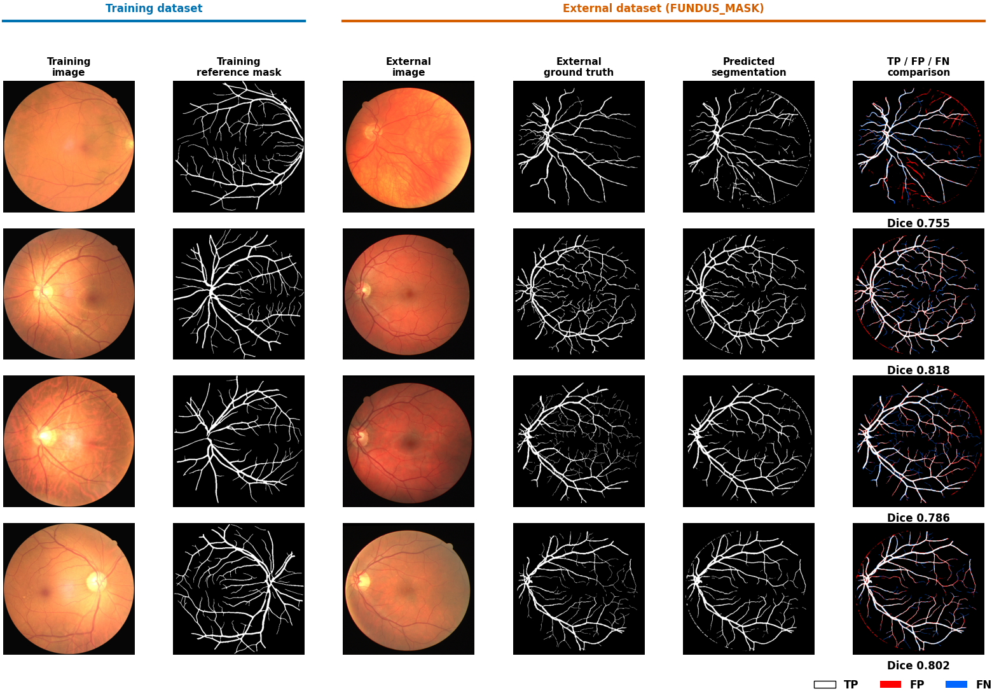

In [31]:
if EXT_OK:
    train_vis = MTDataset(CFG["images_dir"], CFG["masks_dir"], train_df, CFG["img_size"], augment=False)
    rng_v = np.random.default_rng(3); nR = min(4, len(ext_ds))
    tr_idx = rng_v.choice(len(train_vis), nR, replace=False); ex_idx = rng_v.choice(len(ext_ds), nR, replace=False)
    heads = ["Training\nimage", "Training\nreference mask", "External\nimage", "External\nground truth", "Predicted\nsegmentation", "TP / FP / FN\ncomparison"]
    fig, ax = plt.subplots(nR, 6, figsize=(2.7 * 6, 2.75 * nR))
    ax = np.atleast_2d(ax).reshape(nR, 6)
    model.eval()
    for r_i in range(nR):
        img, mask, *_ = train_vis[int(tr_idx[r_i])]
        ax[r_i, 0].imshow(img.permute(1, 2, 0).numpy()); ax[r_i, 1].imshow(mask[0].numpy() > .5, cmap="gray")
        img, mask = ext_ds[int(ex_idx[r_i])]
        with torch.no_grad(), autocast_ctx():
            out = model(img[None].to(device))
        gt = mask[0].numpy() > .5; pred = torch.sigmoid(out["seg"].float())[0, 0].cpu().numpy() > .5
        err = np.zeros(gt.shape + (3,)); err[gt & pred] = 1; err[~gt & pred] = [1, 0, 0]; err[gt & ~pred] = [0, .4, 1]
        d_ = 2 * (gt & pred).sum() / max(gt.sum() + pred.sum(), 1)
        ax[r_i, 2].imshow(img.permute(1, 2, 0).numpy()); ax[r_i, 3].imshow(gt, cmap="gray"); ax[r_i, 4].imshow(pred, cmap="gray"); ax[r_i, 5].imshow(err)
        ax[r_i, 5].text(0.5, -0.04, f"Dice {d_:.3f}", transform=ax[r_i, 5].transAxes, ha="center", va="top")
        for a in ax[r_i]: a.axis("off")
    for j, h in enumerate(heads): ax[0, j].set_title(h, fontsize=11)
    fig.subplots_adjust(left=0.01, right=0.995, top=0.88, bottom=0.06, wspace=0.03, hspace=0.12)
    p0, p1, p2, p3 = ax[0, 0].get_position(), ax[0, 1].get_position(), ax[0, 2].get_position(), ax[0, 5].get_position()
    for x0, x1, txt, c in [(p0.x0, p1.x1, "Training dataset", CB[0]), (p2.x0, p3.x1, "External dataset (FUNDUS_MASK)", CB[1])]:
        fig.add_artist(Line2D([x0, x1], [0.965, 0.965], color=c, lw=3)); fig.text((x0 + x1) / 2, 0.975, txt, ha="center", va="bottom", color=c)
    fig.legend(handles=[Patch(fc="white", ec="k", label="TP"), Patch(fc="red", label="FP"), Patch(fc=(0, .4, 1), label="FN")],
               loc="lower right", ncol=3, bbox_to_anchor=(0.995, -0.005))
    save_fig(fig, "F18_external_samples_predictions")

### 22.2 Figure 19 — external vs internal statistics and domain shift
(a) per-image scores, (b–c) pixel-level ROC / PR, (d) Dice as a function of the binarisation threshold on the external set (descriptive only — the reported result uses 0.5), (e) FOV brightness and (f) vessel fraction of the training set vs the external set (domain shift).

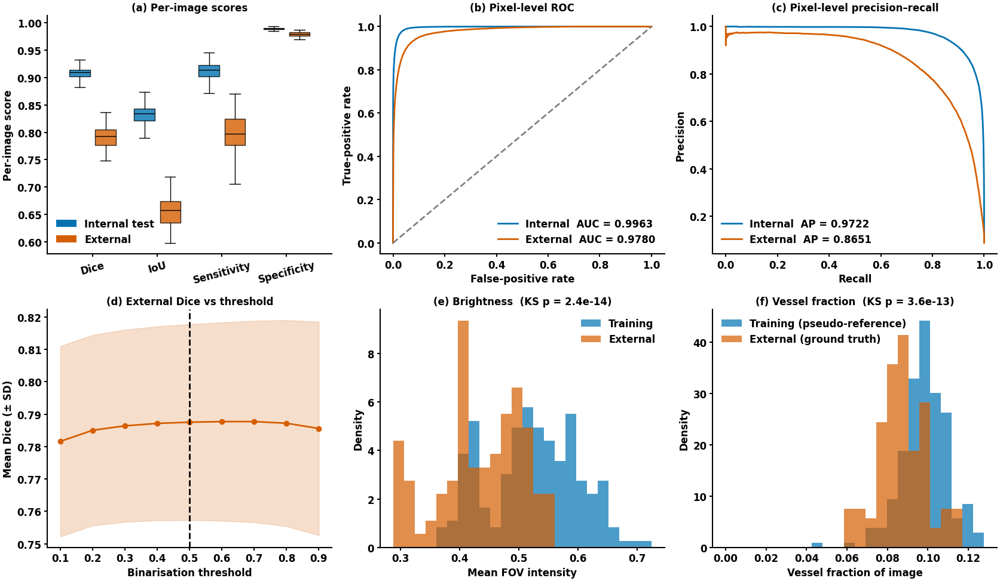

In [32]:
if EXT_OK:
    def quick_stats(pairs, size=128):
        br, vf = [], []
        for ip, mp in pairs:
            im = np.asarray(Image.open(ip).convert("RGB").resize((size, size), Image.BILINEAR), dtype=np.float32) / 255.
            mk = np.asarray(Image.open(mp).convert("L").resize((size, size), Image.NEAREST), dtype=np.float32)
            fov = im.mean(2) > 0.06
            br.append(im[fov].mean() if fov.any() else im.mean()); vf.append(float((mk > 0.5 * mk.max()).mean()) if mk.max() > 0 else 0.0)
        return np.array(br), np.array(vf)

    sub = np.random.default_rng(5).choice(len(train_df), min(200, len(train_df)), replace=False)
    tr_pairs = [(os.path.join(CFG["images_dir"], os.path.splitext(str(train_df.image_name[i]))[0] + ".png"),
                 os.path.join(CFG["masks_dir"], os.path.splitext(str(train_df.image_name[i]))[0] + "_mask.png")) for i in sub]
    br_tr, vf_tr = quick_stats(tr_pairs); br_ex, vf_ex = quick_stats([(_im[n], _mk[n]) for n in EXT_NAMES])

    fig, ax = plt.subplots(2, 3, figsize=(17, 10))
    ax = ax.ravel()
    labs = ["Dice", "IoU", "Sensitivity", "Specificity"]; kk = ["Dice", "IoU", "SE", "SP"]
    for j, (lb, k) in enumerate(zip(labs, kk)):
        for off, arr, c in [(-0.2, S[k], CB[0]), (0.2, E[k], CB[1])]:
            bp = ax[0].boxplot(arr, positions=[j + off], widths=0.32, patch_artist=True, showfliers=False, medianprops=dict(color="k"))
            bp["boxes"][0].set_facecolor(c); bp["boxes"][0].set_alpha(.8)
    ax[0].set_xticks(range(4)); ax[0].set_xticklabels(labs, rotation=15); ax[0].set_ylabel("Per-image score"); ax[0].set_title("(a) Per-image scores")
    ax[0].legend(handles=[Patch(fc=CB[0], label="Internal test"), Patch(fc=CB[1], label="External")], loc="lower left")
    f_i, t_i, _ = roc_curve(res_test["pix_true"], res_test["pix_prob"]); f_e, t_e, _ = roc_curve(ext_res["pix_true"], ext_res["pix_prob"])
    ax[1].plot(f_i, t_i, color=CB[0], label=f"Internal  AUC = {pix_auc_int:.4f}"); ax[1].plot(f_e, t_e, color=CB[1], label=f"External  AUC = {ext_auc:.4f}")
    ax[1].plot([0, 1], [0, 1], "--", color="gray"); ax[1].set_xlabel("False-positive rate"); ax[1].set_ylabel("True-positive rate"); ax[1].set_title("(b) Pixel-level ROC"); ax[1].legend(loc="lower right")
    p_i, r_i_, _ = precision_recall_curve(res_test["pix_true"], res_test["pix_prob"]); p_e, r_e, _ = precision_recall_curve(ext_res["pix_true"], ext_res["pix_prob"])
    ax[2].plot(r_i_, p_i, color=CB[0], label=f"Internal  AP = {pix_ap_int:.4f}"); ax[2].plot(r_e, p_e, color=CB[1], label=f"External  AP = {ext_ap:.4f}")
    ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].set_title("(c) Pixel-level precision–recall"); ax[2].legend(loc="lower left")
    th_ = [float(t) for t in EXT_THR]; m_ = np.array([ext_res["sweep"][t].mean() for t in th_]); s_ = np.array([ext_res["sweep"][t].std() for t in th_])
    ax[3].plot(th_, m_, "o-", color=CB[1]); ax[3].fill_between(th_, m_ - s_, m_ + s_, color=CB[1], alpha=.2)
    ax[3].axvline(0.5, ls="--", color="k"); ax[3].set_xlabel("Binarisation threshold"); ax[3].set_ylabel("Mean Dice (± SD)"); ax[3].set_title("(d) External Dice vs threshold")
    bins = np.linspace(min(br_tr.min(), br_ex.min()), max(br_tr.max(), br_ex.max()), 25)
    ax[4].hist(br_tr, bins=bins, density=True, alpha=.7, color=CB[0], label="Training"); ax[4].hist(br_ex, bins=bins, density=True, alpha=.7, color=CB[1], label="External")
    ax[4].set_xlabel("Mean FOV intensity"); ax[4].set_ylabel("Density"); ax[4].set_title(f"(e) Brightness  (KS p = {stats.ks_2samp(br_tr, br_ex).pvalue:.1e})"); ax[4].legend()
    bins = np.linspace(0, max(vf_tr.max(), vf_ex.max()) * 1.02, 25)
    ax[5].hist(vf_tr, bins=bins, density=True, alpha=.7, color=CB[0], label="Training (pseudo-reference)"); ax[5].hist(vf_ex, bins=bins, density=True, alpha=.7, color=CB[1], label="External (ground truth)")
    ax[5].set_xlabel("Vessel fraction of image"); ax[5].set_ylabel("Density"); ax[5].set_title(f"(f) Vessel fraction  (KS p = {stats.ks_2samp(vf_tr, vf_ex).pvalue:.1e})"); ax[5].legend()
    plt.tight_layout(); save_fig(fig, "F19_external_statistics")

## 23. Qualitative results with attention maps (Figures 20–21)
Best / median / worst / random image by Dice. Columns: image · ground truth · predicted probability · **attention maps of four levels** · error map (TP white, FP red, FN blue).

**Attention maps for the Swin model.** MT-Swin-UNet has no attention gates, so the maps are the model's own *window self-attention*: for every Swin block of a decoder level the softmax attention is averaged over heads and query tokens (= attention *received* by each token), the shifted-window roll is undone, the blocks of the level are averaged, the map is up-sampled to the image size and min–max normalised per image (viridis, 0–1).
Level 3 = bottleneck (H/32), level 2 = decoder stage 3 (H/16), level 1 = decoder stage 2 (H/8), level 0 = decoder stage 1 (H/4).
(If a network returns attention-gate coefficients in `out["att"]`, e.g. Attention U-Net, those are plotted instead.)

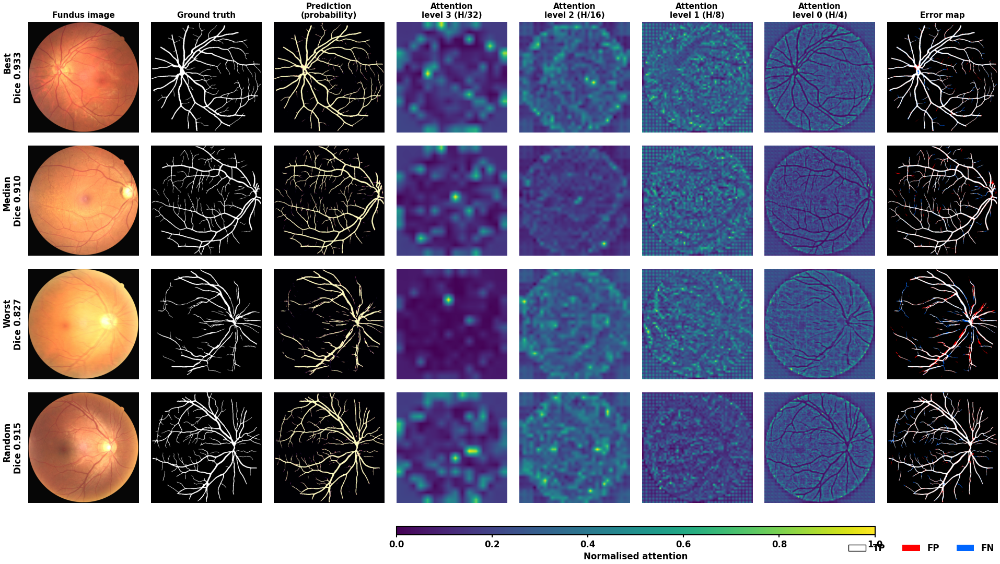

In [33]:
def swin_attention_maps(model, img, clin=None, levels=(3, 2, 1, 0)):
    """Window self-attention received by every token, per decoder level (see section text). Runs one fp32 forward pass."""
    model.eval()
    stage_of = {3: model.bottleneck, 2: model.dec[0], 1: model.dec[1], 0: model.dec[2]}
    store = {l: [] for l in levels}; handles = []

    def make_hook(lvl, blk):
        def hook(m, inp, out):
            x, mask = inp[0], (inp[1] if len(inp) > 1 else None)
            B_, N, C = x.shape
            qkv = m.qkv(x).reshape(B_, N, 3, m.heads, C // m.heads).permute(2, 0, 3, 1, 4)
            attn = (qkv[0] * m.scale) @ qkv[1].transpose(-2, -1)
            attn = attn + m.rel_table[m.rel_index.view(-1)].view(N, N, -1).permute(2, 0, 1).unsqueeze(0)
            if mask is not None:
                nW = mask.shape[0]
                attn = (attn.view(B_ // nW, nW, m.heads, N, N) + mask.unsqueeze(1).unsqueeze(0)).view(-1, m.heads, N, N)
            attn = attn.softmax(-1)
            recv = attn.mean(1).mean(1).reshape(B_, blk.window, blk.window, 1)          # attention received per token
            H, W = blk.res
            sp = window_reverse(recv, blk.window, H, W)
            if blk.shift > 0: sp = torch.roll(sp, shifts=(blk.shift, blk.shift), dims=(1, 2))
            store[lvl].append(sp[0, :, :, 0] * N)                                          # 1.0 = uniform attention
        return hook

    for lvl in levels:
        for blk in stage_of[lvl].blocks: handles.append(blk.attn.register_forward_hook(make_hook(lvl, blk)))
    try:
        with torch.no_grad():
            out = model(img[None].to(device), None if clin is None else clin[None].to(device))
    finally:
        for h in handles: h.remove()
    maps = {}
    for lvl in levels:
        a = torch.stack(store[lvl]).mean(0)[None, None]
        a = F.interpolate(a, size=img.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        maps[lvl] = ((a - a.min()) / (a.max() - a.min() + 1e-8)).cpu().numpy()
    return maps, out

def get_attention(model, img, clin=None, levels=(3, 2, 1, 0)):
    """Attention-gate coefficients if the network provides them (out['att']); otherwise Swin window attention."""
    if hasattr(model, "bottleneck") and hasattr(getattr(model, "bottleneck"), "blocks"):
        return swin_attention_maps(model, img, clin, levels)
    with torch.no_grad(), autocast_ctx():
        out = model(img[None].to(device), None if clin is None else clin[None].to(device))
    maps = {l: out["att"][l][0, 0].float().cpu().numpy() for l in levels if l in out["att"]}
    return maps, out

LEVEL_NAMES = {3: "Attention\nlevel 3 (H/32)", 2: "Attention\nlevel 2 (H/16)", 1: "Attention\nlevel 1 (H/8)", 0: "Attention\nlevel 0 (H/4)"}

def qualitative_attention_figure(get_item, dice_arr, name, rng_seed=0):
    """get_item(i) -> (image tensor 3xHxW, mask tensor 1xHxW, clinical tensor or None)."""
    dice = np.asarray(dice_arr); order = np.argsort(dice); rng = np.random.default_rng(rng_seed)
    picks = [("Best", int(order[-1])), ("Median", int(order[len(order) // 2])), ("Worst", int(order[0])), ("Random", int(rng.integers(len(order))))]
    levels = (3, 2, 1, 0); ncol = 8
    fig, ax = plt.subplots(len(picks), ncol, figsize=(2.45 * ncol, 2.55 * len(picks) + 0.9))
    model.eval(); im_att = None
    for r_i, (tag, idx) in enumerate(picks):
        img, mask, clin = get_item(idx)
        maps, out = get_attention(model, img, clin, levels)
        gt = mask[0].numpy() > 0.5
        prob = torch.sigmoid(out["seg"].float())[0, 0].cpu().numpy(); pred = prob > 0.5
        err = np.zeros(gt.shape + (3,)); err[gt & pred] = 1; err[~gt & pred] = [1, 0, 0]; err[gt & ~pred] = [0, .4, 1]
        ax[r_i, 0].imshow(img.permute(1, 2, 0).numpy()); ax[r_i, 1].imshow(gt, cmap="gray"); ax[r_i, 2].imshow(prob, cmap="magma", vmin=0, vmax=1)
        for c_i, lvl in enumerate(levels):
            if lvl in maps: im_att = ax[r_i, 3 + c_i].imshow(maps[lvl], cmap="viridis", vmin=0, vmax=1)
        ax[r_i, 7].imshow(err)
        for a in ax[r_i]: a.axis("off")
        ax[r_i, 0].text(-0.05, 0.5, f"{tag}\nDice {dice[idx]:.3f}", transform=ax[r_i, 0].transAxes, rotation=90, va="center", ha="right")
    heads = ["Fundus image", "Ground truth", "Prediction\n(probability)"] + [LEVEL_NAMES[l] for l in levels] + ["Error map"]
    for j, h in enumerate(heads): ax[0, j].set_title(h, fontsize=11)
    fig.subplots_adjust(left=0.04, right=0.995, top=0.93, bottom=0.10, wspace=0.03, hspace=0.12)
    if im_att is not None:
        pa, pb = ax[-1, 3].get_position(), ax[-1, 6].get_position()
        cax = fig.add_axes([pa.x0, 0.045, pb.x1 - pa.x0, 0.014]); cb = fig.colorbar(im_att, cax=cax, orientation="horizontal"); cb.set_label("Normalised attention")
    fig.legend(handles=[Patch(fc="white", ec="k", label="TP"), Patch(fc="red", label="FP"), Patch(fc=(0, .4, 1), label="FN")],
               loc="lower right", ncol=3, bbox_to_anchor=(0.995, 0.0))
    save_fig(fig, name)
    return picks

# ---------------- Figure 20: internal test set (the 512-px model, reference = pseudo-labels) ----------------
picks_int = qualitative_attention_figure(lambda i: (test_ds[i][0], test_ds[i][1], test_ds[i][2]), res_test["seg"]["Dice"], "F20_qualitative_attention_internal")

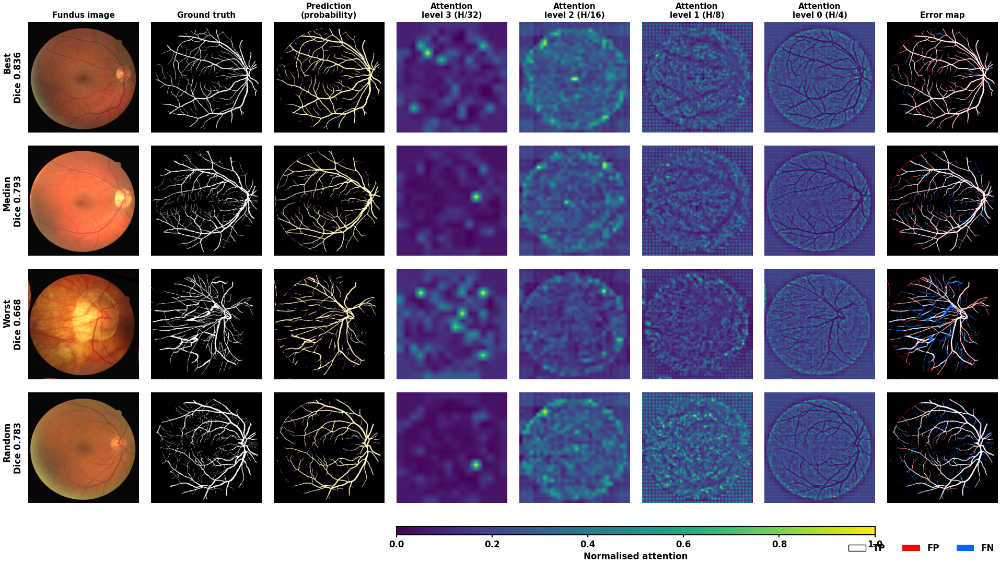

{'Best': '139.png (Dice 0.836)', 'Median': '24.png (Dice 0.793)', 'Worst': '55.png (Dice 0.668)', 'Random': '126.png (Dice 0.783)'}


In [34]:
# ---------------- Figure 21: external set (ground-truth masks) ----------------
if EXT_OK:
    picks_ext = qualitative_attention_figure(lambda i: (ext_ds[i][0], ext_ds[i][1], None), ext_res["seg"]["Dice"], "F21_qualitative_attention_external")
    print({t: f"{EXT_NAMES[i]}.png (Dice {ext_res['seg']['Dice'][i]:.3f})" for t, i in picks_ext})
else:
    print("External set not available -> Figure 21 skipped.")

## 24. Decision-curve analysis (Figure 22, Table 15)
Net benefit  NB(t) = TP/n − FP/n · t/(1 − t)  at threshold probability *t*, compared with **treat-all** (NB = prevalence − (1 − prevalence)·t/(1 − t)) and **treat-none** (NB = 0).
Bands are 95 % patient-level bootstrap intervals; panel (b) shows the gain over the better of the two default strategies, panel (c) the net number of unnecessary interventions avoided per 100 patients relative to treat-all.
A model is clinically useful at thresholds where its net benefit exceeds both default strategies. DCA assumes the predicted probabilities are reasonably calibrated (see Figure 7d, ECE) and is computed on this single-centre test set only.

Prevalence = 0.500
Threshold range with NB(model) > max(treat-all, treat-none): point estimate 0.04–0.95 | 95% CI lower bound > 0: 0.05–0.83, 0.85–0.95

T15_decision_curve: Decision-curve analysis on the test set: net benefit of MT-Swin-UNet vs treat-all / treat-none (95% patient-level bootstrap CI).


,Threshold probability,NB model (95% CI),NB treat-all,NB treat-none,Δ NB vs best default (95% CI),Interventions avoided per 100 vs treat-all (95% CI)
0,0.05,0.476 (0.371–0.571),0.474,0.000,0.002 (0.001–0.004),4.5 (1.0–8.5)
1,0.10,0.459 (0.351–0.559),0.444,0.000,0.014 (0.008–0.022),13.0 (7.0–20.0)
2,0.20,0.421 (0.302–0.529),0.375,0.000,0.046 (0.014–0.073),18.5 (5.5–29.0)
3,0.30,0.394 (0.269–0.514),0.286,0.000,0.109 (0.060–0.153),25.3 (14.0–35.7)
4,0.40,0.393 (0.263–0.513),0.167,0.000,0.227 (0.153–0.293),34.0 (23.0–45.0)
5,0.50,0.345 (0.210–0.475),0.000,0.000,0.345 (0.200–0.385),34.5 (24.0–45.5)
6,0.60,0.360 (0.230–0.485),-0.250,0.000,0.360 (0.230–0.475),40.7 (29.7–51.7)
7,"0.67 (Youden, val.)",0.339 (0.198–0.460),-0.515,0.000,0.339 (0.198–0.460),42.1 (31.1–52.6)
8,0.70,0.358 (0.223–0.475),-0.667,0.000,0.358 (0.223–0.475),43.9 (33.2–54.9)


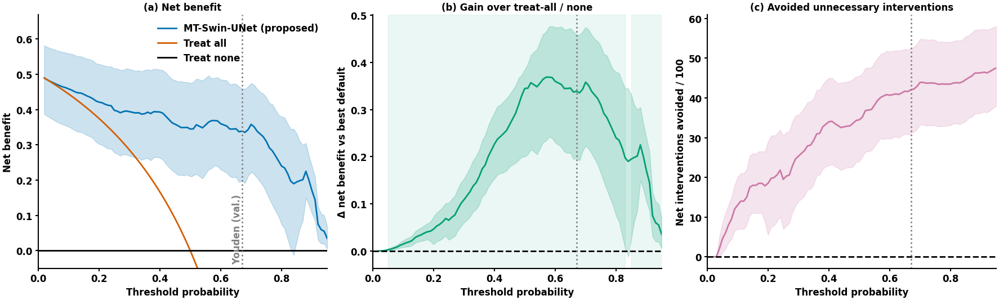

In [35]:
dca_t = np.round(np.arange(0.02, 0.951, 0.01), 2); dca_w = dca_t / (1 - dca_t)

def dca_curves(y, p, t=dca_t):
    y = np.asarray(y).astype(bool); n = len(y); pred = p[:, None] >= t[None, :]
    tp = (pred & y[:, None]).sum(0); fp = (pred & ~y[:, None]).sum(0); w = t / (1 - t); prev_ = y.mean()
    return tp / n - fp / n * w, prev_ - (1 - prev_) * w

nb_m0, nb_a0 = dca_curves(y_te, p_te)
_b = [dca_curves(y_te[ix], p_te[ix]) for ix in boot_indices(PIDX, CFG["n_boot"], 21) if len(np.unique(y_te[ix])) > 1]
NBm, NBa = np.stack([b[0] for b in _b]), np.stack([b[1] for b in _b])
band = lambda A: (np.percentile(A, 2.5, axis=0), np.percentile(A, 97.5, axis=0))
nb_lo, nb_hi = band(NBm)
best_def0 = np.maximum(nb_a0, 0.0); dlt0 = nb_m0 - best_def0
dlt_lo, dlt_hi = band(NBm - np.maximum(NBa, 0.0))
avoid0 = (nb_m0 - nb_a0) / dca_w * 100                               # net interventions avoided per 100 vs treat-all
avoid_lo, avoid_hi = band((NBm - NBa) / dca_w * 100)

def ranges(mask, t):
    out, start = [], None
    for i, m in enumerate(mask):
        if m and start is None: start = i
        if (not m or i == len(mask) - 1) and start is not None:
            end = i if m else i - 1; out.append((t[start], t[end])); start = None
    return out
rng_pt = ranges(dlt0 > 0, dca_t); rng_sig = ranges(dlt_lo > 0, dca_t)
fmt_r = lambda r: ", ".join(f"{a:.2f}–{b:.2f}" for a, b in r) if r else "none"
print(f"Prevalence = {y_te.mean():.3f}")
print("Threshold range with NB(model) > max(treat-all, treat-none): point estimate", fmt_r(rng_pt), "| 95% CI lower bound > 0:", fmt_r(rng_sig))

# ---------------- Table 15 ----------------
sel_t = sorted(set([0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70] + ([round(thr_youden, 2)] if 0.02 <= thr_youden <= 0.95 else [])))
rows = []
for t in sel_t:
    i = int(np.argmin(np.abs(dca_t - t)))
    rows.append({"Threshold probability": f"{dca_t[i]:.2f}" + (" (Youden, val.)" if abs(dca_t[i] - round(thr_youden, 2)) < 1e-9 else ""),
                 "NB model (95% CI)": fmt_ci(nb_m0[i], nb_lo[i], nb_hi[i]), "NB treat-all": f"{nb_a0[i]:.3f}", "NB treat-none": "0.000",
                 "Δ NB vs best default (95% CI)": fmt_ci(dlt0[i], dlt_lo[i], dlt_hi[i]),
                 "Interventions avoided per 100 vs treat-all (95% CI)": f"{avoid0[i]:.1f} ({avoid_lo[i]:.1f}–{avoid_hi[i]:.1f})"})
save_table(pd.DataFrame(rows), "T15_decision_curve", "Decision-curve analysis on the test set: net benefit of MT-Swin-UNet vs treat-all / treat-none (95% patient-level bootstrap CI).")
KEY_LINES.append(f"- Decision-curve analysis: the model has higher net benefit than treat-all and treat-none for thresholds {fmt_r(rng_pt)} (95% CI lower bound above zero for {fmt_r(rng_sig)}).")

# ---------------- Figure 22 ----------------
fig, ax = plt.subplots(1, 3, figsize=(18, 5.6))
ax[0].fill_between(dca_t, nb_lo, nb_hi, color=CB[0], alpha=.2); ax[0].plot(dca_t, nb_m0, color=CB[0], label="MT-Swin-UNet (proposed)")
ax[0].plot(dca_t, nb_a0, color=CB[1], label="Treat all"); ax[0].axhline(0, color="k", label="Treat none")
ax[0].set_ylim(-0.05, max(nb_hi.max(), y_te.mean()) * 1.15); ax[0].set_xlim(0, 0.95)
ax[0].set_xlabel("Threshold probability"); ax[0].set_ylabel("Net benefit"); ax[0].set_title("(a) Net benefit"); ax[0].legend(loc="upper right")
ax[1].fill_between(dca_t, dlt_lo, dlt_hi, color=CB[2], alpha=.2); ax[1].plot(dca_t, dlt0, color=CB[2]); ax[1].axhline(0, color="k", ls="--")
for a_, b_ in rng_sig: ax[1].axvspan(a_, b_, color=CB[2], alpha=.08)
ax[1].set_xlim(0, 0.95); ax[1].set_xlabel("Threshold probability"); ax[1].set_ylabel("Δ net benefit vs best default"); ax[1].set_title("(b) Gain over treat-all / none")
ax[2].fill_between(dca_t, avoid_lo, avoid_hi, color=CB[3], alpha=.2); ax[2].plot(dca_t, avoid0, color=CB[3]); ax[2].axhline(0, color="k", ls="--")
ax[2].set_xlim(0, 0.95); ax[2].set_xlabel("Threshold probability"); ax[2].set_ylabel("Net interventions avoided / 100"); ax[2].set_title("(c) Avoided unnecessary interventions")
for a in ax: a.axvline(thr_youden, ls=":", color="gray")
ax[0].text(thr_youden, ax[0].get_ylim()[0] + 0.005, " Youden (val.)", rotation=90, va="bottom", ha="right", color="gray")
plt.tight_layout(); save_fig(fig, "F22_decision_curve")

## 25. Precision–recall analysis (Figure 23, Table 16, Figure 24)
Precision–recall curve with Average Precision (AP), prevalence baseline, iso-F1 contours and several classification thresholds, plus the precision / recall / F1 / F2 trade-off as a function of the threshold.
The two *data-driven* thresholds — Youden's J and the F1-optimal threshold — are chosen **on the validation set only**; every other threshold is a fixed grid value. Intervals are 95 % patient-level bootstrap.
Precision is undefined (shown as “–”) when a threshold produces no positive prediction.

Validation thresholds -> Youden J: 0.670 | F1-optimal: 0.670 (validation F1 = 0.820)

T16_precision_recall_thresholds: Precision–recall trade-off at different classification thresholds (test set; AP = 0.950 (0.902–0.985)).


,Threshold,Precision (PPV),Recall (sensitivity),F1,F2,Specificity,TP,FP,FN,TN
0,0.10,0.575 (0.481–0.678),1.000 (1.000–1.000),0.730 (0.649–0.808),0.871 (0.822–0.913),0.260 (0.143–0.385),100,74,0,26
1,0.20,0.641 (0.532–0.752),0.980 (0.932–1.000),0.775 (0.689–0.852),0.886 (0.828–0.932),0.450 (0.311–0.585),98,55,2,45
2,0.30,0.706 (0.598–0.808),0.960 (0.898–1.000),0.814 (0.727–0.883),0.896 (0.835–0.942),0.600 (0.465–0.740),96,40,4,60
3,0.40,0.787 (0.682–0.884),0.960 (0.898–1.000),0.865 (0.792–0.926),0.920 (0.863–0.964),0.740 (0.614–0.857),96,26,4,74
4,0.50,0.800 (0.694–0.897),0.920 (0.841–0.981),0.856 (0.776–0.918),0.893 (0.820–0.951),0.770 (0.658–0.886),92,23,8,77
5,0.60,0.897 (0.805–0.977),0.870 (0.783–0.952),0.883 (0.815–0.945),0.875 (0.797–0.946),0.900 (0.812–0.979),87,10,13,90
6,0.70,0.953 (0.882–1.000),0.810 (0.705–0.911),0.876 (0.805–0.942),0.835 (0.743–0.924),0.960 (0.904–1.000),81,4,19,96
7,0.80,0.941 (0.852–1.000),0.640 (0.500–0.769),0.762 (0.649–0.854),0.684 (0.551–0.800),0.960 (0.904–1.000),64,4,36,96
8,0.90,1.000 (1.000–1.000),0.340 (0.214–0.457),0.507 (0.353–0.627),0.392 (0.254–0.512),1.000 (1.000–1.000),34,0,66,100
9,"0.67 (Youden, val.)",0.921 (0.831–0.988),0.820 (0.714–0.918),0.868 (0.795–0.935),0.838 (0.748–0.922),0.930 (0.858–0.990),82,7,18,93


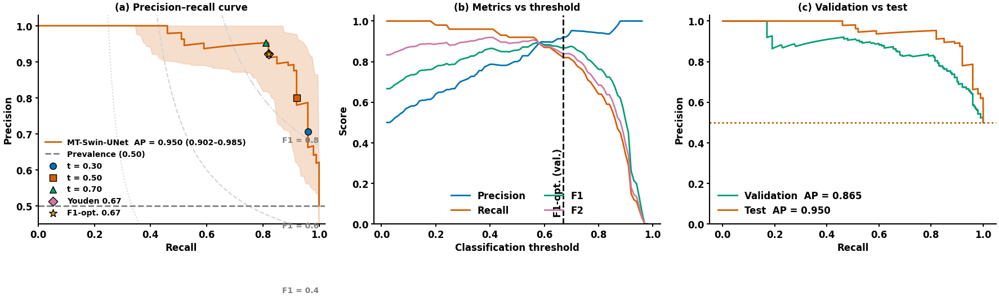

In [36]:
def pr_at(y, p, thrs):
    y = np.asarray(y).astype(bool); pred = p[:, None] >= np.asarray(thrs)[None, :]
    tp = (pred & y[:, None]).sum(0).astype(float); fp = (pred & ~y[:, None]).sum(0).astype(float)
    fn = (~pred & y[:, None]).sum(0).astype(float); tn = (~pred & ~y[:, None]).sum(0).astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        prec = np.where(tp + fp > 0, tp / (tp + fp), np.nan)
        rec = tp / np.maximum(tp + fn, 1); spec = tn / np.maximum(tn + fp, 1)
        f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1); f2 = 5 * tp / np.maximum(5 * tp + 4 * fn + fp, 1)
    return dict(tp=tp, fp=fp, fn=fn, tn=tn, precision=prec, recall=rec, specificity=spec, f1=f1, f2=f2)

# thresholds chosen on VALIDATION only
pv_, rv_, tv_ = precision_recall_curve(yv, pv)
f1v = 2 * pv_[:-1] * rv_[:-1] / np.maximum(pv_[:-1] + rv_[:-1], 1e-12)
thr_f1 = float(tv_[int(np.argmax(f1v))])
print(f"Validation thresholds -> Youden J: {thr_youden:.3f} | F1-optimal: {thr_f1:.3f} (validation F1 = {f1v.max():.3f})")

grid_thr = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
tab_thr = grid_thr + [thr_youden, thr_f1]; tab_lab = [f"{t:.2f}" for t in grid_thr] + [f"{thr_youden:.2f} (Youden, val.)", f"{thr_f1:.2f} (F1-opt., val.)"]
pt0 = pr_at(y_te, p_te, tab_thr)
bs = [pr_at(y_te[ix], p_te[ix], tab_thr) for ix in boot_indices(PIDX, CFG["n_boot"], 31) if len(np.unique(y_te[ix])) > 1]
ci_ = lambda k, j: (np.nanpercentile([b[k][j] for b in bs], 2.5), np.nanpercentile([b[k][j] for b in bs], 97.5)) if not np.all(np.isnan([b[k][j] for b in bs])) else (np.nan, np.nan)
def fmt_n(v, lo, hi): return "–" if np.isnan(v) else fmt_ci(v, lo, hi)
rows = []
for j, lab in enumerate(tab_lab):
    rows.append({"Threshold": lab, "Precision (PPV)": fmt_n(pt0["precision"][j], *ci_("precision", j)), "Recall (sensitivity)": fmt_n(pt0["recall"][j], *ci_("recall", j)),
                 "F1": fmt_ci(pt0["f1"][j], *ci_("f1", j)), "F2": fmt_ci(pt0["f2"][j], *ci_("f2", j)), "Specificity": fmt_ci(pt0["specificity"][j], *ci_("specificity", j)),
                 "TP": int(pt0["tp"][j]), "FP": int(pt0["fp"][j]), "FN": int(pt0["fn"][j]), "TN": int(pt0["tn"][j])})
save_table(pd.DataFrame(rows), "T16_precision_recall_thresholds", f"Precision–recall trade-off at different classification thresholds (test set; AP = {fmt_ci(pt_c['AP'], *ci_c['AP'])}).")
KEY_LINES.append(f"- Precision–recall: AP {fmt_ci(pt_c['AP'], *ci_c['AP'])} (prevalence {y_te.mean():.3f}); at the validation F1-optimal threshold {thr_f1:.2f}: "
                 f"precision {pt0['precision'][-1]:.3f}, recall {pt0['recall'][-1]:.3f}, F1 {pt0['f1'][-1]:.3f}.")

# ---------------- Figure 23 ----------------
prec_t, rec_t, _ = precision_recall_curve(y_te, p_te)
rgrid = np.linspace(0, 1, 201); envs = []
for ix in boot_indices(PIDX, min(CFG["n_boot"], 500), 41):
    if len(np.unique(y_te[ix])) < 2: continue
    pr_b, rc_b, _ = precision_recall_curve(y_te[ix], p_te[ix]); envs.append(np.interp(rgrid, rc_b[::-1], np.maximum.accumulate(pr_b)[::-1]))
env_lo, env_hi = np.percentile(envs, 2.5, axis=0), np.percentile(envs, 97.5, axis=0)

fig, ax = plt.subplots(1, 3, figsize=(18, 5.8))
rr = np.linspace(0.01, 1, 400)
for f_, ls in [(0.4, ":"), (0.6, "--"), (0.8, "-.")]:
    rr_ = rr[rr > f_ / 2]; ax[0].plot(rr_, f_ * rr_ / (2 * rr_ - f_), ls=ls, color="lightgray", lw=1.5); ax[0].text(1.0, f_ / (2 - f_) + 0.005, f"F1 = {f_}", color="gray", ha="right", va="bottom", fontsize=10)
ax[0].fill_between(rgrid, env_lo, env_hi, color=CB[1], alpha=.2)
ax[0].plot(rec_t, prec_t, color=CB[1], label=f"MT-Swin-UNet  AP = {fmt_ci(pt_c['AP'], *ci_c['AP'])}"); ax[0].axhline(y_te.mean(), ls="--", color="gray", label=f"Prevalence ({y_te.mean():.2f})")
mk_t = [0.3, 0.5, 0.7]; mk_lab = [f"t = {t:.2f}" for t in mk_t] + [f"Youden {thr_youden:.2f}", f"F1-opt. {thr_f1:.2f}"]; mk_all = mk_t + [thr_youden, thr_f1]
mk = pr_at(y_te, p_te, mk_all)
for j, (lab, mm) in enumerate(zip(mk_lab, ["o", "s", "^", "D", "*"])):
    if not np.isnan(mk["precision"][j]): ax[0].scatter(mk["recall"][j], mk["precision"][j], marker=mm, s=110 if mm == "*" else 70, color=CB[j % len(CB)], edgecolor="k", zorder=5, label=lab)
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_xlim(0, 1.02); ax[0].set_ylim(max(0, min(prec_t.min(), y_te.mean()) - 0.05), 1.03)
ax[0].set_title("(a) Precision–recall curve"); ax[0].legend(loc="lower left", fontsize=10)

tg = np.linspace(0.02, 0.98, 97); sw = pr_at(y_te, p_te, tg)
for k, c, lb in [("precision", CB[0], "Precision"), ("recall", CB[1], "Recall"), ("f1", CB[2], "F1"), ("f2", CB[3], "F2")]: ax[1].plot(tg, sw[k], color=c, label=lb)
ax[1].axvline(thr_youden, ls=":", color="gray"); ax[1].axvline(thr_f1, ls="--", color="k"); ax[1].text(thr_f1, 0.02, " F1-opt. (val.)", rotation=90, va="bottom", ha="right")
ax[1].set_xlabel("Classification threshold"); ax[1].set_ylabel("Score"); ax[1].set_ylim(0, 1.03); ax[1].set_title("(b) Metrics vs threshold"); ax[1].legend(loc="lower center", ncol=2)

pvv, rvv, _ = precision_recall_curve(yv, pv)
ax[2].plot(rvv, pvv, color=CB[2], label=f"Validation  AP = {average_precision_score(yv, pv):.3f}"); ax[2].plot(rec_t, prec_t, color=CB[1], label=f"Test  AP = {pt_c['AP']:.3f}")
ax[2].axhline(yv.mean(), ls=":", color=CB[2]); ax[2].axhline(y_te.mean(), ls=":", color=CB[1])
ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].set_title("(c) Validation vs test"); ax[2].legend(loc="lower left"); ax[2].set_ylim(0, 1.03)
plt.tight_layout(); save_fig(fig, "F23_precision_recall")

In [37]:
# ---------------- Figure 24: DCA + PR against the baselines (only if cached by section 21) ----------------
cached = {}
for _t in [PROPOSED] + BASELINES:
    if _t in RESULTS and os.path.exists(npz_path(_t)):
        _z = np.load(npz_path(_t))
        if np.array_equal(_z["cls_true"].astype(int), y_te): cached[_t] = _z["cls_prob"]
if len(cached) >= 2:
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.8)); col = {t: CB[i % len(CB)] for i, t in enumerate(cached)}
    for t, p_ in cached.items():
        nb_, _ = dca_curves(y_te, p_); ax[0].plot(dca_t, nb_, color=col[t], lw=3 if t == PROPOSED else 1.8, label=t)
        pr_, rc_, _ = precision_recall_curve(y_te, p_); ax[1].plot(rc_, pr_, color=col[t], lw=3 if t == PROPOSED else 1.8, label=f"{t}  AP = {average_precision_score(y_te, p_):.3f}")
    ax[0].plot(dca_t, nb_a0, color="gray", ls="--", label="Treat all"); ax[0].axhline(0, color="k", label="Treat none")
    ax[0].set_ylim(-0.05, max(y_te.mean(), max(dca_curves(y_te, p_)[0].max() for p_ in cached.values())) * 1.15); ax[0].set_xlim(0, 0.95)
    ax[0].set_xlabel("Threshold probability"); ax[0].set_ylabel("Net benefit"); ax[0].set_title("(a) Decision curves"); ax[0].legend(loc="upper right", fontsize=10)
    ax[1].axhline(y_te.mean(), ls="--", color="gray"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("(b) Precision–recall curves"); ax[1].legend(loc="lower left", fontsize=10)
    fig.suptitle(f"Models trained under the identical reduced protocol ({EXP_IMG} px, {EXP_EP} epochs)", y=1.02)
    plt.tight_layout(); save_fig(fig, "F24_dca_pr_models")
else:
    print("Figure 24 needs cached results of the proposed model and >= 1 baseline (RUN_BASELINES = True in a later session) -> skipped.")

Figure 24 needs cached results of the proposed model and >= 1 baseline (RUN_BASELINES = True in a later session) -> skipped.


## 26. Uncertainty quantification (Figures 25–26, Table 17)
* **Segmentation** — flip test-time augmentation (4 views: identity, horizontal, vertical, both). The mean probability is the prediction; the **predictive entropy** (bits, 0 = certain, 1 = maximal) of the mean is the uncertainty map. We report whether uncertainty tracks the segmentation quality (Spearman ρ between per-image mean entropy and Dice) and whether it flags erroneous pixels (pixel-level AUROC).
* **Classification / regression** — Monte-Carlo dropout (`MC_SAMPLES` stochastic passes). `MC_MODE = "head"` keeps the encoder deterministic and samples the dropout layer of the shared FC head (exact for this model, fast); `MC_MODE = "full"` additionally activates stochastic depth in the whole network (`MC_SAMPLES` full passes over the test set). Uncertainty scores: predictive entropy and the MC standard deviation (epistemic). Selective prediction is summarised by risk–coverage curves and the area under them (AURC; lower is better).

In [38]:
def entropy_bits(p):
    p = p.clamp(1e-6, 1 - 1e-6); return -(p * torch.log2(p) + (1 - p) * torch.log2(1 - p))

@torch.no_grad()
def tta_probs(model, imgs):
    """imgs (B,3,H,W) on device -> probabilities of the 4 flip views, un-flipped: (B,4,H,W)."""
    outs = []
    for fh, fv in [(0, 0), (1, 0), (0, 1), (1, 1)]:
        dims = [d for d, f in ((3, fh), (2, fv)) if f]
        x = torch.flip(imgs, dims) if dims else imgs
        with autocast_ctx():
            o = model(x)["seg"].float()
        p = torch.sigmoid(o)
        outs.append((torch.flip(p, dims) if dims else p)[:, 0])
    return torch.stack(outs, 1)

@torch.no_grad()
def seg_uq_run(model, batches, pix_per_img=3000):
    model.eval(); torch.manual_seed(0)
    d_t, d_1, ent, pe, perr = [], [], [], [], []
    for imgs, masks in batches:
        imgs, masks = imgs.to(device), masks.to(device)
        P4 = tta_probs(model, imgs); pm = P4.mean(1); H_ = entropy_bits(pm)
        gt = masks[:, 0]; pred = (pm > 0.5).float(); p1 = (P4[:, 0] > 0.5).float()
        dice = lambda a: ((2 * (a * gt).flatten(1).sum(1)) / (a.flatten(1).sum(1) + gt.flatten(1).sum(1) + 1e-8)).cpu().numpy()
        d_t.append(dice(pred)); d_1.append(dice(p1))
        fov = (imgs.mean(1) > 0.06).float(); ent.append(((H_ * fov).flatten(1).sum(1) / fov.flatten(1).sum(1).clamp(min=1)).cpu().numpy())
        err = (pred != gt).float().flatten(1); ix = torch.randint(0, err.shape[1], (pix_per_img,), device=err.device)
        pe.append(H_.flatten(1)[:, ix].cpu().numpy().ravel()); perr.append(err[:, ix].cpu().numpy().ravel())
    return dict(dice_tta=np.concatenate(d_t), dice_single=np.concatenate(d_1), ent=np.concatenate(ent), pix_ent=np.concatenate(pe), pix_err=np.concatenate(perr))

def _pairs(loader): return ((b[0], b[1]) for b in loader)
UQ_SEG = {"Internal test": seg_uq_run(model, _pairs(LD["test"]))}
if EXT_OK: UQ_SEG["External"] = seg_uq_run(model, _pairs(ext_loader))

rows = []
for ds_name, u in UQ_SEG.items():
    rho, rp = stats.spearmanr(u["ent"], u["dice_tta"])
    auroc = roc_auc_score(u["pix_err"], u["pix_ent"]) if len(np.unique(u["pix_err"])) > 1 else np.nan
    rows += [{"Task / dataset": f"Segmentation · {ds_name}", "Metric": "Dice, single view → flip-TTA", "Value": f"{u['dice_single'].mean():.4f} → {u['dice_tta'].mean():.4f}"},
             {"Task / dataset": f"Segmentation · {ds_name}", "Metric": "Mean predictive entropy in FOV (bits)", "Value": f"{u['ent'].mean():.4f}"},
             {"Task / dataset": f"Segmentation · {ds_name}", "Metric": "Spearman ρ (mean entropy vs Dice)", "Value": f"{rho:.3f} (p = {rp:.1e})"},
             {"Task / dataset": f"Segmentation · {ds_name}", "Metric": "Pixel AUROC, entropy detects wrong pixels", "Value": f"{auroc:.3f}"}]
    KEY_LINES.append(f"- Segmentation uncertainty ({ds_name}): flip-TTA Dice {u['dice_tta'].mean():.4f}; per-image entropy vs Dice Spearman ρ = {rho:.2f}; pixel-error AUROC {auroc:.3f}.")
UQ_ROWS = rows

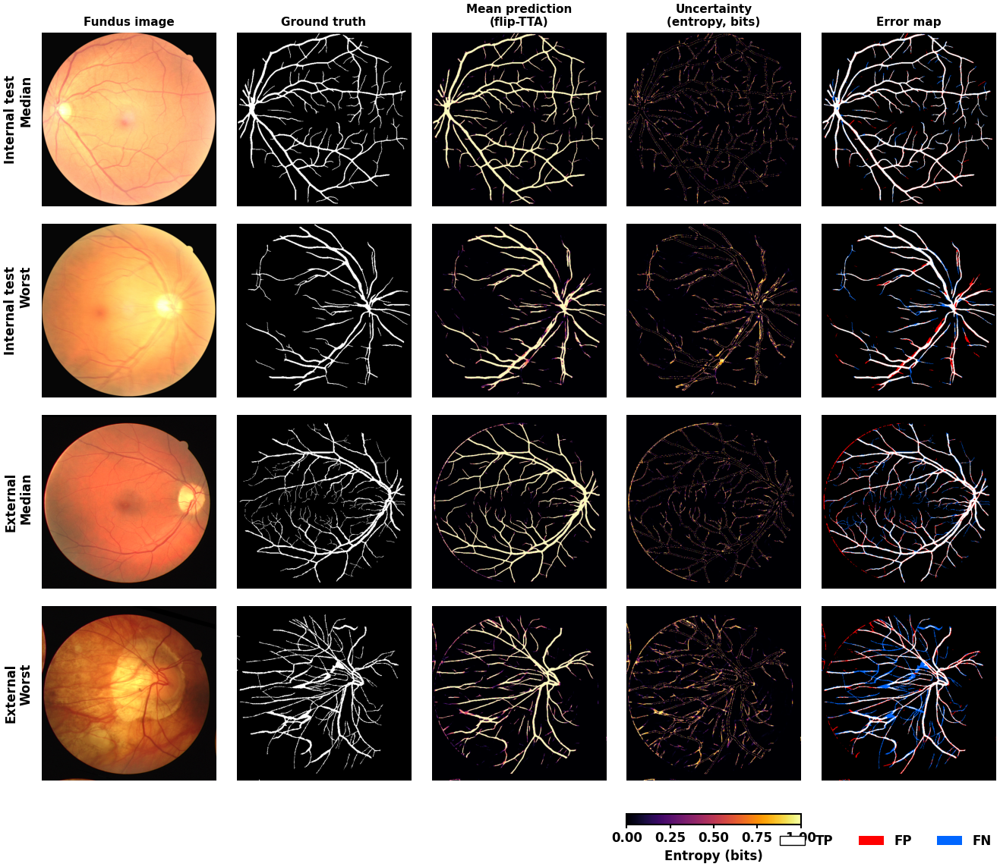

In [39]:
# ---------------- Figure 25: segmentation uncertainty maps ----------------
def uq_rows_for(name, get_item, dice_arr):
    d = np.asarray(dice_arr); o = np.argsort(d); return [(name, "Median", int(o[len(o) // 2]), get_item), (name, "Worst", int(o[0]), get_item)]
items = uq_rows_for("Internal test", lambda i: test_ds[i][:2], UQ_SEG["Internal test"]["dice_tta"])
if EXT_OK: items += uq_rows_for("External", lambda i: ext_ds[i], UQ_SEG["External"]["dice_tta"])
fig, ax = plt.subplots(len(items), 5, figsize=(2.7 * 5, 2.75 * len(items) + 0.6)); ax = np.atleast_2d(ax).reshape(len(items), 5); im_u = None
for r_i, (dsn, tag, idx, getter) in enumerate(items):
    img, mask = getter(idx)
    P4 = tta_probs(model, img[None].to(device)); pm = P4.mean(1)[0]; H_ = entropy_bits(pm).cpu().numpy(); pm = pm.cpu().numpy()
    gt = mask[0].numpy() > .5; pred = pm > .5
    err = np.zeros(gt.shape + (3,)); err[gt & pred] = 1; err[~gt & pred] = [1, 0, 0]; err[gt & ~pred] = [0, .4, 1]
    ax[r_i, 0].imshow(img.permute(1, 2, 0).numpy()); ax[r_i, 1].imshow(gt, cmap="gray"); ax[r_i, 2].imshow(pm, cmap="magma", vmin=0, vmax=1)
    im_u = ax[r_i, 3].imshow(H_, cmap="inferno", vmin=0, vmax=1); ax[r_i, 4].imshow(err)
    for a in ax[r_i]: a.axis("off")
    ax[r_i, 0].text(-0.05, 0.5, f"{dsn}\n{tag}", transform=ax[r_i, 0].transAxes, rotation=90, va="center", ha="right")
for j, h in enumerate(["Fundus image", "Ground truth", "Mean prediction\n(flip-TTA)", "Uncertainty\n(entropy, bits)", "Error map"]): ax[0, j].set_title(h, fontsize=11)
fig.subplots_adjust(left=0.05, right=0.995, top=0.94, bottom=0.09, wspace=0.03, hspace=0.1)
pa = ax[-1, 3].get_position(); cax = fig.add_axes([pa.x0, 0.04, pa.width, 0.012]); fig.colorbar(im_u, cax=cax, orientation="horizontal").set_label("Entropy (bits)")
fig.legend(handles=[Patch(fc="white", ec="k", label="TP"), Patch(fc="red", label="FP"), Patch(fc=(0, .4, 1), label="FN")], loc="lower right", ncol=3, bbox_to_anchor=(0.995, 0.0))
save_fig(fig, "F25_segmentation_uncertainty")


T17_uncertainty: Uncertainty quantification: flip-TTA (segmentation) and Monte-Carlo dropout (classification, regression).


,Task / dataset,Metric,Value
0,Segmentation · Internal test,"Dice, single view → flip-TTA",0.9063 → 0.9084
1,Segmentation · Internal test,Mean predictive entropy in FOV (bits),0.0359
2,Segmentation · Internal test,Spearman ρ (mean entropy vs Dice),-0.032 (p = 6.5e-01)
3,Segmentation · Internal test,"Pixel AUROC, entropy detects wrong pixels",0.973
4,Segmentation · External,"Dice, single view → flip-TTA",0.7875 → 0.7893
5,Segmentation · External,Mean predictive entropy in FOV (bits),0.0416
6,Segmentation · External,Spearman ρ (mean entropy vs Dice),-0.080 (p = 4.3e-01)
7,Segmentation · External,"Pixel AUROC, entropy detects wrong pixels",0.930
8,Classification · MC dropout,Mode / samples,head / 30
9,Classification · MC dropout,"AUC, deterministic → MC mean",0.9463 → 0.9461


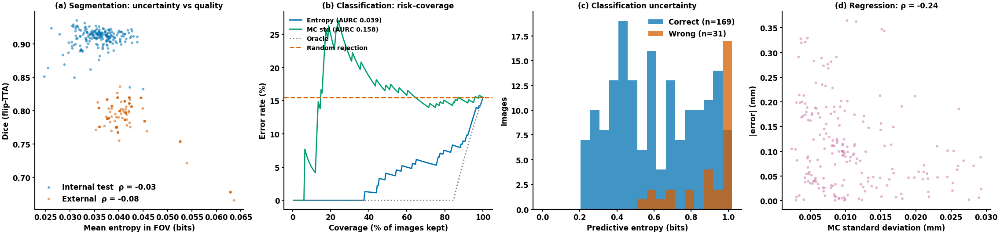

In [40]:
# ---------------- classification / regression uncertainty: Monte-Carlo dropout ----------------
def set_stochastic(module, on=True):
    module.eval()
    if on:
        for m in module.modules():
            if isinstance(m, (nn.Dropout, DropPath)): m.train()

@torch.no_grad()
def mc_predict(model, loader, T=30, mode="head"):
    model.eval(); torch.manual_seed(0); Ps, Rs = [], []
    if mode == "head":                       # encoder is deterministic -> cache the fused feature once, resample only the FC-head dropout
        cache = []
        h = model.shared_fc.register_forward_pre_hook(lambda m, inp: cache.append(inp[0].detach().float()))
        for imgs, masks, clin, labels, thick in loader:
            with autocast_ctx(): model(imgs.to(device), clin.to(device))
        h.remove(); fused = torch.cat(cache); set_stochastic(model.shared_fc, True)
        for _ in range(T):
            hh = model.shared_fc(fused)
            Ps.append(torch.sigmoid(model.cls_head(hh).squeeze(1)).cpu().numpy())
            Rs.append((model.reg_head(hh).squeeze(1) * SCALER["t_sd"] + SCALER["t_mu"]).cpu().numpy())
    else:                                    # full: dropout + stochastic depth everywhere
        for _ in range(T):
            set_stochastic(model, True); p_, r_ = [], []
            for imgs, masks, clin, labels, thick in loader:
                with autocast_ctx(): out = model(imgs.to(device), clin.to(device))
                p_.append(torch.sigmoid(out["cls"].float()).cpu().numpy()); r_.append(out["reg"].float().cpu().numpy() * SCALER["t_sd"] + SCALER["t_mu"])
            Ps.append(np.concatenate(p_)); Rs.append(np.concatenate(r_))
    model.eval()
    return np.stack(Ps), np.stack(Rs)

MCP, MCR = mc_predict(model, LD["test"], MC_SAMPLES, MC_MODE)            # (T, N)
pm_c = MCP.mean(0); sd_c = MCP.std(0)
H_np = lambda p: -(np.clip(p, 1e-6, 1 - 1e-6) * np.log2(np.clip(p, 1e-6, 1 - 1e-6)) + (1 - np.clip(p, 1e-6, 1 - 1e-6)) * np.log2(1 - np.clip(p, 1e-6, 1 - 1e-6)))
ent_c = H_np(pm_c); mi_c = ent_c - H_np(MCP).mean(0)
wrong = ((pm_c >= .5).astype(int) != y_te)
reg_m, reg_sd = MCR.mean(0), MCR.std(0); reg_err = np.abs(reg_m - t_te)

def risk_coverage(score, wrong_):
    o = np.argsort(score, kind="stable"); cum = np.cumsum(wrong_[o]) / np.arange(1, len(o) + 1); return np.arange(1, len(o) + 1) / len(o), cum
cov_e, rk_e = risk_coverage(ent_c, wrong); cov_s, rk_s = risk_coverage(sd_c + 1e-9 * ent_c, wrong); cov_o, rk_o = risk_coverage(wrong.astype(float), wrong)
aurc = lambda r: float(np.mean(r))
def acc_at(cov, rk, c): return 1 - rk[min(int(round(c * len(rk))), len(rk)) - 1]

rows = list(UQ_ROWS)
rows += [{"Task / dataset": "Classification · MC dropout", "Metric": f"Mode / samples", "Value": f"{MC_MODE} / {MC_SAMPLES}"},
         {"Task / dataset": "Classification · MC dropout", "Metric": "AUC, deterministic → MC mean", "Value": f"{roc_auc_score(y_te, p_te):.4f} → {roc_auc_score(y_te, pm_c):.4f}"},
         {"Task / dataset": "Classification · MC dropout", "Metric": "Accuracy, deterministic → MC mean", "Value": f"{accuracy_score(y_te, p_te > .5):.4f} → {1 - wrong.mean():.4f}"},
         {"Task / dataset": "Classification · MC dropout", "Metric": "Mean entropy (bits): correct vs wrong", "Value": f"{ent_c[~wrong].mean():.3f} vs {ent_c[wrong].mean():.3f}" if wrong.any() else f"{ent_c.mean():.3f} (no errors)"},
         {"Task / dataset": "Classification · MC dropout", "Metric": "AUROC for error detection: entropy / MC-std", "Value": (f"{roc_auc_score(wrong, ent_c):.3f} / {roc_auc_score(wrong, sd_c):.3f}" if 0 < wrong.sum() < len(wrong) else "–")},
         {"Task / dataset": "Classification · MC dropout", "Metric": "AURC (entropy / MC-std / random / oracle), lower is better", "Value": f"{aurc(rk_e):.4f} / {aurc(rk_s):.4f} / {wrong.mean():.4f} / {aurc(rk_o):.4f}"}]
for c in (1.0, 0.9, 0.8, 0.7, 0.6, 0.5):
    rows.append({"Task / dataset": "Classification · MC dropout", "Metric": f"Accuracy keeping the {int(c * 100)} % most certain (entropy)", "Value": f"{acc_at(cov_e, rk_e, c):.4f}"})
rho_r, p_r = stats.spearmanr(reg_sd, reg_err)
rows += [{"Task / dataset": "Regression · MC dropout", "Metric": "MAE (mm), deterministic → MC mean", "Value": f"{np.abs(tp_te - t_te).mean():.4f} → {reg_err.mean():.4f}"},
         {"Task / dataset": "Regression · MC dropout", "Metric": "Mean MC std (mm)", "Value": f"{reg_sd.mean():.4f}"},
         {"Task / dataset": "Regression · MC dropout", "Metric": "Spearman ρ (MC std vs |error|)", "Value": f"{rho_r:.3f} (p = {p_r:.1e})"}]
save_table(pd.DataFrame(rows), "T17_uncertainty", "Uncertainty quantification: flip-TTA (segmentation) and Monte-Carlo dropout (classification, regression).")
KEY_LINES.append(f"- Classification uncertainty ({MC_MODE} MC dropout, T = {MC_SAMPLES}): accuracy {1 - wrong.mean():.3f} on all images → {acc_at(cov_e, rk_e, 0.8):.3f} on the 80 % most certain; AURC {aurc(rk_e):.4f} (random {wrong.mean():.4f}).")

# ---------------- Figure 26 ----------------
fig, ax = plt.subplots(1, 4, figsize=(23, 5.6))
for (dsn, u), c in zip(UQ_SEG.items(), [CB[0], CB[1]]):
    r_, _ = stats.spearmanr(u["ent"], u["dice_tta"]); ax[0].scatter(u["ent"], u["dice_tta"], s=18, alpha=.55, color=c, edgecolor="none", label=f"{dsn}  ρ = {r_:.2f}")
ax[0].set_xlabel("Mean entropy in FOV (bits)"); ax[0].set_ylabel("Dice (flip-TTA)"); ax[0].set_title("(a) Segmentation: uncertainty vs quality"); ax[0].legend(loc="lower left")
ax[1].plot(cov_e * 100, rk_e * 100, color=CB[0], label=f"Entropy (AURC {aurc(rk_e):.3f})"); ax[1].plot(cov_s * 100, rk_s * 100, color=CB[2], label=f"MC std (AURC {aurc(rk_s):.3f})")
ax[1].plot(cov_o * 100, rk_o * 100, color="gray", ls=":", label="Oracle"); ax[1].axhline(wrong.mean() * 100, color=CB[1], ls="--", label="Random rejection")
ax[1].set_xlabel("Coverage (% of images kept)"); ax[1].set_ylabel("Error rate (%)"); ax[1].set_title("(b) Classification: risk–coverage"); ax[1].legend(loc="upper left", fontsize=10)
bins = np.linspace(0, max(ent_c.max(), 1e-3) * 1.02, 21)
ax[2].hist(ent_c[~wrong], bins=bins, alpha=.75, color=CB[0], label=f"Correct (n={int((~wrong).sum())})"); ax[2].hist(ent_c[wrong], bins=bins, alpha=.75, color=CB[1], label=f"Wrong (n={int(wrong.sum())})")
ax[2].set_xlabel("Predictive entropy (bits)"); ax[2].set_ylabel("Images"); ax[2].set_title("(c) Classification uncertainty"); ax[2].legend()
ax[3].scatter(reg_sd, reg_err, s=18, alpha=.55, color=CB[3], edgecolor="none"); ax[3].set_xlabel("MC standard deviation (mm)"); ax[3].set_ylabel("|error| (mm)")
ax[3].set_title(f"(d) Regression: ρ = {rho_r:.2f}")
plt.tight_layout(); save_fig(fig, "F26_classification_uncertainty")

## 27. Summary of key results and export
Auto-generated sentences for the manuscript, the Excel workbook of all tables, a figure-DPI check and a zip archive of every figure/table.* **Ablation protocol.** All 14 variants (and the baselines) use the same reduced protocol (256 px, 15 epochs, seed 42, RAM-cached data); the full model is re-trained under that protocol and is the reference of Tables 11 / 11b — it is *not* the 512 px model of Tables 4–9, so do not mix the two sets of numbers in one table.
* **Reading Table 11b.** Δ = variant − full (for MAE, Δ > 0 = worse). A non-significant Δ means the component cannot be shown to matter *on this test set* — say so honestly, or add seeds. Variants without a head (segmentation-only, no regression, no classification) have no value for that task by design.
* **What the ablation groups show.** *Multi-task design* tests whether the auxiliary tasks and the clinical inputs help (or hurt) each other; *architecture* tests the Swin-specific choices (shifted windows, skip connections, window size, width); *loss* tests the hybrid Dice+Focal segmentation loss.


In [41]:
# ---------------- key-result sentences ----------------
print(f"Session time so far: {elapsed_h():.2f} h | ablation variants skipped by the time budget: {TIME_SKIPPED or 'none'} | failed: {FAILED or 'none'}\n")
print("KEY RESULTS (test set, patient-level bootstrap 95% CI)")
print(f"- Segmentation: Dice {fmt_ci(pt_s['Dice'], *ci_s['Dice'])}, IoU {fmt_ci(pt_s['IoU'], *ci_s['IoU'])}, "
      f"sensitivity {fmt_ci(pt_s['Sensitivity'], *ci_s['Sensitivity'])}, specificity {fmt_ci(pt_s['Specificity'], *ci_s['Specificity'])}.")
print(f"- CIMT classification: AUC {fmt_ci(pt_c['AUC'], *ci_c['AUC'])}, accuracy {fmt_ci(pt_c['Accuracy'], *ci_c['Accuracy'])}, "
      f"sensitivity {fmt_ci(pt_c['Sensitivity'], *ci_c['Sensitivity'])}, specificity {fmt_ci(pt_c['Specificity'], *ci_c['Specificity'])}.")
print(f"- CIMT regression: MAE {fmt_ci(pt_r['MAE'], *ci_r['MAE'])} mm, RMSE {fmt_ci(pt_r['RMSE'], *ci_r['RMSE'])} mm, "
      f"R² {fmt_ci(pt_r['R2'], *ci_r['R2'])}, Pearson r {fmt_ci(pt_r['Pearson_r'], *ci_r['Pearson_r'])}.")
print(f"- Model size: {N_PARAMS/1e6:.2f} M parameters.")
for _l in KEY_LINES + globals().get('ABL_LINES', []): print(_l)          # external validation, DCA, precision-recall, uncertainty (sections 22-26)

# ---------------- Excel workbook with every table ----------------
xlsx = os.path.join(QDIR, "q1_tables.xlsx")
with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
    idx = pd.DataFrame([(k, v[0]) for k, v in TABLES.items()], columns=["Sheet", "Caption"])
    idx.to_excel(xw, sheet_name="Index", index=False)
    for k, (cap, df) in TABLES.items(): df.to_excel(xw, sheet_name=k[:31], index=False)
print("\nExcel workbook:", xlsx)

# ---------------- DPI / font check on a saved figure ----------------
chk = sorted(glob.glob(os.path.join(FIG_DIR, "*.png")))
if chk:
    im = Image.open(chk[0]); print(f"DPI check -> {os.path.basename(chk[0])}: {im.size[0]}×{im.size[1]} px, dpi = {im.info.get('dpi')}")
print(f"\n{len(FIG_LOG)} figures: {FIG_LOG}")
print(f"{len(TABLES)} tables: {list(TABLES)}")

# ---------------- zip (figures, tables, predictions; checkpoints excluded) ----------------
zpath = os.path.join(CFG["out_dir"], "q1_outputs")
tmp = os.path.join(CFG["out_dir"], "_q1_pack")
if os.path.exists(tmp): shutil.rmtree(tmp)
shutil.copytree(QDIR, tmp, ignore=shutil.ignore_patterns("ckpt")); shutil.make_archive(zpath, "zip", tmp); shutil.rmtree(tmp)
json.dump(dict(CFG=CFG, SCALER=SCALER, PROPOSED=PROPOSED, env=env), open(os.path.join(CFG["out_dir"], "q1_config.json"), "w"), indent=2)
print("Archive:", zpath + ".zip")


Session time so far: 6.01 h | ablation variants skipped by the time budget: none | failed: none

KEY RESULTS (test set, patient-level bootstrap 95% CI)
- Segmentation: Dice 0.906 (0.904–0.909), IoU 0.829 (0.825–0.833), sensitivity 0.911 (0.907–0.914), specificity 0.989 (0.989–0.990).
- CIMT classification: AUC 0.946 (0.899–0.983), accuracy 0.845 (0.770–0.910), sensitivity 0.920 (0.837–0.981), specificity 0.770 (0.661–0.878).
- CIMT regression: MAE 0.108 (0.091–0.125) mm, RMSE 0.139 (0.119–0.158) mm, R² 0.478 (0.295–0.585), Pearson r 0.746 (0.684–0.805).
- Model size: 6.89 M parameters.
- External validation (FUNDUS_MASK, n = 100 images, no fine-tuning): Dice 0.788 (0.781–0.793), IoU 0.651 (0.643–0.658), sensitivity 0.794 (0.783–0.804), specificity 0.979 (0.979–0.980).
- Decision-curve analysis: the model has higher net benefit than treat-all and treat-none for thresholds 0.04–0.95 (95% CI lower bound above zero for 0.05–0.83, 0.85–0.95).
- Precision–recall: AP 0.950 (0.902–0.985) (prev

## 28. Notes for the manuscript (read before submission)
* **Reference masks are pseudo-labels** (predicted masks). Report segmentation as agreement with the pseudo-reference, or validate on a manually annotated subset (e.g. DRIVE / STARE / CHASE-DB1).
* **Single training seed.** Q1 reviewers often ask for variability across seeds: re-run Section 8 / 21 with `CFG["seed"]` ∈ {42, 43, 44} and report mean ± SD.
* **Two protocols are reported:** the proposed model at full protocol (512 px, 30 epochs; Tables 4–9) and the controlled comparison / ablation at the reduced protocol (Tables 11–13). State this explicitly.
* **No test-set tuning:** checkpoint, operating threshold and all hyper-parameters come from the validation set.
* **Both eyes of a patient** are in the same split and are resampled together in the bootstrap.
* **Literature comparison** (published CIMT-from-fundus results) cannot be generated automatically — add it to Table 12 manually with proper citations and note differences in data / split.
* Figures are 600 dpi PNG + vector PDF (12 pt bold). Tables are CSV + LaTeX (`q1/tables`) and one Excel workbook (`q1/q1_tables.xlsx`).
* **External validation (FUNDUS_MASK).** Only the segmentation head can be validated (no CIMT / age / gender). State the provenance of its masks (manual vs semi-automatic), that the model was applied without fine-tuning at a fixed threshold of 0.5, and that CIs are image-level. The internal scores are agreement with *pseudo*-labels, the external ones with the dataset's reference masks — the two columns of Table 14 are therefore not strictly comparable. Dice-vs-threshold (Fig. 19d) is descriptive only.
* **Attention maps** (Figs. 20–21) are the Swin window self-attention of the decoder levels (attention received per token, averaged over heads / blocks, min–max normalised per image). They show where the transformer looks, not a causal explanation; do not call them attention *gates*.
* **Decision-curve analysis / precision–recall** are single-centre, test-set analyses: DCA presumes calibrated probabilities and a clinically justified threshold range; the Youden and F1-optimal thresholds come from the validation set only. Report prevalence next to AP.
* **Uncertainty.** Flip-TTA captures segmentation uncertainty with respect to input orientation only. `MC_MODE = "head"` samples only the dropout of the shared FC head (encoder deterministic) — use `"full"` (stochastic depth in the whole network) if you want to claim model-wide epistemic uncertainty.
